# 🏘️ 캘리포니아 주택가격 결정요인 분석 — 데이터 준비부터 머신러닝 · SHAP 해석까지

> 1990년 미국 인구조사 기반 캘리포니아 2만여 개 구역(block group)의 주택 데이터로,
> **품질 점검 → EDA → 파생변수 · 공간특성 반영 → 머신러닝 11종 비교 · 튜닝 → 과적합 진단 → SHAP 해석**을 하나의 흐름으로 수행했습니다.
> 총량 변수(방 수 · 인구)를 **비율로 바꾸자 1인당 소득이 가장 강한 변수**가 됐고, **Moran's I = 0.790**으로 확인한 공간 구조를 **위경도 군집(5개 권역)** 으로 변수화했습니다.
> 최종 모델 **CatBoost(변수 7개)** 는 평가 데이터 **R² 0.781**로 일반화 판정을 받았고(교차검증 ↔ 평가 RMSE 차이 0.002),
> SHAP으로 **소득 · 해안 입지 · 공간 권역 세 축이 영향력의 78%** 를 차지한다는 것을 확인했습니다.

| 항목 | 내용 |
|---|---|
| **데이터** | [California Housing Prices (Kaggle)](https://www.kaggle.com/datasets/camnugent/california-housing-prices) · 20,640행 → 결측 처리 후 20,433행 |
| **종속변수** | `median_house_value` 구역별 주택 중위 가격 (모델링에서는 로그 변환) |
| **분석 질문** | ① 이 모형의 예측을 실무에 쓸 수 있는가? ② 주택가격을 좌우하는 요인은 무엇인가? ③ 그 요인은 어느 방향으로, 어떤 모양으로 작동하는가? |
| **주요 기법** | 비율형 파생변수 · Moran's I · K-means 공간 군집 · 회귀 11종(선형 · 비선형 · 앙상블) · GridSearchCV · 과적합 진단 · Feature Importance · SHAP |
| **최종 모델** | CatBoost (depth = 8 · iterations = 1000 · learning_rate = 0.03) · 변수 7개 · RMSE 0.268 · R² 0.781 |

### 📑 목차
0. **준비** — 라이브러리, 데이터 로드, 분석 설정
1. **PART 1. 데이터 품질 점검** — 형식 · 단위 · 중복 · 결측 · 기술통계
2. **PART 2. EDA** — 단변량 → 이변량 → 다변량 → 최종 변수 선택
3. **PART 3. 분석용 데이터 전처리** — 비율형 → 범주형 → 공간특성(Moran's I · 공간 군집) 파생변수 생성
4. **PART 4. 파생변수 검증** — 단변량 → 이변량 → 다변량 → 종합 판단
5. **PART 5. 모델링용 데이터셋** — 로그 변환 · 라벨링
6. **PART 6. 모델링 준비** — 데이터 분할 · 누수 차단
7. **PART 7. 베이스라인 모델 11종** — 기본 설정으로 학습 · 비교
8. **PART 8. 하이퍼파라미터 튜닝** — GridSearchCV · 5-Fold 교차검증
9. **PART 9. 최종 모델 선정**
10. **PART 10. 과적합 판정**
11. **PART 11. Feature Importance · 변수 축소 재학습**
12. **PART 12. SHAP 해석**
13. **📌 결론**

> ⚙️ **사용 모듈** : `my_qtcheck` · `my_plot` · `my_stats` · `my_prep` · `my_cluster` · `my_ml` (helpers) · `geopandas` · `libpysal` · `esda` · `scikit-learn` · `xgboost` · `lightgbm` · `catboost` · `shap` · 데이터 로더 `jussam`

---
# 0. 준비

### (1) 라이브러리 참조

In [1]:
from jussam import load_data
from helpers import *

import warnings
from pandas import DataFrame, set_option
from IPython.display import display, Markdown

# 공간 분석 라이브러리
from geopandas import GeoDataFrame, points_from_xy
from libpysal.weights import Queen, Rook
from esda.moran import Moran

set_option("display.float_format", "{:,.3f}".format)   # 소수점 3자리로 출력
warnings.filterwarnings("ignore", category=FutureWarning)

### (2) 데이터 가져오기

In [2]:
origin = load_data("california_housing")
print(f"데이터 크기 : {origin.shape}")
origin.head()

데이터 크기 : (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.230,37.880,41.000,880.000,129.000,322.000,126.000,8.325,"452,600.000",NEAR BAY
1,-122.220,37.860,21.000,"7,099.000","1,106.000","2,401.000","1,138.000",8.301,"358,500.000",NEAR BAY
2,-122.240,37.850,52.000,"1,467.000",190.000,496.000,177.000,7.257,"352,100.000",NEAR BAY
3,-122.250,37.850,52.000,"1,274.000",235.000,558.000,219.000,5.643,"341,300.000",NEAR BAY
4,-122.250,37.850,52.000,"1,627.000",280.000,565.000,259.000,3.846,"342,200.000",NEAR BAY


### (3) 분석 설정

| 구분 | 변수 | 의미 · 단위 |
|---|---|---|
| 종속변수 | `median_house_value` | 구역별 주택 중위 가격 (USD) |
| 위치 | `longitude` · `latitude` | 경도 · 위도 |
| 주택 | `housing_median_age` | 주택 중위 연령 (년) |
| 규모(총량) | `total_rooms` · `total_bedrooms` · `population` · `households` | 구역 전체의 방 수 · 침실 수 · 인구 · 가구 수 |
| 소득 | `median_income` | 가구 중위 소득 (만 달러) |
| 입지 | `ocean_proximity` | 해양 근접도 (5범주) |

- 한 행은 개별 주택이 아니라 **구역(block group)** 이다. 그래서 규모 변수는 '집 한 채의 방 수'가 아니라 **구역 전체의 합계**다.

In [3]:
target = "median_house_value"      # 종속변수

column_means = {
    "median_house_value": "주택 중위 가격 (USD)",
    "longitude":          "경도",
    "latitude":           "위도",
    "housing_median_age": "주택 중위 연령 (년)",
    "total_rooms":        "총 방 수",
    "total_bedrooms":     "총 침실 수",
    "population":         "인구 (명)",
    "households":         "가구 수",
    "median_income":      "중위 소득 (만 달러)",
    "ocean_proximity":    "해양 근접도",
}

---
# PART 1. 데이터 품질 점검

### (1) 자료형 변환

In [4]:
df1 = my_qtcheck.set_type(origin, as_category=["ocean_proximity"])

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   longitude           20640 non-null  float64 
 1   latitude            20640 non-null  float64 
 2   housing_median_age  20640 non-null  float64 
 3   total_rooms         20640 non-null  float64 
 4   total_bedrooms      20433 non-null  float64 
 5   population          20640 non-null  float64 
 6   households          20640 non-null  float64 
 7   median_income       20640 non-null  float64 
 8   median_house_value  20640 non-null  float64 
 9   ocean_proximity     20640 non-null  category
dtypes: category(1), float64(9)
memory usage: 1.4 MB


### (2) 형식 · 표기 · 단위 점검

- 연속형 변수의 최솟값 · 최댓값으로 **단위와 범위가 상식적인지** 확인한다.

In [5]:
num_fields = ["housing_median_age", "total_rooms", "total_bedrooms", "population",
              "households", "median_income", "median_house_value"]

DataFrame({"min": df1[num_fields].min(), "max": df1[num_fields].max()})

,min,max
housing_median_age,1.000,52.000
total_rooms,2.000,"39,320.000"
total_bedrooms,1.000,"6,445.000"
population,3.000,"35,682.000"
households,1.000,"6,082.000"
median_income,0.500,15.000
median_house_value,"14,999.000","500,001.000"


In [6]:
# 명목형 변수의 범주 표기 확인
df1["ocean_proximity"].value_counts().rename("빈도").to_frame()

,빈도
ocean_proximity,
<1H OCEAN,9136
INLAND,6551
NEAR OCEAN,2658
NEAR BAY,2290
ISLAND,5


---
##### 💡 인사이트 — 형식 · 단위 점검

- 모든 연속형 변수의 최솟값이 0보다 커서, **0이나 음수 같은 불가능한 값은 없다.**
- 종속변수 `median_house_value`의 최댓값이 **500,001달러**로, 50만 달러 바로 위의 어색한 값이다. '50만 달러 초과'를 하나로 묶어 기록한 **상한 절단**일 수 있다.
  - → 최댓값에 값이 몰려 있는지는 단변량 분석에서 확인한다. 다른 변수도 같은 방식으로 점검한다.
- `ocean_proximity`는 5개 범주이고 표기 오류는 없다. 다만 `ISLAND`가 **5건**뿐이다.

---

### (3) 중복 · 결측치 점검

In [7]:
df2 = my_qtcheck.check_duplicates(data=df1)
my_qtcheck.check_missing_values(df2)

중복된 행의 수: 0


,Missing Count,Missing Ratio (%)
longitude,0,0.000
latitude,0,0.000
housing_median_age,0,0.000
total_rooms,0,0.000
total_bedrooms,207,1.003
population,0,0.000
households,0,0.000
median_income,0,0.000
median_house_value,0,0.000
ocean_proximity,0,0.000


### (4) 결측치 처리

- `total_bedrooms`의 결측은 207건(1.0%)으로 5% 미만이라, **결측 행을 삭제**한다. 추정값을 만들지 않아도 된다.

In [8]:
df3 = my_prep.replace_missing(df2, columns=["total_bedrooms"], method="drop")
my_qtcheck.check_missing_values(df3)

결측치 처리 방식: 'drop' (대상 컬럼 1개)
행 수: 20640개 -> 20433개 (207개 삭제)


,Missing Count,Missing Ratio (%)
longitude,0,0.000
latitude,0,0.000
housing_median_age,0,0.000
total_rooms,0,0.000
total_bedrooms,0,0.000
population,0,0.000
households,0,0.000
median_income,0,0.000
median_house_value,0,0.000
ocean_proximity,0,0.000


### (5) 기술통계량

- 여기서 만든 기술통계 표는 PART 2 단변량 분석에서 변수별로 다시 활용한다.

In [9]:
cat_desc = my_qtcheck.categorical_summary(df3, value_counts=False)
display(cat_desc)

num_desc = my_qtcheck.numerical_summary(df3)
num_desc.T

,ocean_proximity
count,20433
unique,5
top,<1H OCEAN
freq,9034


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,"20,433.000","20,433.000","20,433.000","20,433.000","20,433.000","20,433.000","20,433.000","20,433.000","20,433.000"
mean,-119.571,35.633,28.633,"2,636.504",537.871,"1,424.947",499.433,3.871,"206,864.413"
std,2.004,2.136,12.592,"2,185.270",421.385,"1,133.208",382.299,1.899,"115,435.667"
min,-124.350,32.540,1.000,2.000,1.000,3.000,1.000,0.500,"14,999.000"
25%,-121.800,33.930,18.000,"1,450.000",296.000,787.000,280.000,2.564,"119,500.000"
50%,-118.490,34.260,29.000,"2,127.000",435.000,"1,166.000",409.000,3.537,"179,700.000"
75%,-118.010,37.720,37.000,"3,143.000",647.000,"1,722.000",604.000,4.744,"264,700.000"
max,-114.310,41.950,52.000,"39,320.000","6,445.000","35,682.000","6,082.000",15.000,"500,001.000"
rel_diff,-0.009,0.040,0.013,0.240,0.236,0.222,0.221,0.095,0.151
rdiff_flag,similar,similar,similar,diff,diff,diff,diff,similar,diff


---
##### 💡 인사이트 — 품질 점검

| 점검 항목 | 결과 |
|---|---|
| 중복 | 0건 |
| 결측 | `total_bedrooms` 207건(1.0%) → **행 삭제** (20,640 → 20,433행) |
| 형식 · 단위 | 불가능한 값 없음. 최댓값 3종이 상한 절단 의심 |

- 기술통계에서 **규모 변수 4종(방 수 · 침실 수 · 인구 · 가구 수)** 은 평균이 중앙값보다 22~24% 크고, 종속변수인 주택 가격도 15% 크다. 모두 오른쪽 꼬리가 긴 그래프이다.
- **이상치는 모두 위쪽에만** 있다(하한 이상치 전 변수 0%). 이후 분석은 위쪽 꼬리 처리(로그 변환 · 비율형 파생변수 · 절단 인지)에 집중한다.

---

# PART 2. 탐색적 데이터 분석(EDA)

### (1) 변수 유형 분류

- 위도 · 경도는 **두 값이 함께 만드는 좌표**라, 상관계수 · 왜도처럼 변수를 하나씩 보는 진단으로는 신호를 잡을 수 없다. 그래서 일반 연속형 분석에서는 제외하고, PART 3에서 **공간특성 변수**로 다시 만든다.

In [10]:
df = df3.copy()

exclude_cols = ["longitude", "latitude"]    # 좌표 변수 : 공간특성으로 따로 다룬다

nominal_cols = my_qtcheck.get_categorical_column_names(df)
continuous_cols = my_qtcheck.get_number_column_names(df)
continuous_cols.remove(target)

continuous_cols = [c for c in continuous_cols if c not in exclude_cols]
nominal_cols = [c for c in nominal_cols if c not in exclude_cols]

print("종속변수 :", target)
print("명목형   :", nominal_cols)
print("연속형   :", continuous_cols)
print("제외     :", exclude_cols)

종속변수 : median_house_value
명목형   : ['ocean_proximity']
연속형   : ['housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']
제외     : ['longitude', 'latitude']


### (2) EDA 범위 정리

| 종속유형 | 독립유형 | 분석 유형 | 대상 변수 | 적용 | 비고 |
|---|---|---|---|---|---|
| **연속형** | **연속형** | **상관분석** | 연속형 독립변수 6종 → `median_house_value` | ✅ 적용 | |
| 연속형 | 명목형(2집단) | T검정 | — | ❌ 미적용 | 2집단 범주형 없음 |
| **연속형** | **명목형(3집단+)** | **ANOVA** | `ocean_proximity` → `median_house_value` | ✅ 적용 | 5집단 |
| 명목형 | — | T검정 · 교차분석 · ANOVA | — | ❌ 미적용 | 종속변수가 연속형 |

- 위도 · 경도는 일반 연속형 분석에서 제외하고, PART 3에서 **공간자기상관 검정 → 좌표 군집화**로 다룬다.

## 2-1. 단변량 분석

### (1) 종속변수 분포

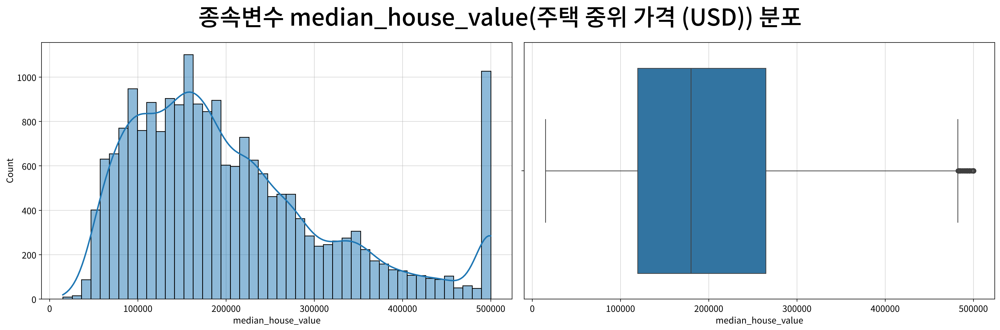

500,001달러 건수 : 958건 (4.7%)


,median_house_value
count,"20,433.000"
mean,"206,864.413"
std,"115,435.667"
min,"14,999.000"
25%,"119,500.000"
50%,"179,700.000"
75%,"264,700.000"
max,"500,001.000"
rel_diff,0.151
rdiff_flag,diff


In [11]:
fig, ax = my_plot.init(rows=1, cols=2, width=960, height=640,
                       title=f"종속변수 {target}({column_means[target]}) 분포")
my_plot.histplot(data=df, x=target, kde=True, ax=ax[0])
my_plot.boxplot(data=df, x=target, ax=ax[1])
my_plot.show()

# 상한값(500,001달러)에 몰린 건수
capped = (df[target] >= 500001).sum()
print(f"500,001달러 건수 : {capped}건 ({capped / len(df):.1%})")

# 기술통계량
display(num_desc.loc[[target]].T)

---
##### 💡 인사이트

| 점검 항목 | `median_house_value` 관찰값 |
|---|---|
| 분포 모양 | 우편향 (왜도 0.98) — 중앙값 179,700달러 < 평균 206,864달러 |
| 이상치 | 위쪽 1,064건(5.2%) / 아래쪽 0건 |
| 상한 절단 | **500,001달러에 958건(4.7%)** 이 몰려 있다 |

- 500,001달러는 실제 가격이 아니라 **조사 상한에서 잘린 값**이다. 위쪽 이상치 1,064건 중 958건(90%)이 이 값이라, IQR 이상치로 보고 지우면 **고가 구간이 통째로 사라진다.**
- → 지우지 않고 **로그 변환**으로 우편향을 완화하며, 모델 평가 때 이 구간의 과소예측 가능성을 감안한다.

---

### (2) 연속형 독립변수 분포

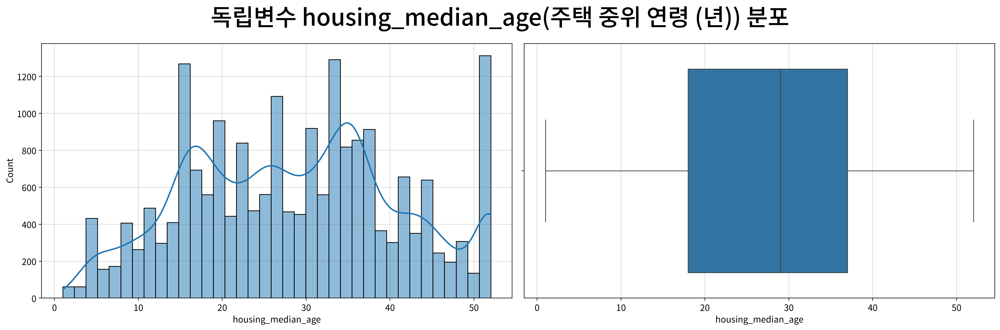

,housing_median_age
count,"20,433.000"
mean,28.633
std,12.592
min,1.000
25%,18.000
50%,29.000
75%,37.000
max,52.000
rel_diff,0.013
rdiff_flag,similar


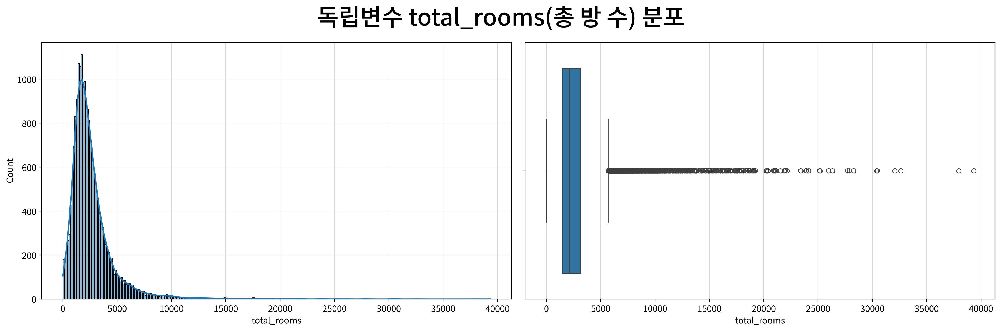

,total_rooms
count,"20,433.000"
mean,"2,636.504"
std,"2,185.270"
min,2.000
25%,"1,450.000"
50%,"2,127.000"
75%,"3,143.000"
max,"39,320.000"
rel_diff,0.240
rdiff_flag,diff


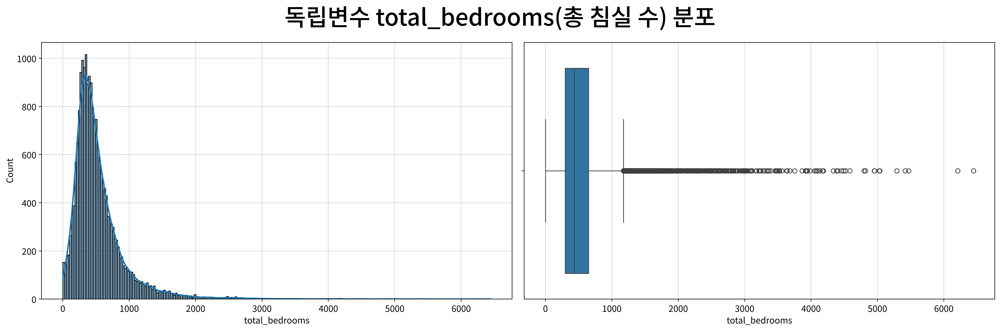

,total_bedrooms
count,"20,433.000"
mean,537.871
std,421.385
min,1.000
25%,296.000
50%,435.000
75%,647.000
max,"6,445.000"
rel_diff,0.236
rdiff_flag,diff


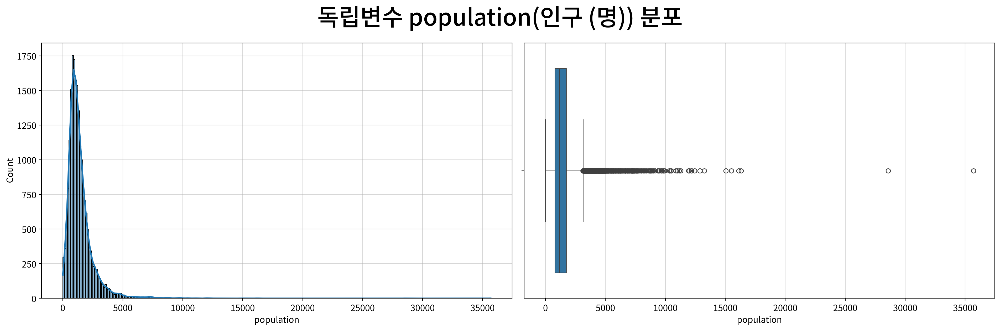

,population
count,"20,433.000"
mean,"1,424.947"
std,"1,133.208"
min,3.000
25%,787.000
50%,"1,166.000"
75%,"1,722.000"
max,"35,682.000"
rel_diff,0.222
rdiff_flag,diff


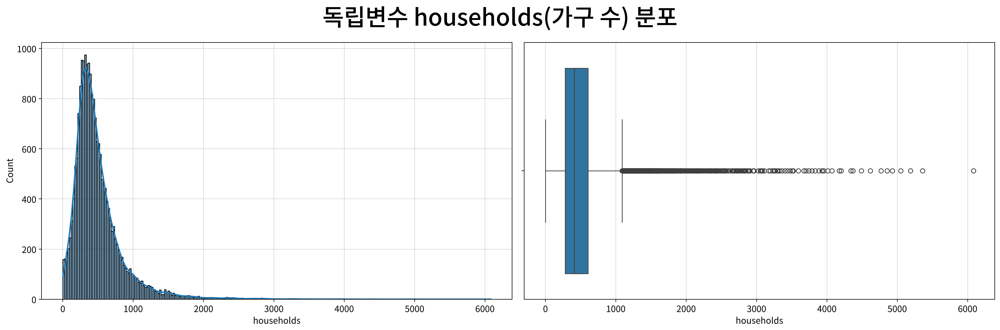

,households
count,"20,433.000"
mean,499.433
std,382.299
min,1.000
25%,280.000
50%,409.000
75%,604.000
max,"6,082.000"
rel_diff,0.221
rdiff_flag,diff


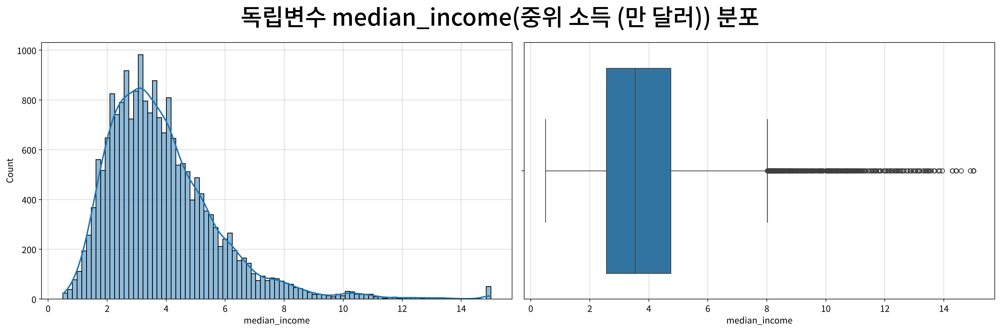

,median_income
count,"20,433.000"
mean,3.871
std,1.899
min,0.500
25%,2.564
50%,3.537
75%,4.744
max,15.000
rel_diff,0.095
rdiff_flag,similar


In [12]:
for f in continuous_cols:
    fig, ax = my_plot.init(rows=1, cols=2, width=960, height=640,
                           title=f"독립변수 {f}({column_means[f]}) 분포")
    my_plot.histplot(data=df, x=f, kde=True, ax=ax[0])
    my_plot.boxplot(data=df, x=f, ax=ax[1])
    my_plot.show()

    display(num_desc.loc[[f]].T)

In [13]:
# 최댓값에 몰린 건수 : 상한 절단 확인
age = (df['housing_median_age'] >= 52).sum()
income= (df['median_income'] >= 15).sum()

print(f"주택 연령 52년        : {age}건 ({age / len(df):.1%})")
print(f"중위 소득 15.0만 달러 : {income}건 ({income / len(df):.1%})")

주택 연령 52년        : 1265건 (6.2%)
중위 소득 15.0만 달러 : 50건 (0.2%)


---
##### 💡 인사이트

| 변수 | 분포 모양 (왜도) | 이상치 | 판단 · 조치 |
|---|---|---|---|
| `housing_median_age` | 거의 대칭 (0.06), 넓게 퍼짐 | 0% | 변환 불필요. **52년에 1,265건(6.2%)** — 상한 절단 |
| `total_rooms` | 강한 우편향 (4.16) | 6.3% | 로그 변환 대상 |
| `total_bedrooms` | 강한 우편향 (3.46) | 6.2% | 로그 변환 대상 |
| `population` | 가장 강한 우편향 (4.96) | 5.8% | 로그 변환 대상 |
| `households` | 강한 우편향 (3.41) | 5.9% | 로그 변환 대상 |
| `median_income` | 중간 우편향 (1.65) | 3.3% | 로그 변환 대상. **15.0에 50건** — 상한 절단 |

- 규모 변수 4종이 모두 **같은 모양**(강한 우편향 + 6% 안팎의 위쪽 이상치)이다. 넷 다 구역에 몇 개가 있는지 세는 **총량**이라, 큰 구역 하나가 네 변수를 동시에 키운다. → 다변량 분석에서 중복을 확인한다.
- 규모 변수의 이상치는 **입력 오류로 보기 어렵다.** 한 행이 집 한 채가 아니라 구역 전체의 합계라서, 인구가 많은 큰 구역은 값이 클 수밖에 없다(예 : 인구 최대 35,682명). 물리적으로 불가능한 값도 아니므로 **지우지 않고 로그 변환**으로 큰 값의 영향을 줄인다.

---

### (3) 명목형 독립변수 분포

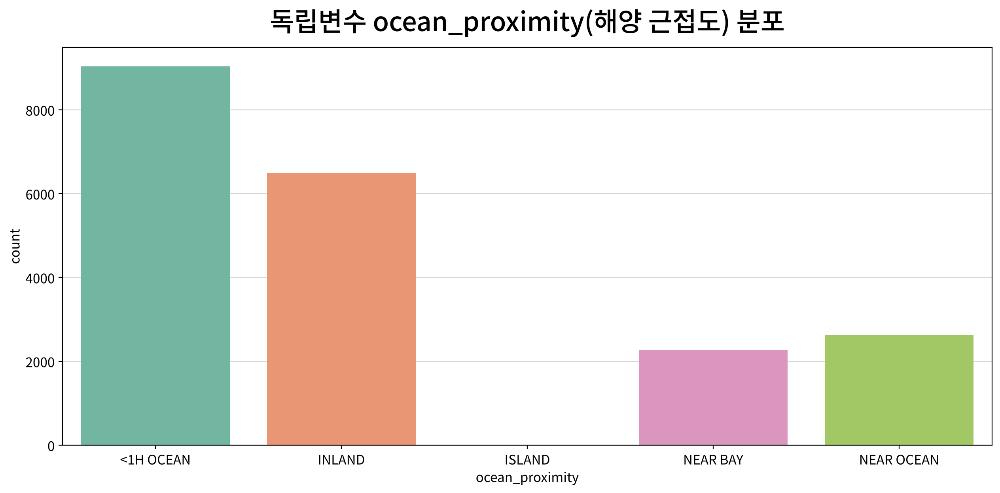

ocean_proximity,<1H OCEAN,INLAND,NEAR OCEAN,NEAR BAY,ISLAND
빈도,"9,034.000","6,496.000","2,628.000","2,270.000",5.000
비율,0.442,0.318,0.129,0.111,0.000


In [14]:
for n in nominal_cols:
    my_plot.countplot(data=df, x=n, hue=n, palette="Set2",
                      title=f"독립변수 {n}({column_means[n]}) 분포")

    freq = df[n].value_counts().rename("빈도").to_frame()
    freq["비율"] = df[n].value_counts(normalize=True)
    display(freq.T)

---
##### 💡 인사이트

| 변수 | 범주 분포 | 판단 |
|---|---|---|
| `ocean_proximity` | `<1H OCEAN` 9,034 (44.2%) · `INLAND` 6,496 (31.8%) · `NEAR OCEAN` 2,628 (12.9%) · `NEAR BAY` 2,270 (11.1%) · **`ISLAND` 5 (0.02%)** | **`ISLAND`가 문제** |

- `ISLAND`는 5건(0.02%)뿐이다. 이 정도로 적으면 범주의 평균을 안정적으로 추정하기 어렵다.
- 나머지 4개 범주는 각각 2,000건 이상이라 검정에 충분하다.

---

## 2-2. 이변량 분석 — 각 독립변수가 집값을 설명하는가?

### (1) 연속형 × 연속형 : 상관분석

- 채택 기준 : **유의(p < 0.05) + 상관강도 Moderate 이상(|ρ| ≥ 0.3)**

#### ▶︎ housing_median_age(주택 중위 연령 (년)) → median_house_value

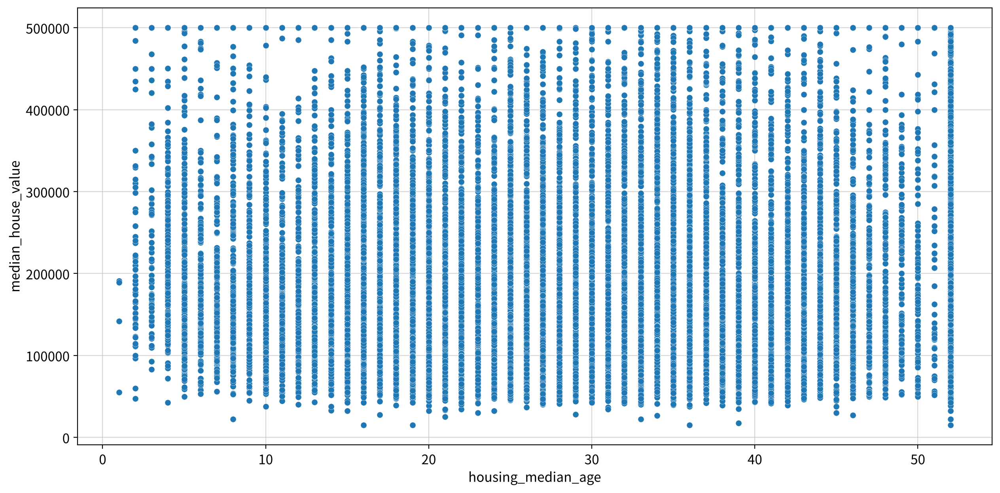

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
housing_median_age,median_house_value,Spearman,0.075,0.000,Weak,True,False,False,False,False,False


#### ▶︎ total_rooms(총 방 수) → median_house_value

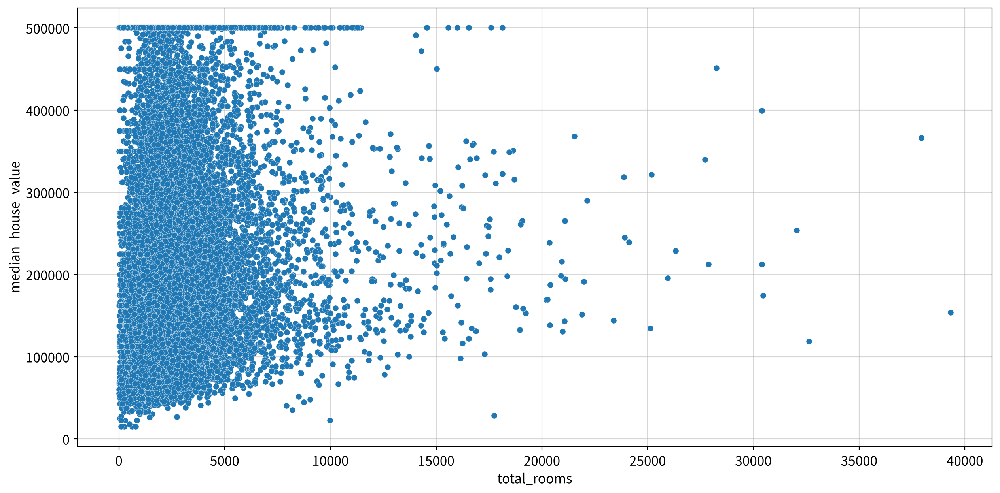

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
total_rooms,median_house_value,Spearman,0.205,0.000,Weak,True,False,False,False,False,True


#### ▶︎ total_bedrooms(총 침실 수) → median_house_value

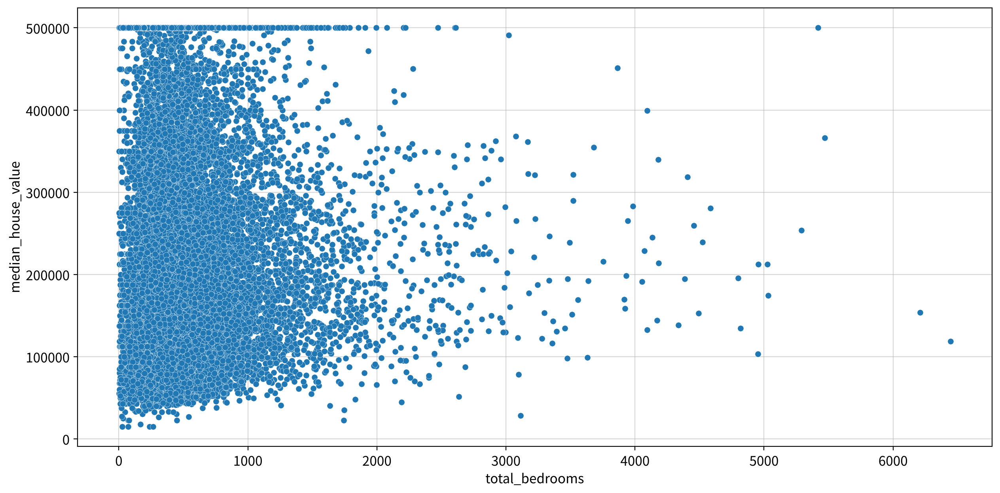

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
total_bedrooms,median_house_value,Spearman,0.086,0.000,Weak,True,False,False,False,False,True


#### ▶︎ population(인구 (명)) → median_house_value

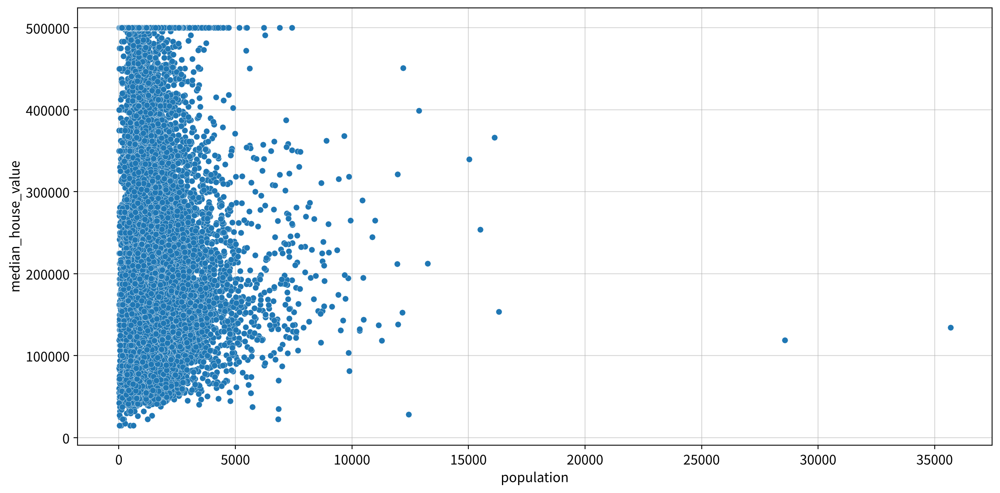

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
population,median_house_value,Spearman,0.003,0.681,Weak,False,False,False,True,False,True


#### ▶︎ households(가구 수) → median_house_value

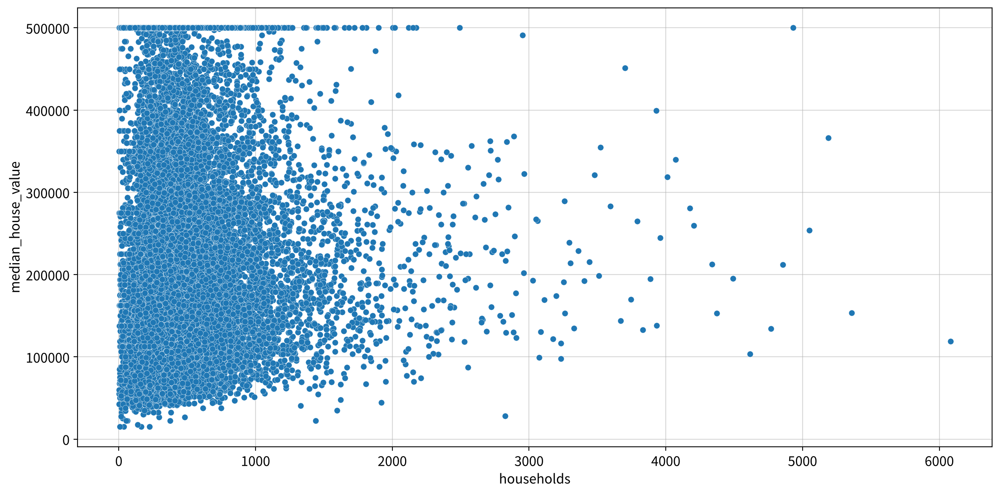

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
households,median_house_value,Spearman,0.112,0.000,Weak,True,False,False,False,False,True


#### ▶︎ median_income(중위 소득 (만 달러)) → median_house_value

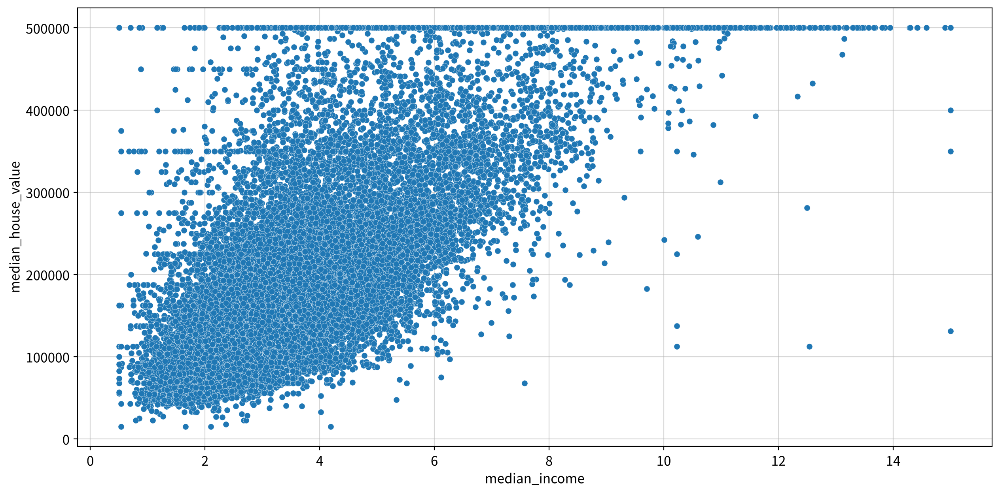

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
median_income,median_house_value,Spearman,0.677,0.000,Moderate,True,False,False,False,False,True


In [15]:
for f in continuous_cols:
    print()
    display(Markdown(f"#### ▶︎ {f}({column_means[f]}) → {target}"))

    # 시각화 - 산점도 크기 조정
    my_plot.scatterplot(data=df, x=f, y=target, outline=False, linewidth=0.2, size=30)
    
    # 상관분석
    display(my_stats.correlation(df, x=f, y=target, plot=False))

---
##### 💡 인사이트

| 판정 | 변수 | coef (Spearman) | 강도 | p-value |
|---|---|---|---|---|
| ✅ 채택 | `median_income` | **+0.677** | **Moderate** | < 0.001 |
| 🟡 보류 | `total_rooms` | +0.205 | Weak | < 0.001 |
| 🟡 보류 | `households` | +0.112 | Weak | < 0.001 |
| 🟡 보류 | `total_bedrooms` | +0.086 | Weak | < 0.001 |
| 🟡 보류 | `housing_median_age` | +0.075 | Weak | < 0.001 |
| ❌ 제외 | `population` | +0.003 | Weak | **0.681** |

- **채택 기준(|ρ| ≥ 0.3)을 넘은 변수는 `median_income` 하나뿐**이다. 2위 `total_rooms`(0.205)의 3배가 넘는다.
- **`population`은 유일하게 유의하지 않다**(p = 0.681). 2만 건이 넘는 큰 표본에서도 관계가 없다는 뜻이다.
- 모든 산점도의 **맨 위(집값 500,001달러)에 점들이 가로로 한 줄 늘어서 있다.** 50만 달러가 넘는 집이 전부 500,001달러로 기록되어 생긴 줄이다. 그래서 비싼 동네일수록 실제 집값보다 낮게 기록되어, 모든 변수와 집값의 관계가 **위쪽에서 눌려** 보인다.
- **규모 변수가 약한 이유** : 방 수 · 인구는 구역 전체의 합계라, **집이 많은 구역일수록 커진다.** 집이 넓은지, 동네가 비싼지와는 상관없이 커지기 때문에 집값을 잘 설명하지 못한다.

---

### (2) 명목형(3집단 이상) × 연속형 : 일원분산분석 + 사후검정

In [16]:
for n in nominal_cols:
    print()
    display(Markdown(f"#### ▶︎ {n}({column_means[n]}) → {target}"))

    display(my_stats.anova_oneway(df, y=target, between=n))
    display(my_stats.posthoc_oneway(df, y=target, between=n, plot=False))

#### ▶︎ ocean_proximity(해양 근접도) → median_house_value

,test,Source,ddof1,ddof2,F,p_unc,np2,effect_size
0,welch_anova,ocean_proximity,4,31.918,"2,055.803",0.000,0.238,Large


비교한 조합 쌍: 10개
유의한 쌍: 7개
평균 차이가 가장 큰 쌍: (INLAND) vs (ISLAND)→ 차이 255543.137, 효과크기 Large, p=value 0.010
평균 차이가 가장 작은 쌍: (<1H OCEAN) vs (NEAR OCEAN)→ 차이 8774.364, 효과크기 Negligible, p-value 0.008


,test,A,B,mean_A,mean_B,diff,se,T,df,pval,hedges,significant,effect_size
0,Games-Howell,<1H OCEAN,INLAND,"240,267.991","124,896.863","115,371.128","1,415.614",81.499,"15,420.197",0.000,1.243,True,Large
1,Games-Howell,<1H OCEAN,ISLAND,"240,267.991","380,440.000","-140,172.009","36,044.653",-3.889,4.008,0.076,-1.320,False,Large
2,Games-Howell,<1H OCEAN,NEAR BAY,"240,267.991","259,279.292","-19,011.301","2,810.217",-6.765,"3,172.951",0.000,-0.173,True,Negligible
3,Games-Howell,<1H OCEAN,NEAR OCEAN,"240,267.991","249,042.355","-8,774.364","2,638.754",-3.325,"3,846.759",0.008,-0.080,True,Negligible
4,Games-Howell,INLAND,ISLAND,"124,896.863","380,440.000","-255,543.137","36,037.816",-7.091,4.005,0.010,-3.647,True,Large
5,Games-Howell,INLAND,NEAR BAY,"124,896.863","259,279.292","-134,382.429","2,721.117",-49.385,"2,801.345",0.000,-1.547,True,Large
6,Games-Howell,INLAND,NEAR OCEAN,"124,896.863","249,042.355","-124,145.492","2,543.654",-48.806,"3,343.938",0.000,-1.404,True,Large
7,Games-Howell,ISLAND,NEAR BAY,"380,440.000","259,279.292","121,160.708","36,119.489",3.354,4.041,0.118,0.986,False,Large
8,Games-Howell,ISLAND,NEAR OCEAN,"380,440.000","249,042.355","131,397.645","36,106.554",3.639,4.035,0.093,1.072,False,Large
9,Games-Howell,NEAR BAY,NEAR OCEAN,"259,279.292","249,042.355","10,236.937","3,516.182",2.911,"4,789.540",0.030,0.083,True,Negligible


---
##### 💡 인사이트

| 변수 | 집단 차이 | 효과크기 | 사후검정 | 판정 |
|---|---|---|---|---|
| `ocean_proximity` | 유의 (Welch F = 2,055.8, p < 0.001) | np² = **0.238 (Large)** | 10쌍 중 7쌍 유의 | ✅ 채택 |

- 집단 평균은 `INLAND` 124,897달러 < `<1H OCEAN` 240,268달러 < `NEAR OCEAN` 249,042달러 < `NEAR BAY` 259,279달러 < `ISLAND` 380,440달러다.
- **실질 구조는 5집단이 아니라 '내륙 vs 해안권' 2집단**이다.
  - `INLAND`와 나머지의 차이는 모두 효과크기 Large다.
  - 해안권 3종(`<1H OCEAN` · `NEAR OCEAN` · `NEAR BAY`)끼리는 유의해도 효과크기가 모두 **Negligible**이다. 표본이 커서 유의하게 나왔을 뿐 실질 차이는 작다.
- **`ISLAND`(5건)는 판정할 수 없다.** 평균은 가장 높지만, 다른 범주와의 차이가 12~14만 달러인데도 대부분 유의하지 않다. 차이가 없어서가 아니라 표본이 너무 작아서다.

---

## 2-3. 다변량 분석 — 독립변수끼리 같은 정보를 담고 있는가?

In [17]:
corr = my_stats.multi_correlation(df, columns=continuous_cols, plot=False)
my_stats.correlation_summary(corr)

,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
housing_median_age,1.000,-0.356,-0.306,-0.283,-0.281,-0.146
total_rooms,-0.356,1.000,0.915,0.816,0.906,0.271
total_bedrooms,-0.306,0.915,1.000,0.871,0.976,-0.006
population,-0.283,0.816,0.871,1.000,0.904,0.005
households,-0.281,0.906,0.976,0.904,1.000,0.029
median_income,-0.146,0.271,-0.006,0.005,0.029,1.000


,max-y,max-coef,count,columns
x,,,,
households,total_bedrooms,0.976,3,"total_bedrooms, total_rooms, population"
total_bedrooms,households,0.976,3,"households, total_rooms, population"
total_rooms,total_bedrooms,0.915,3,"total_bedrooms, households, population"
population,households,0.904,3,"households, total_bedrooms, total_rooms"
housing_median_age,total_rooms,-0.356,0,-
median_income,total_rooms,0.271,0,-


---
##### 💡 인사이트

- **규모 변수 4종이 하나의 덩어리**다(서로 ρ ≥ 0.90).
  - `households` ↔ `total_bedrooms` 0.976 (최대)
  - `total_rooms` ↔ `total_bedrooms` 0.915
  - `population` ↔ `households` 0.904
- `median_income`(최대 0.271)과 `housing_median_age`(최대 −0.356)는 다른 변수와 겹치지 않는다.
- → 규모 4종은 그대로 넣으면 같은 정보를 네 번 넣는 셈이다. **서로 나눈 비율**로 바꾸면 중복과 '크기' 효과를 함께 줄일 수 있다.

---

## 2-4. 최종 변수 선택

| 판정 | 변수 | 검정 | 효과 | 비대칭 | 공선성 | 근거 |
|---|---|---|---|---|---|---|
| ✅ 채택 | `ocean_proximity` | Welch ANOVA | np² = 0.238 (Large) | — | 없음 | 단독 설명력 최상위. 내륙과 해안권의 격차가 11만 달러 이상 |
| ✅ 채택 | `median_income` | Spearman | ρ = +0.677 (Moderate) | 우편향 (1.65) | 없음 (최대 0.271) | 연속형 중 유일한 실질 설명변수 |
| 🟡 보류 | `total_rooms` | Spearman | ρ = +0.205 (Weak) | 강한 우편향 (4.16) | 규모 덩어리 | 규모 4종 중 설명력 최상 → 비율형 파생의 재료 |
| 🟡 보류 | `housing_median_age` | Spearman | ρ = +0.075 (Weak) | 대칭 | 없음 | 설명력은 약하지만 중복이 없어 정보 가치가 있음 |
| 🟡 보류 | `households` | Spearman | ρ = +0.112 (Weak) | 강한 우편향 (3.41) | 규모 덩어리 (`total_bedrooms` 0.976) | 비율형 파생의 재료 (분모) |
| 🟡 보류 | `total_bedrooms` | Spearman | ρ = +0.086 (Weak) | 강한 우편향 (3.46) | 규모 덩어리 (`households` 0.976) | 비율형 파생의 재료 (침실 비율) |
| ❌ 제외 | `population` | Spearman | ρ = +0.003 (p = 0.681) | 강한 우편향 (4.96) | 규모 덩어리 | 유일한 비유의 변수 — 단독으로는 제외, 비율형 파생의 분모로만 사용 |
| 🔶 별도 | `longitude` · `latitude` | — | — | — | — | 좌표 변수 → PART 3 공간특성으로 재투입 |

- **위치(`ocean_proximity`)와 소득(`median_income`)이 단독으로 가장 강한 두 변수다.** 위치와 소득이 집값을 가른다는 도메인 상식과도 맞는다.
- **PART 3에서 할 일**
  1. 규모 4종 → **비율형 파생변수**로 재구성
  2. 상한 절단(주택 연령 52년 · 소득 15.0) → **절단 플래그**로 표시
       - 종속변수(집값 500,001달러)의 절단은 플래그로 만들지 않는다. 맞혀야 할 답을 알려 주는 변수가 되기 때문이다(데이터 누수). 대신 **로그 변환**으로 영향을 줄인다.
  3. `ocean_proximity` → **내륙 / 해안권** 2범주로 병합 (`ISLAND`는 해안권에 흡수)
  4. 위도 · 경도 → **공간특성 변수**로 변환
  5. 우편향 변수와 종속변수 → **로그 변환**

---
# PART 3. 분석용 데이터 전처리

- EDA에서 정한 다섯 가지 과제를 파생변수로 해결하고, 만든 변수가 실제로 집값을 설명하는지 **EDA와 같은 절차로 검증**한다.

## 3-1. 비율형 파생변수

### (1) 규모 해제 — 총량끼리 나눠 '성격'만 남기기

| 파생변수 | 계산식 | 의미 |
|---|---|---|
| `rooms_per_person` | `total_rooms / population` | 1인당 방 수 → 주거 여유 공간 |
| `rooms_per_household` | `total_rooms / households` | 가구당 방 수 → 주택 규모 |
| `bedrooms_per_room` | `total_bedrooms / total_rooms` | 방 중 침실 비율 → 낮을수록 거실 · 기타 공간이 넓은 집 |
| `population_per_household` | `population / households` | 가구당 인구 → 과밀도 |

- 구역 전체의 합계끼리 나누면 **"구역이 크다"는 공통 성분이 약분**되고, 구역의 성격만 남는다.

In [18]:
df["rooms_per_person"]         = df["total_rooms"] / df["population"]
df["rooms_per_household"]      = df["total_rooms"] / df["households"]
df["bedrooms_per_room"]        = df["total_bedrooms"] / df["total_rooms"]
df["population_per_household"] = df["population"] / df["households"]

# 컬럼 의미 딕셔너리 갱신
column_means.update({
    "rooms_per_person":         "1인당 방 수",
    "rooms_per_household":      "가구당 방 수",
    "bedrooms_per_room":        "방 중 침실 비율",
    "population_per_household": "가구당 인구",
})

df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_person,rooms_per_household,bedrooms_per_room,population_per_household
0,-122.230,37.880,41.000,880.000,129.000,322.000,126.000,8.325,"452,600.000",NEAR BAY,2.733,6.984,0.147,2.556
1,-122.220,37.860,21.000,"7,099.000","1,106.000","2,401.000","1,138.000",8.301,"358,500.000",NEAR BAY,2.957,6.238,0.156,2.110
2,-122.240,37.850,52.000,"1,467.000",190.000,496.000,177.000,7.257,"352,100.000",NEAR BAY,2.958,8.288,0.130,2.802
3,-122.250,37.850,52.000,"1,274.000",235.000,558.000,219.000,5.643,"341,300.000",NEAR BAY,2.283,5.817,0.184,2.548
4,-122.250,37.850,52.000,"1,627.000",280.000,565.000,259.000,3.846,"342,200.000",NEAR BAY,2.880,6.282,0.172,2.181


In [19]:
# 생성한 파생변수 점검
ratio_cols = ["rooms_per_person", "rooms_per_household", "bedrooms_per_room",
              "population_per_household"]

# 나눗셈 점검 : 분모에 0이 있으면 무한대가 생긴다
print("분모 최솟값 :", df[["population", "households", "total_rooms"]].min().to_dict())
print("결측치      :", df[ratio_cols].isna().sum().to_dict())
print("무한대      :", df[ratio_cols].isin([float("inf"), float("-inf")]).sum().to_dict())

분모 최솟값 : {'population': 3.0, 'households': 1.0, 'total_rooms': 2.0}
결측치      : {'rooms_per_person': 0, 'rooms_per_household': 0, 'bedrooms_per_room': 0, 'population_per_household': 0}
무한대      : {'rooms_per_person': 0, 'rooms_per_household': 0, 'bedrooms_per_room': 0, 'population_per_household': 0}


### (2) 1인당 구매력 — 가구 소득을 1인 기준으로

| 파생변수 | 계산식 | 의미 |
|---|---|---|
| `income_per_person` | `median_income / population_per_household` | 1인당 소득 |

- `median_income`은 합계가 아니라 **가구당** 중위 소득이다. 같은 소득이라도 가구원이 많으면 한 사람의 몫은 줄어들기 때문에, 가구당 인구로 나눠 **1인당 구매력**으로 바꾼다.

In [20]:
df["income_per_person"] = df["median_income"] / df["population_per_household"]

# 컬럼 의미 딕셔너리 갱신
column_means.update({
    "income_per_person":        "1인당 소득 (만 달러)",
})

df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_person,rooms_per_household,bedrooms_per_room,population_per_household,income_per_person
0,-122.230,37.880,41.000,880.000,129.000,322.000,126.000,8.325,"452,600.000",NEAR BAY,2.733,6.984,0.147,2.556,3.258
1,-122.220,37.860,21.000,"7,099.000","1,106.000","2,401.000","1,138.000",8.301,"358,500.000",NEAR BAY,2.957,6.238,0.156,2.110,3.935
2,-122.240,37.850,52.000,"1,467.000",190.000,496.000,177.000,7.257,"352,100.000",NEAR BAY,2.958,8.288,0.130,2.802,2.590
3,-122.250,37.850,52.000,"1,274.000",235.000,558.000,219.000,5.643,"341,300.000",NEAR BAY,2.283,5.817,0.184,2.548,2.215
4,-122.250,37.850,52.000,"1,627.000",280.000,565.000,259.000,3.846,"342,200.000",NEAR BAY,2.880,6.282,0.172,2.181,1.763


In [21]:
# 생성한 파생변수 점검
col = "income_per_person"
denominator = "population_per_household"     # 나눌 때 쓴 분모

# 나눗셈 점검 : 분모에 0이 있으면 무한대가 생긴다
print("분모 최솟값 :", df[denominator].min().round(4))
print("결측치      :", df[col].isna().sum())
print("무한대      :", df[col].isin([float("inf"), float("-inf")]).sum())

분모 최솟값 : 0.6923
결측치      : 0
무한대      : 0


## 3-2. 범주형 파생변수

### (1) 상한 절단 플래그

- EDA에서 본 최댓값의 막대(52년, 15.0만 달러)는 실제 값이 아니라 조사 상한에서 **잘린 값**이다. 값을 고치거나 지우지 않고, **"여기서 잘렸다"는 표시만** 남긴다.

In [22]:
# housing_median_age(주택 중위 연령)이 52 이상이면 1, 아니면 0
df["is_age_capped"]    = (df["housing_median_age"] >= 52).astype(int)

# median_income(중위 소득)이 15 이상이면 1, 아니면 0
df["is_income_capped"] = (df["median_income"] >= 15.0).astype(int)

# 컬럼 의미 딕셔너리 갱신
column_means.update({
    "is_age_capped": "주택 연령 상한 절단 여부",
    "is_income_capped": "소득 상한 절단 여부",
})

flags = ["is_age_capped", "is_income_capped"]
summary = df[flags].sum().to_frame("건수")
summary["비율"] = (summary["건수"] / len(df)).round(4)
summary

,건수,비율
is_age_capped,1265,0.062
is_income_capped,50,0.002


### (2) 범주 재구성 — 해안권 / 내륙

- 사후검정에서 해안권 3종(`<1H OCEAN` · `NEAR OCEAN` · `NEAR BAY`)끼리는 효과크기가 미미했고, `ISLAND`(5건)는 판정할 수 없었다.
- 그래서 **`INLAND`(내륙)와 나머지 전부(`COASTAL`, 해안권)** 의 2범주로 묶는다.

In [23]:
# INLAND 를 제외한 나머지 범주를 COASTAL(해안권)로 병합
df["ocean_area"] = df["ocean_proximity"].apply(
    lambda x: "INLAND" if x == "INLAND" else "COASTAL").astype("category")

# 컬럼 의미 딕셔너리 갱신
column_means.update({
    "ocean_area": "내륙 / 해안권 구분",
})

display(df["ocean_proximity"].value_counts().rename("병합 전").to_frame().T)
display(df["ocean_area"].value_counts().rename("병합 후").to_frame().T)

ocean_proximity,<1H OCEAN,INLAND,NEAR OCEAN,NEAR BAY,ISLAND
병합 전,9034,6496,2628,2270,5


ocean_area,COASTAL,INLAND
병합 후,13937,6496


## 3-3. 공간특성 반영

- **공간자기상관** : 가까이 있는 지역끼리 값이 비슷한(또는 다른) 정도다. 집값이라면 "비싼 동네 옆에 또 비싼 동네가 있는가"를 본다.
- 먼저 **Moran's I**로 공간 구조가 있는지 확인하고, 있다면 위경도를 **군집화해 권역 변수**로 만든다.

### (1) 포인트 좌표(지오메트리) 만들기

- 위도 · 경도 두 숫자를 **점(Point) 하나**로 묶는다.

In [24]:
geometry = points_from_xy(x=df["longitude"], y=df["latitude"])
geometry 

<GeometryArray>
[<POINT (-122.23 37.88)>, <POINT (-122.22 37.86)>, <POINT (-122.24 37.85)>,
 <POINT (-122.25 37.85)>, <POINT (-122.25 37.85)>, <POINT (-122.25 37.85)>,
 <POINT (-122.25 37.84)>, <POINT (-122.25 37.84)>, <POINT (-122.26 37.84)>,
 <POINT (-122.25 37.84)>,
 ...
 <POINT (-121.32 39.29)>,  <POINT (-121.4 39.33)>, <POINT (-121.45 39.26)>,
 <POINT (-121.53 39.19)>, <POINT (-121.56 39.27)>, <POINT (-121.09 39.48)>,
 <POINT (-121.21 39.49)>, <POINT (-121.22 39.43)>, <POINT (-121.32 39.43)>,
 <POINT (-121.24 39.37)>]
Length: 20433, dtype: geometry

### (2) 공간 데이터(GeoDataFrame) 만들기

- 데이터에 점 좌표를 붙여 **지도에 올릴 수 있는 표**로 만든다.
- 이웃을 정하려면 실제 거리가 필요하므로, 좌표계를 **미터 단위**로 바꾼다(`to_crs`).

| 좌표계 | 단위 | 쓰임 |
|---|---|---|
| `EPSG:4326` | 도(°) | 위도 · 경도 그대로의 좌표. 데이터를 처음 만들 때 지정 |
| `EPSG:5186` | 미터(m) | 거리를 잴 수 있는 좌표. 이웃 관계를 정할 때 사용 |

In [25]:
# 원본 데이터에서 위경도 제거
df_temp = df.drop(columns=["longitude", "latitude"])

# 데이터 + 좌표 → 공간 데이터
gdf = GeoDataFrame(df_temp, geometry=geometry, crs="EPSG:4326")

# 거리를 잴 수 있는 좌표계(미터 단위)로 변환
gdf = gdf.to_crs(epsg=5186)

gdf.head()

,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_person,rooms_per_household,bedrooms_per_room,population_per_household,income_per_person,is_age_capped,is_income_capped,ocean_area,geometry
0,41.000,880.000,129.000,322.000,126.000,8.325,"452,600.000",NEAR BAY,2.733,6.984,0.147,2.556,3.258,0,0,COASTAL,POINT (6238852.92 9120350.944)
1,21.000,"7,099.000","1,106.000","2,401.000","1,138.000",8.301,"358,500.000",NEAR BAY,2.957,6.238,0.156,2.110,3.935,0,0,COASTAL,POINT (6240970.078 9123181.971)
2,52.000,"1,467.000",190.000,496.000,177.000,7.257,"352,100.000",NEAR BAY,2.958,8.288,0.130,2.802,2.590,1,0,COASTAL,POINT (6243735.516 9121822.738)
3,52.000,"1,274.000",235.000,558.000,219.000,5.643,"341,300.000",NEAR BAY,2.283,5.817,0.184,2.548,2.215,1,0,COASTAL,POINT (6244418.029 9120712.121)
4,52.000,"1,627.000",280.000,565.000,259.000,3.846,"342,200.000",NEAR BAY,2.880,6.282,0.172,2.181,1.763,1,0,COASTAL,POINT (6244418.029 9120712.121)


### (3) 공간가중치 행렬 만들기

- **공간가중치 행렬** : "누가 이웃인가"를 정리한 표다.

| 구분 | 방식 | 이웃의 기준 |
|---|---|---|
| 인접 기반 | `Queen` | 경계선이나 **꼭짓점**이라도 맞닿으면 이웃 (체스의 퀸처럼 8방향) |
| 인접 기반 | `Rook` | **경계선**이 맞닿아야 이웃 (체스의 룩처럼 4방향) |
| 거리 기반 | `KNN` | 거리가 **가장 가까운 k개**를 이웃 (점 데이터에 주로 사용) |

- **가중치 변환 방식(`transform`)** : 이웃의 값을 어떻게 반영할지 정한다.

| 값 | 방식 | 내용 | 쓰임 |
|---|---|---|---|
| **`R`** | **행 표준화** | 이웃 값의 **평균**으로 계산 (이웃 수가 달라도 공평) | 일반적인 Moran's I — **권장** |
| `B` | 이진 | 이웃이면 1, 아니면 0 (이웃이 많을수록 영향이 커짐) | 인접 여부만 단순하게 반영할 때 |
| `V` | 분산 안정화 | 이웃 수 차이에 따른 분산 문제를 줄임 | 특수한 분산 보정이 필요할 때 |

- 이 분석에서는 인접 기반인 `Queen` · `Rook` 두 가지로 Moran's I를 구해, 이웃의 정의를 바꿔도 결과가 같은지 확인한다.
- **행 표준화(`R`)** : 이웃이 많은 구역과 적은 구역이 공평하게 비교되도록, 이웃 값의 **평균**으로 계산한다.

In [26]:
# Queen 방식
qw = Queen.from_dataframe(gdf, use_index=False)
qw.transform = "R"      # 행 표준화

# Rook 방식
rw = Rook.from_dataframe(gdf, use_index=False)
rw.transform = "R"      # 행 표준화

print(f"Queen : 구역당 평균 이웃 {qw.mean_neighbors:.1f}개")
print(f"Rook  : 구역당 평균 이웃 {rw.mean_neighbors:.1f}개")

Queen : 구역당 평균 이웃 13.7개
Rook  : 구역당 평균 이웃 13.7개


### (4) 종속변수에 대한 Moran's I

- **Moran's I** : 공간가중치 행렬을 기준으로, 공간자기상관을 확인하는 통계 지표다.

| Moran's I | 의미 | 예 |
|---|---|---|
| **0보다 큼** | 양의 공간자기상관 (Hot Spot 군집형) — 비슷한 값끼리 모여 있음 | 번화가 주변 상권 |
| **0보다 작음** | 음의 공간자기상관 (체스판 분산형) — 높은 값과 낮은 값이 번갈아 있음 | 특정 골목 상권 |
| **0에 가까움** | 공간 무작위 (공간적 독립성) — 우연히 흩어져 있음 | 로또 1등 당첨 판매점 |

- **판정 기준**

| Moran's I | p-value | 해석 |
|---|---|---|
| I > 0 | p < 0.05 | 양의 공간자기상관이 유의함 |
| I < 0 | p < 0.05 | 음의 공간자기상관이 유의함 |
| I > 0 또는 I < 0 | p ≥ 0.05 | 공간자기상관이 있다고 보기 어려움 |
| I ≈ 0 | p ≥ 0.05 | 무작위 분포에 가까움 |

In [27]:
result = []                     # Moran's I 결과를 저장할 리스트
y = gdf["median_house_value"]   # 분석 대상 변수(종속변수)

# Queen 인접성 기반 Moran's I 계산
moran_q = Moran(y, qw)
result.append({"Moran's I": moran_q.I, "p-value": moran_q.p_sim})

# Rook 인접성 기반 Moran's I 계산
moran_r = Moran(y, rw)
result.append({"Moran's I": moran_r.I, "p-value": moran_r.p_sim})

moran_df = DataFrame(result, index=["Queen", "Rook"])
moran_df

,Moran's I,p-value
Queen,0.790,0.001
Rook,0.790,0.001


---
##### 💡 인사이트 — 이웃한 구역끼리 집값이 닮았다

| 공간가중치 | Moran's I | p-value | 판정 |
|---|---|---|---|
| Queen | **0.790** | 0.001 | I > 0, p < 0.05 → 양의 공간자기상관 유의 |
| Rook | **0.790** | 0.001 | I > 0, p < 0.05 → 양의 공간자기상관 유의 |

- 두 가중치 모두 **I = 0.790 > 0, p = 0.001 < 0.05**로, **양의 공간자기상관이 유의**하다. 비싼 구역 주변에 비싼 구역이, 싼 구역 주변에 싼 구역이 모여 있는 **Hot Spot 군집형**이다.
- 이웃을 정하는 방식(Queen · Rook)을 바꿔도 값이 같아, 공간 구조가 **안정적으로 존재**한다.
- → 이웃끼리 집값이 닮은 이유 중에는 소득 · 방 수 같은 다른 변수로는 설명되지 않는 **'위치 자체의 차이'** 가 있다. 위치 정보를 빼고 모델을 만들면 이 차이를 설명하지 못하게 된다. 따라서 위도 · 경도를 **군집화해 가까운 구역끼리 묶은 '권역' 변수**로 만들어 모델에 넣는다.

---

### (5) 좌표 군집화 — 군집 수(k) 결정

- 위도 · 경도 두 값으로 K-means 군집을 만들어, 좌표를 **'권역'이라는 범주형 변수**로 바꾼다.
- `best_k()`는 두 지표를 차례로 계산한다.
  - **엘보우** : 군집 안이 얼마나 뭉쳤는지만 본다 → **후보** 제시
  - **실루엣 균형지수** : 뭉침 + 군집 간 분리 + 군집 크기 균형까지 본다 → **최종 선택**

StandardScaler 적용 (2개 컬럼)
컬럼                       변환 전               변환 후
--------------------------------------------------------
latitude           32.54 ~ 41.95          -1.45 ~ 2.96
longitude      -124.35 ~ -114.31          -2.39 ~ 2.63


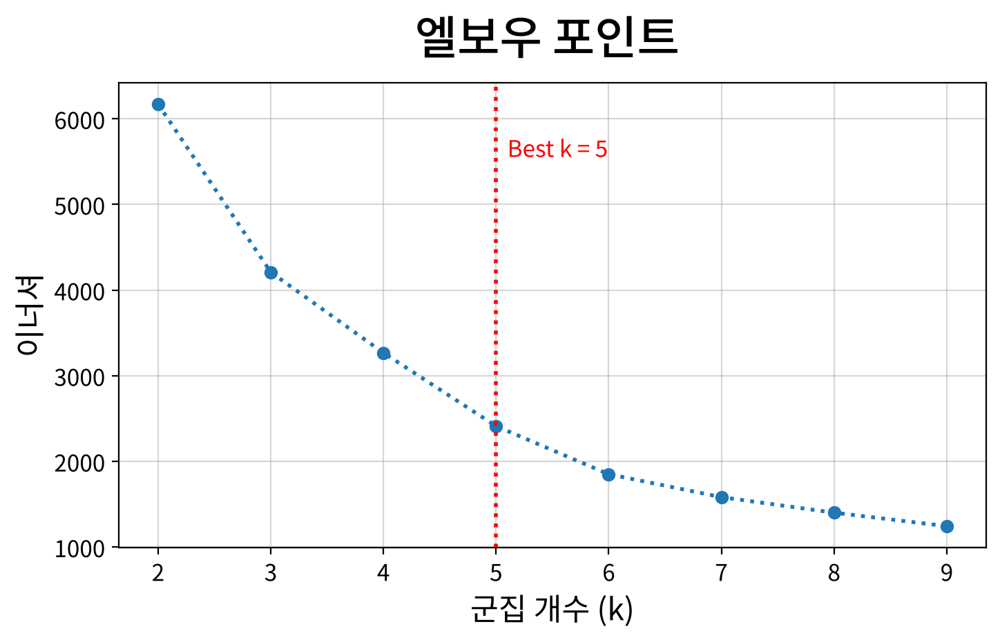

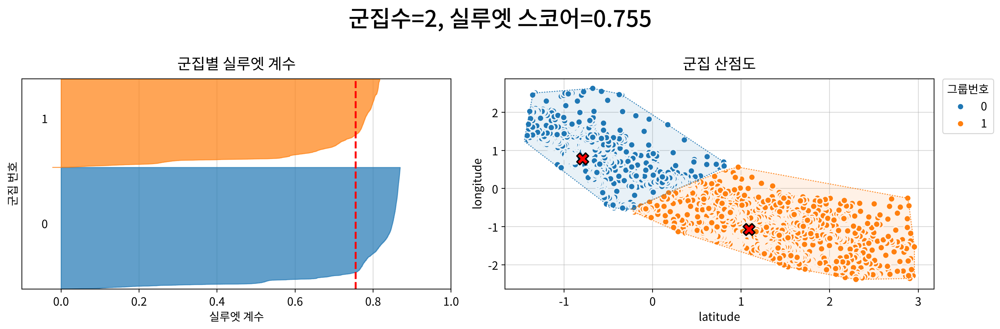

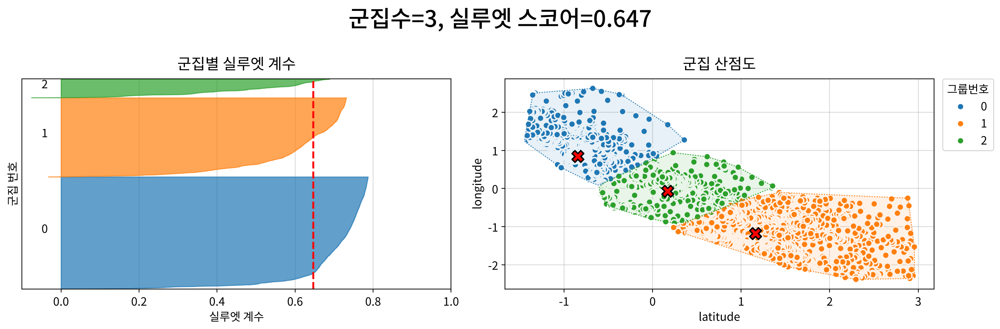

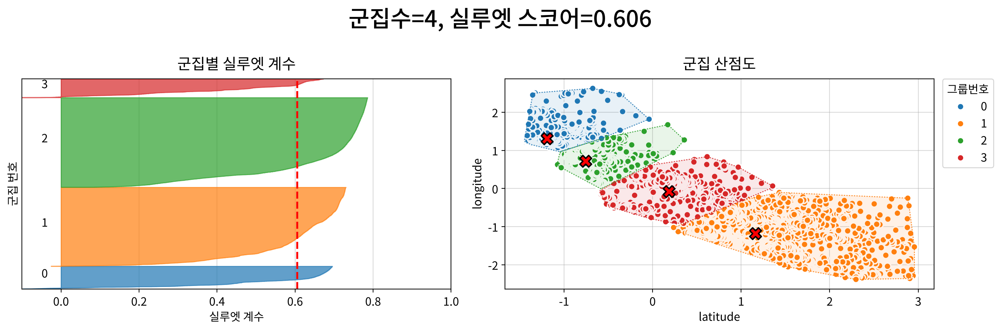

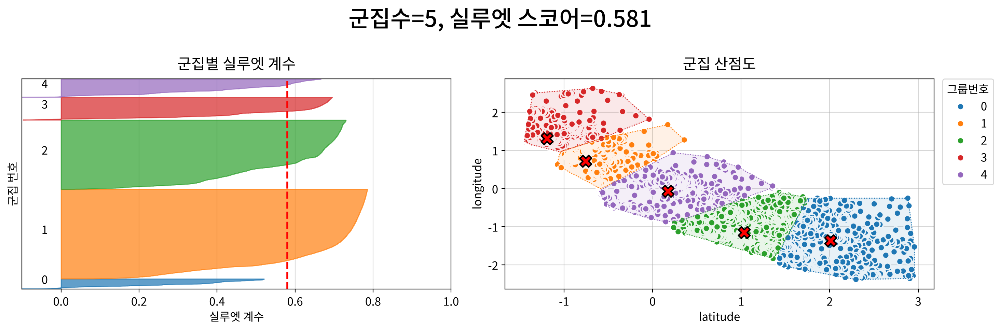

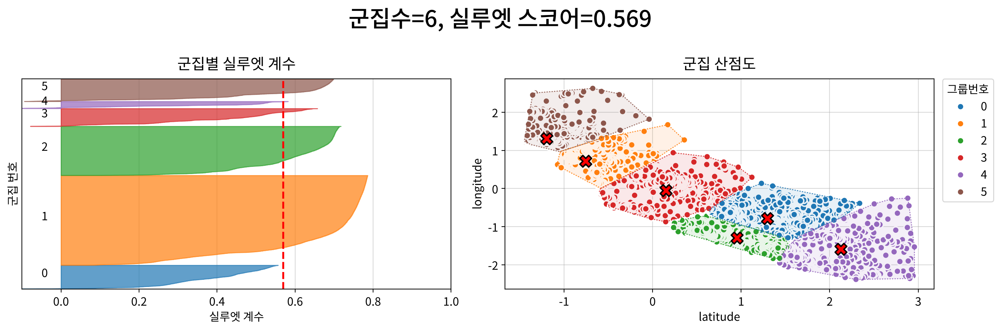

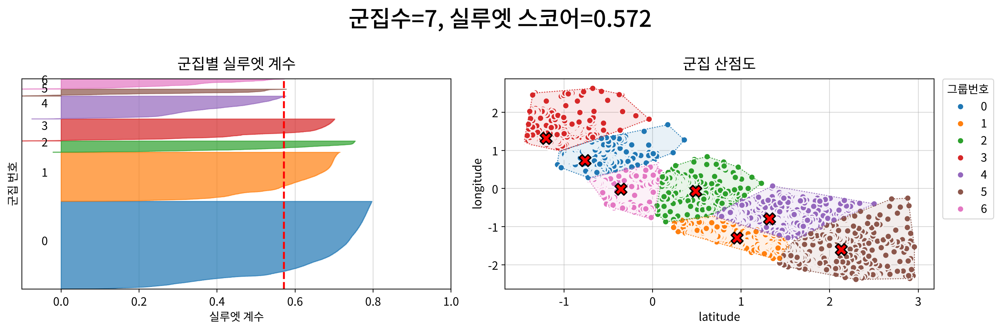

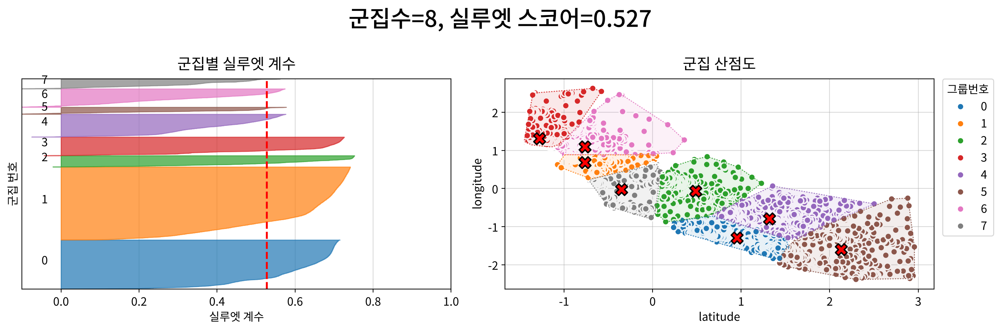

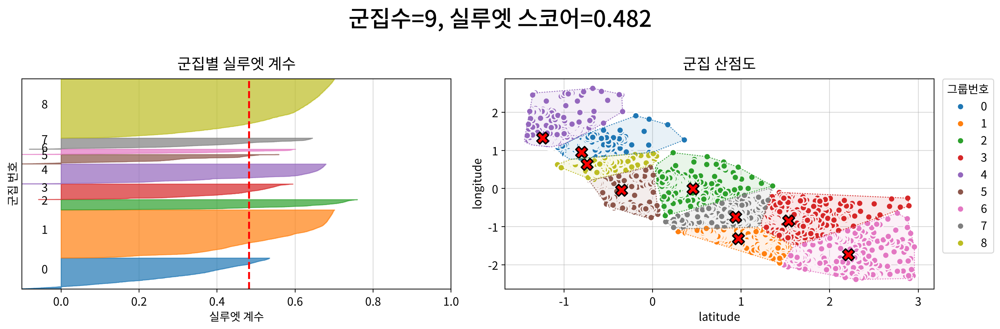

[1단계] 엘보우 포인트 : k = 5 (뭉침만 확인 → 후보)
[2단계] 실루엣 균형지수 : k = 2 (뭉침 + 분리 + 크기 균형)
------------------------------------------------------------
두 지표가 다른 k를 가리킵니다.
 · k = 5 : 균형지수 0.0075 (스코어 0.5806, 두께비 8.9162)
 · k = 2 : 균형지수 0.4318 (스코어 0.755, 두께비 1.3762)
------------------------------------------------------------
>>> 최종 선택: k= 2
     (지표는 후보를 좁혀줄 뿐이므로, 목적과 도메인 지식으로 한 번 더 확인할 것)


In [28]:
final_k, _ = my_cluster.best_k(df, klist=list(range(2, 10)),
                               columns=["latitude", "longitude"],
                               plot_each=True, width=740, height=480)

---
##### 💡 인사이트 — 지표는 k = 2, 최종 선택은 k = 5

| 후보 | 근거 | 실루엣 스코어 | 한계 |
|---|---|---|---|
| k = 2 | 실루엣 균형지수 최대 | **0.755** | '남부 / 북부' 같은 이분화만 가능 — 권역 변수로서 정보가 너무 적다 |
| **k = 5** | **엘보우 포인트** (군집 안의 뭉침이 충분해지는 지점) | 0.581 | 실루엣은 낮지만 0.5 이상으로 군집 품질은 양호 |

- `best_k()`는 **k = 2**를 골랐지만, 이 군집은 모델에 넣을 **권역 변수**를 만드는 게 목적이다. 2개로는 캘리포니아의 지역 차이(대도시권 · 내륙 · 북부 등)를 담기 어렵다.
- 그래서 엘보우와 일치하고 실루엣도 0.5 이상인 **k = 5**를 선택한다.
- → **통계 지표는 후보를 좁혀 줄 뿐**, 최종 선택은 분석 목적과 도메인 지식으로 한다.

---

### (6) 최종 군집 모형 적합

StandardScaler 적용 (2개 컬럼)
컬럼                       변환 전               변환 후
--------------------------------------------------------
latitude           32.54 ~ 41.95          -1.45 ~ 2.96
longitude      -124.35 ~ -114.31          -2.39 ~ 2.63


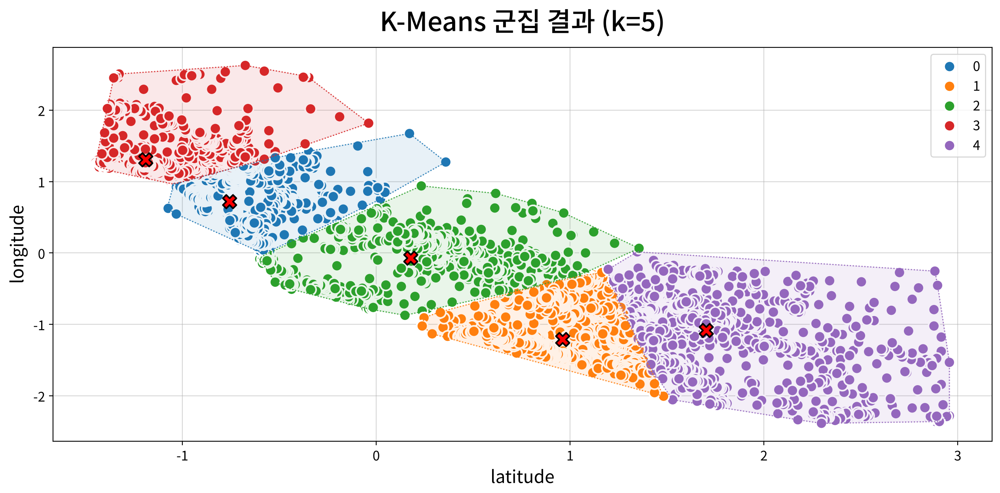

,latitude,longitude,그룹번호
0,1.052,-1.327,1
1,1.042,-1.322,1
2,1.038,-1.332,1
3,1.038,-1.337,1
4,1.038,-1.337,1
...,...,...,...
20428,1.801,-0.758,4
20429,1.805,-0.818,4
20430,1.777,-0.823,4
20431,1.777,-0.873,4


In [29]:
final_k = 5
estimator, cdf, center_df = my_cluster.kmeans(df, k=final_k,
                                              columns=['latitude', 'longitude'])
cdf

---

##### 💡 인사이트

- 모든 구역에 **0 ~ 4번 그룹번호**가 붙었다. 이 번호가 곧 권역이다.
- 출력의 `latitude` · `longitude`는 원래 좌표가 아니라 **표준화된 값**이다. 위도와 경도의 단위 차이가 군집에 영향을 주지 않도록 같은 기준으로 맞춘 것이다.
- 그룹번호는 순서가 아니라 **이름표**다(1번 권역이 0번보다 '크다'는 뜻이 아님).

---

### (7) 공간특성 반영 파생변수 추가

In [30]:
# 군집 결과(그룹번호)를 공간 파생변수로 추가한다
df["spatial_cluster"] = cdf["그룹번호"].astype("category")

# 컬럼 의미 딕셔너리 갱신
column_means.update({
    "spatial_cluster": "위경도 기반 공간 군집",
})

df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,rooms_per_person,rooms_per_household,bedrooms_per_room,population_per_household,income_per_person,is_age_capped,is_income_capped,ocean_area,spatial_cluster
0,-122.230,37.880,41.000,880.000,129.000,322.000,126.000,8.325,"452,600.000",NEAR BAY,2.733,6.984,0.147,2.556,3.258,0,0,COASTAL,1
1,-122.220,37.860,21.000,"7,099.000","1,106.000","2,401.000","1,138.000",8.301,"358,500.000",NEAR BAY,2.957,6.238,0.156,2.110,3.935,0,0,COASTAL,1
2,-122.240,37.850,52.000,"1,467.000",190.000,496.000,177.000,7.257,"352,100.000",NEAR BAY,2.958,8.288,0.130,2.802,2.590,1,0,COASTAL,1
3,-122.250,37.850,52.000,"1,274.000",235.000,558.000,219.000,5.643,"341,300.000",NEAR BAY,2.283,5.817,0.184,2.548,2.215,1,0,COASTAL,1
4,-122.250,37.850,52.000,"1,627.000",280.000,565.000,259.000,3.846,"342,200.000",NEAR BAY,2.880,6.282,0.172,2.181,1.763,1,0,COASTAL,1


In [31]:
# 권역별 건수 · 평균 집값 · 중심 좌표
df.groupby("spatial_cluster", observed=True).agg(
    건수=(target, "size"),
    평균집값=(target, "mean"),
    위도=("latitude", "mean"),
    경도=("longitude", "mean"),
)

,건수,평균집값,위도,경도
spatial_cluster,,,,
0,8729,"230,622.962",34.014,-118.126
1,5639,"241,486.566",37.687,-121.999
2,1787,"121,933.365",36.011,-119.706
3,2211,"177,071.846",33.086,-116.946
4,2067,"117,372.617",39.268,-121.736


---
##### 💡 인사이트 — 좌표 2개가 5개 시장 권역이 됐다

| 군집 | 건수 | 평균 집값 | 중심 좌표 (위도, 경도) | 해당 권역 |
|---|---|---|---|---|
| 0 | 8,729 | 230,623달러 | (34.01, −118.13) | 남부 해안 (로스앤젤레스 권역) |
| 1 | 5,639 | **241,487달러** | (37.69, −122.00) | 북부 해안 (샌프란시스코 베이 권역) |
| 2 | 1,787 | 121,933달러 | (36.01, −119.71) | 중부 내륙 (센트럴밸리) |
| 3 | 2,211 | 177,072달러 | (33.09, −116.95) | 최남부 (샌디에이고 권역) |
| 4 | 2,067 | **117,373달러** | (39.27, −121.74) | 북부 내륙 (새크라멘토 이북) |

- **해안 대도시권(베이 · LA)이 가장 비싸고, 내륙 권역이 가장 싸다.** 가장 비싼 권역과 가장 싼 권역의 평균 차이는 약 12만 달러다.
- 권역 이름은 중심 좌표를 지도와 대조해 붙인 것이다.

---

### (8) 파생변수 생성 최종 결과 정리 (9종)

| 구분 | 파생변수 | 재료 | 의미 | 유형 |
|---|---|---|---|---|
| 규모 해제 | `rooms_per_person` | 방 수 ÷ 인구 | 1인당 방 수 (주거 여유) | 연속형 |
| 규모 해제 | `rooms_per_household` | 방 수 ÷ 가구 수 | 가구당 방 수 (주택 규모) | 연속형 |
| 규모 해제 | `bedrooms_per_room` | 침실 수 ÷ 방 수 | 방 중 침실 비율 (낮을수록 거실 · 기타 공간이 넓음) | 연속형 |
| 규모 해제 | `population_per_household` | 인구 ÷ 가구 수 | 가구당 인구 (과밀도) | 연속형 |
| 구매력 | `income_per_person` | 중위 소득 ÷ 가구당 인구 | 1인당 소득 | 연속형 |
| 절단 표시 | `is_age_capped` | 주택 연령 ≥ 52 | 주택 연령 상한 절단 여부 (1,265건) | 범주형 (0 / 1) |
| 절단 표시 | `is_income_capped` | 중위 소득 ≥ 15.0 | 소득 상한 절단 여부 (50건) | 범주형 (0 / 1) |
| 범주 재구성 | `ocean_area` | 해양 근접도 5범주 | 내륙 / 해안권 2범주 | 범주형 |
| 공간 특성 | `spatial_cluster` | 위도 · 경도 K-means 군집 (k = 5) | 위경도 기반 공간 군집 | 범주형 (5범주) |

- 규모 해제 4종 · 구매력 1종 · 절단 표시 2종 · 범주 재구성 1종 · 공간 특성 1종 → **9종**

---

# PART 4. 파생변수 검증

- PART 3에서 만든 파생변수 9종이 실제로 집값을 설명하는지, **EDA와 같은 절차**(단변량 → 이변량 → 다변량)로 확인한다.

### (1) 변수 유형 구분

- 검증 대상은 새로만든 파생변수이다 (원본 변수는 EDA에서 이미 확인 완료).

In [32]:
# 연속형 파생변수
derived_continuous = ['rooms_per_person', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_per_person']

# 범주형 파생변수
derived_nominal = ['is_age_capped', 'is_income_capped', 'ocean_area', 'spatial_cluster']

print("연속형 파생변수 :", derived_continuous)
print("범주형 파생변수 :", derived_nominal)

연속형 파생변수 : ['rooms_per_person', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_per_person']
범주형 파생변수 : ['is_age_capped', 'is_income_capped', 'ocean_area', 'spatial_cluster']


### (2) 데이터 타입 변환

In [33]:
df = my_qtcheck.set_type(df, as_category=derived_nominal)

<class 'pandas.DataFrame'>
RangeIndex: 20433 entries, 0 to 20432
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   longitude                 20433 non-null  float64 
 1   latitude                  20433 non-null  float64 
 2   housing_median_age        20433 non-null  float64 
 3   total_rooms               20433 non-null  float64 
 4   total_bedrooms            20433 non-null  float64 
 5   population                20433 non-null  float64 
 6   households                20433 non-null  float64 
 7   median_income             20433 non-null  float64 
 8   median_house_value        20433 non-null  float64 
 9   ocean_proximity           20433 non-null  category
 10  rooms_per_person          20433 non-null  float64 
 11  rooms_per_household       20433 non-null  float64 
 12  bedrooms_per_room         20433 non-null  float64 
 13  population_per_household  20433 non-null  float64 
 14  i

### (3) 명목형 변수 기술통계량

In [34]:
derived_cat_desc = my_qtcheck.categorical_summary(df, 
                        columns=derived_nominal, value_counts=False)
derived_cat_desc

,is_age_capped,is_income_capped,ocean_area,spatial_cluster
count,20433,20433,20433,20433
unique,2,2,2,5
top,0,0,COASTAL,0
freq,19168,20383,13937,8729


### (4) 연속형 변수 기술통계량

In [35]:
derived_num_desc = my_qtcheck.numerical_summary(df, columns=derived_continuous)
derived_num_desc.T

,rooms_per_person,rooms_per_household,bedrooms_per_room,population_per_household,income_per_person
count,"20,433.000","20,433.000","20,433.000","20,433.000","20,433.000"
mean,1.978,5.431,0.213,3.072,1.409
std,1.150,2.483,0.058,10.438,0.755
min,0.003,0.846,0.100,0.692,0.008
25%,1.524,4.441,0.175,2.429,0.870
50%,1.938,5.231,0.203,2.818,1.296
75%,2.297,6.052,0.240,3.282,1.777
max,55.222,141.909,1.000,"1,243.333",7.550
rel_diff,0.021,0.038,0.049,0.090,0.087
rdiff_flag,similar,similar,similar,similar,similar


---
##### 💡 인사이트

| 변수 | 왜도 | 첨도 | 이상치 (전체) | 최댓값 | 처리 |
|---|---|---|---|---|---|
| `rooms_per_person` | 17.76 | 597.9 | 399건 (2.0%) | 55.2 | log |
| `rooms_per_household` | 20.68 | 875.7 | 508건 (2.5%) | 141.9 | log |
| `bedrooms_per_room` | 2.25 | 14.4 | 582건 (2.8%) | 1.0 | log |
| `population_per_household` | **97.16** | **10,545.2** | 709건 (3.5%) | **1,243.3** | log |
| `income_per_person` | 1.46 | 4.2 | 616건 (3.0%) | 7.6 | log |

- **5종 모두 평균과 중앙값이 가깝다**(`rel_diff` 0.02 ~ 0.09, 모두 `similar`). 대부분의 구역은 고르게 모여 있다는 뜻이다.
- 비율로 바꾸자 **이상치 비율은 2.0 ~ 3.5%로 줄었다.** 원본 규모 변수는 6% 안팎이었다.
- 그런데 **왜도와 첨도는 오히려 커진 변수가 있다.** 소수 구역의 극단값 때문이다.
  - `population_per_household`의 최댓값은 가구당 **1,243명**으로, 중앙값(2.8명)과 비교하면 현실의 가구로 보기 어려운 값이다. 가구 수가 아주 적은 구역에서 나눗셈 결과가 커진 것으로 보인다.
  - `rooms_per_household`(최대 141.9개) · `rooms_per_person`(최대 55.2개)도 같은 이유로 꼬리가 길다.
- `bedrooms_per_room`과 `income_per_person`은 왜도가 2 안팎으로 **비교적 안정적**이다. `income_per_person`(1.46)은 재료인 `median_income`(1.65)보다도 덜 치우쳤다.
- 5종 모두 `log_need = log` → **로그 변환 대상**이다.

---

## 4-1. 단변량 분석

### (1) 연속형 파생변수

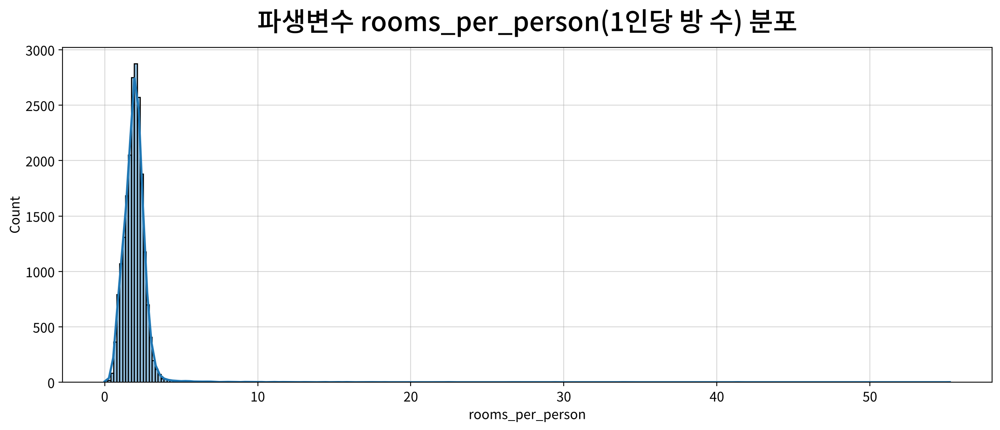

,rooms_per_person
count,"20,433.000"
mean,1.978
std,1.150
min,0.003
25%,1.524
50%,1.938
75%,2.297
max,55.222
rel_diff,0.021
rdiff_flag,similar


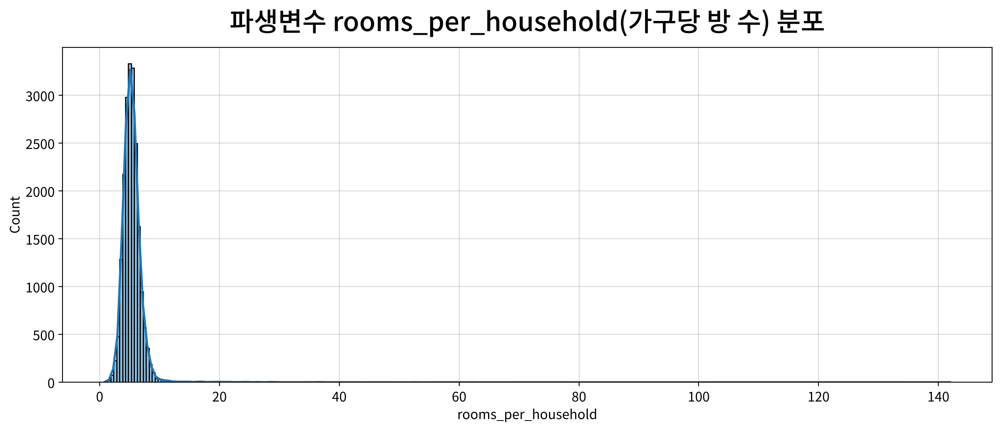

,rooms_per_household
count,"20,433.000"
mean,5.431
std,2.483
min,0.846
25%,4.441
50%,5.231
75%,6.052
max,141.909
rel_diff,0.038
rdiff_flag,similar


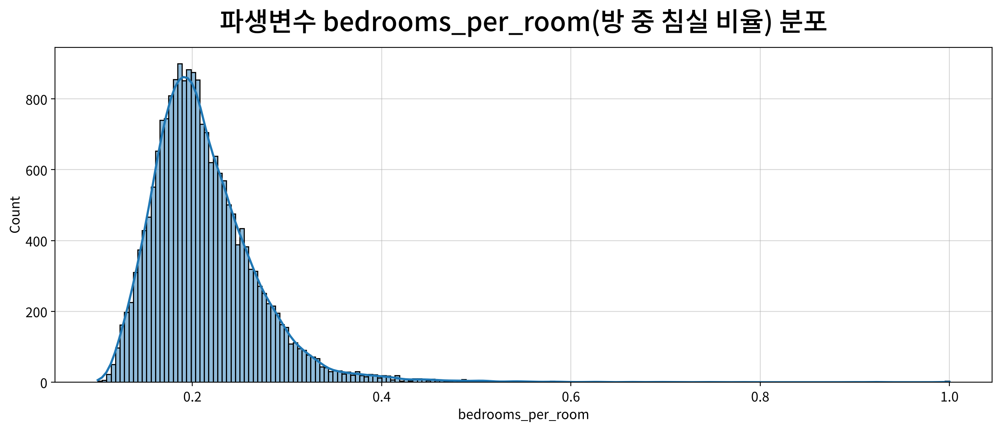

,bedrooms_per_room
count,"20,433.000"
mean,0.213
std,0.058
min,0.100
25%,0.175
50%,0.203
75%,0.240
max,1.000
rel_diff,0.049
rdiff_flag,similar


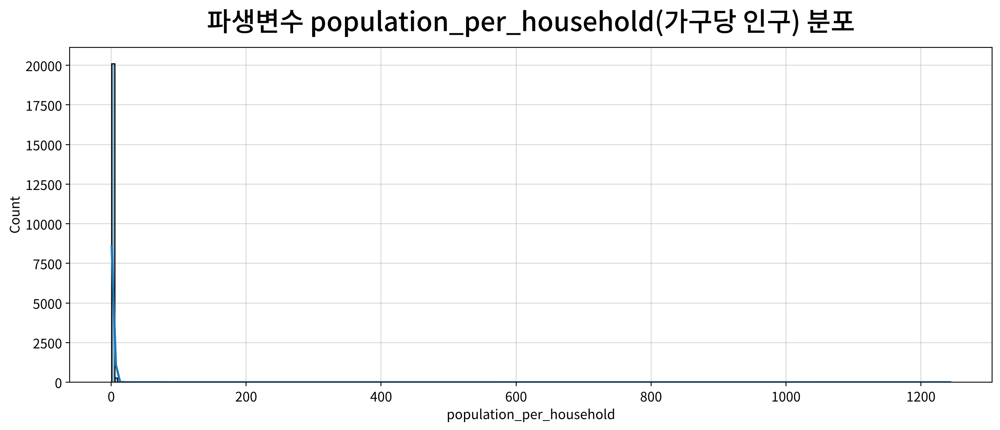

,population_per_household
count,"20,433.000"
mean,3.072
std,10.438
min,0.692
25%,2.429
50%,2.818
75%,3.282
max,"1,243.333"
rel_diff,0.090
rdiff_flag,similar


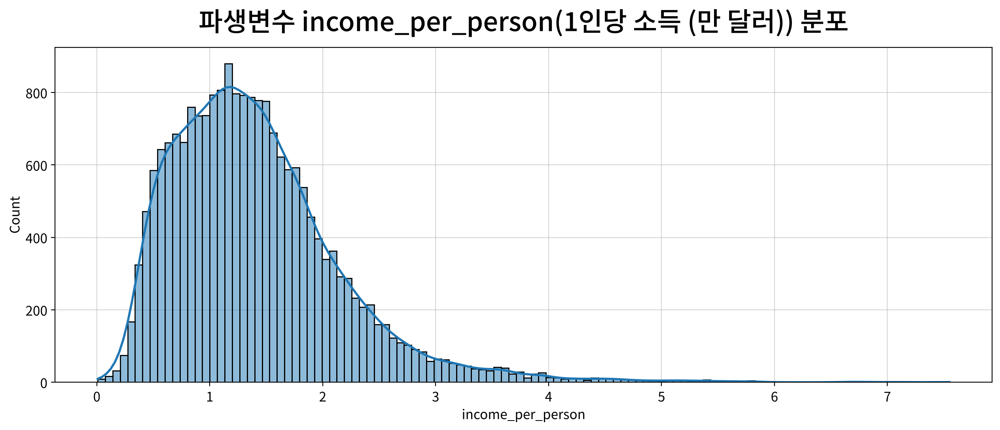

,income_per_person
count,"20,433.000"
mean,1.409
std,0.755
min,0.008
25%,0.870
50%,1.296
75%,1.777
max,7.550
rel_diff,0.087
rdiff_flag,similar


In [36]:
for f in derived_continuous:
    # 히스토그램만 그리는 경우
    my_plot.histplot(data=df, x=f, kde=True, width=1280, height=560,
                    title=f"파생변수 {f}({column_means[f]}) 분포")

    display(derived_num_desc[derived_num_desc.index == f].T)

---

##### 💡 인사이트

- 판정 기준 : **왜도 ≥ 1**, 또는 **왜도 > 0.5 이면서 첨도 > 0** 이면 우측 꼬리 → 로그 변환

| 변수 | 왜도 | 첨도 | 꼬리 방향 (`skew_interpret`) | 이상치 | 로그 변환 | 비고 |
|---|---|---|---|---|---|---|
| `rooms_per_person` | +17.76 | 597.9 | 우측 꼬리 | 399건 (2.0%) | ✅ log | |
| `rooms_per_household` | +20.68 | 875.7 | 우측 꼬리 | 508건 (2.5%) | ✅ log | |
| `bedrooms_per_room` | +2.25 | 14.4 | 우측 꼬리 | 582건 (2.8%) | ✅ log | |
| `population_per_household` | +97.16 | 10,545.2 | 우측 꼬리 | 709건 (3.5%) | ✅ log | 왜도가 가장 큼. 최댓값 1,243.3명/가구 |
| `income_per_person` | +1.46 | 4.2 | 우측 꼬리 | 616건 (3.0%) | ✅ log | 5종 중 왜도가 가장 작음. 원본 `median_income`(+1.65)보다 덜 치우침 |

- **5종 모두 로그 변환 대상**이다. 
- 비율로 바꾸자 **이상치 비율은 2.0 ~ 3.5%로 줄었다.** 원본 규모 변수는 6% 안팎이었다.
- 반면 `rooms_per_person` · `rooms_per_household` · `population_per_household`는 **왜도가 원본(3.4 ~ 5.0)보다 커졌다.** 일부 구역의 극단값 때문이며, PART 5의 로그 변환으로 완화한다.

---

### (2) 명목형 파생변수

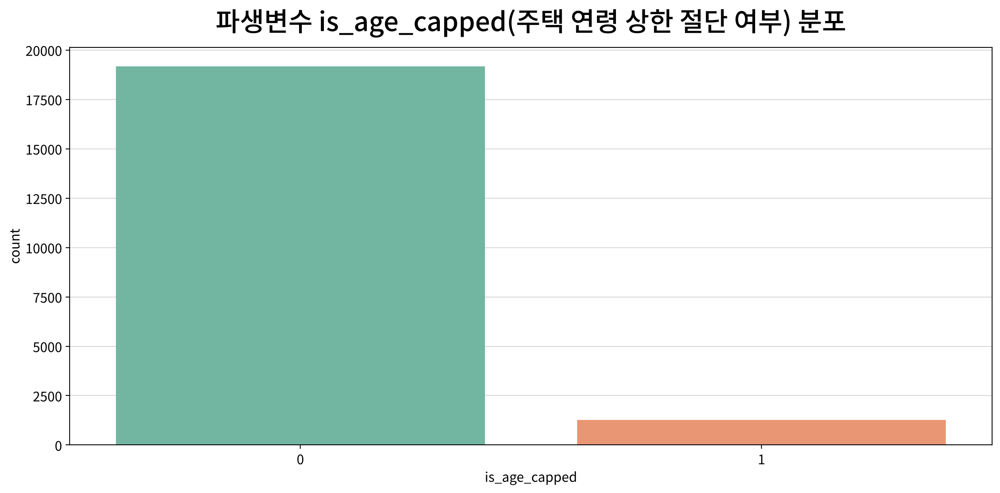

,count,unique,top,freq
is_age_capped,20433,2,0,19168


,빈도,비율
is_age_capped,,
0,19168,0.938
1,1265,0.062


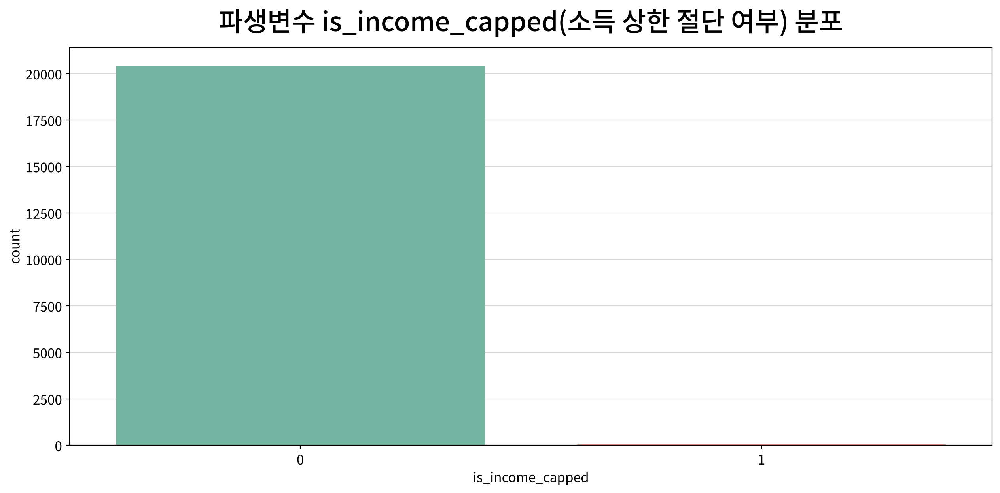

,count,unique,top,freq
is_income_capped,20433,2,0,20383


,빈도,비율
is_income_capped,,
0,20383,0.998
1,50,0.002


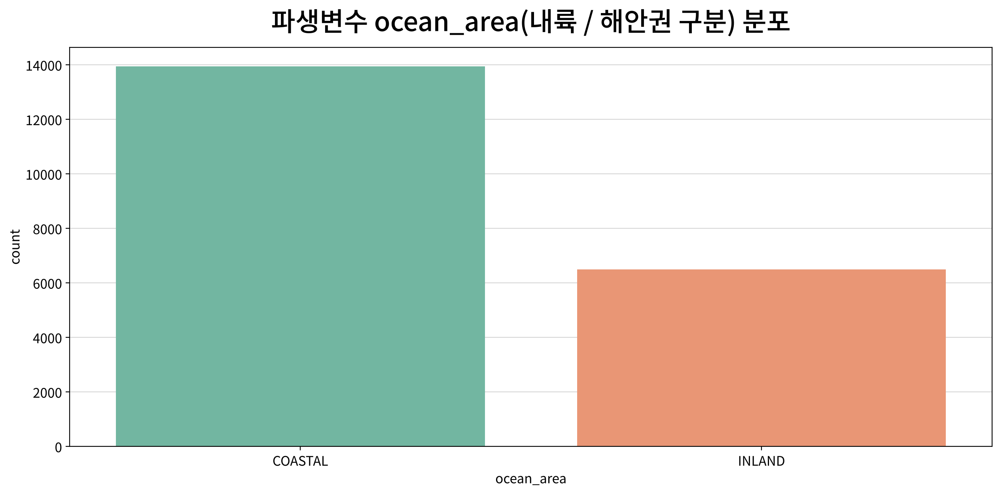

,count,unique,top,freq
ocean_area,20433,2,COASTAL,13937


,빈도,비율
ocean_area,,
COASTAL,13937,0.682
INLAND,6496,0.318


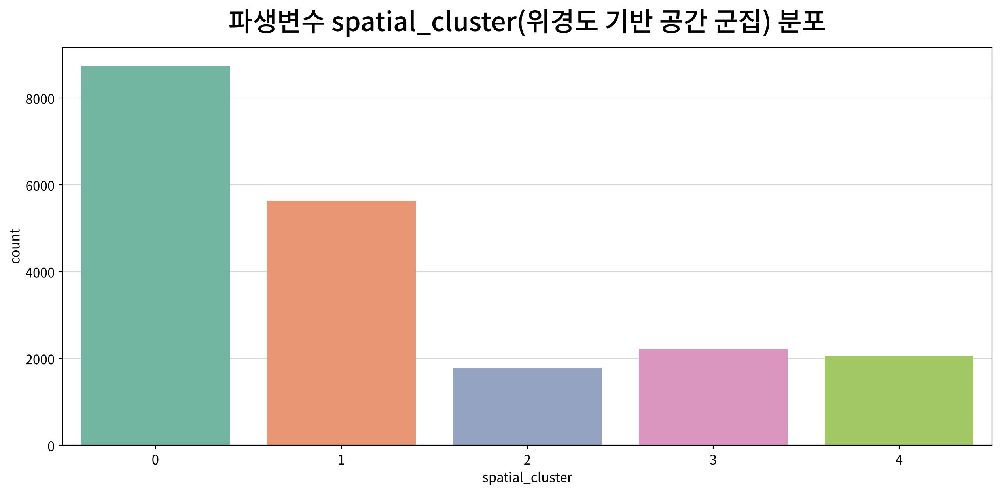

,count,unique,top,freq
spatial_cluster,20433,5,0,8729


,빈도,비율
spatial_cluster,,
0,8729,0.427
1,5639,0.276
3,2211,0.108
4,2067,0.101
2,1787,0.087


In [37]:
for n in derived_nominal:
    # 범주형 분포는 카운트 플롯으로 처리한다.
    my_plot.countplot(data=df, x=n, hue=n, palette="Set2",
                      title=f"파생변수 {n}({column_means[n]}) 분포")

    # 범주형 기술통계량
    display(derived_cat_desc[[n]].T)

    # 추가적으로 빈도표 생성
    freq = df[n].value_counts().rename("빈도").to_frame()
    freq["비율"] = df[n].value_counts(normalize=True)
    display(freq)

---

##### 💡 인사이트

| 변수 | 범주 수 | 최빈 범주(비율) | 최소 범주(비율) | 균형 여부 | 판단·조치 |
|---|---|---|---|---|---|
| `ocean_area` | 2 | COASTAL : 13,937 (68.2%) | INLAND : 6,496건 (31.8%) | 양호 | 병합 목적 달성 |
| `is_age_capped` | 2 | 0 : 19,168 (93.8%) | 1 : 1,265건 (6.2%) | 불균형 | 검정에 충분 |
| `is_income_capped` | 2 | 0 : 20,383 (99.8%) | 1 : 50건 (0.2%) | 극심한 불균형 | 심한 불균형. 채택하지 않는 것을 고려 |
| `spatial_cluster` | 5 | 0 : 8,729 (42.7%) | 2 : 1,787건 (8.7%) | 다소 불균형 | 가장 작은 권역도 1,700건 이상 → 검정에 충분 |

- **`ocean_area`의 병합은 의도대로 작동했다.** 병합 전 `ocean_proximity`는 최빈 44.2%\~최소 0.02%(`ISLAND` 5건)의 5범주였다. 2범주로 줄인 뒤 최소 범주가 6,496건(31.8%)이 되어 불균형 문제가 사라졌다.
- **`is_income_capped` 50건(0.2%)은 EDA의 `ISLAND` 5건과 같은 성격의 문제다.** 표본이 적으면 그 범주의 추정치가 불안정해진다. `ISLAND`는 병합으로 해결했지만 이 플래그는 병합할 대상이 없으므로, 투입 여부를 별도로 판단해야 한다.
- `is_age_capped`는 1,265건(6.2%)으로 소수 범주지만 검정에는 충분하다.

---

## 4-2. 이변량 분석

### (1) 상관분석 : 연속형 파생변수 → 집값

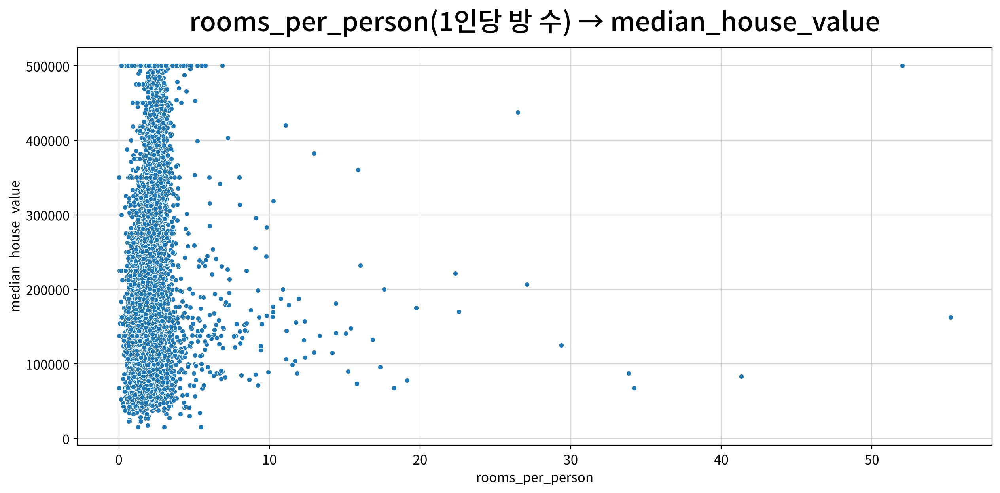

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
rooms_per_person,median_house_value,Spearman,0.400,0.000,Moderate,True,False,False,False,True,True


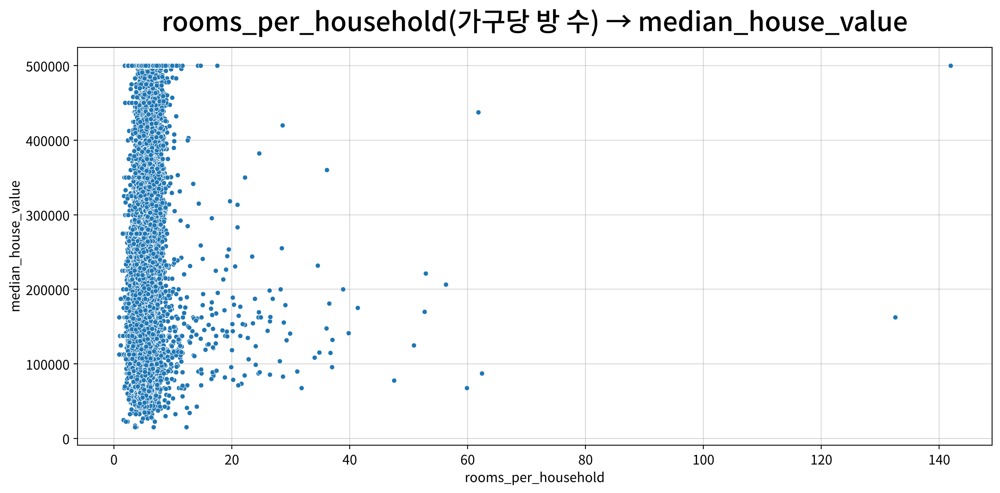

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
rooms_per_household,median_house_value,Spearman,0.263,0.000,Weak,True,False,False,False,True,True


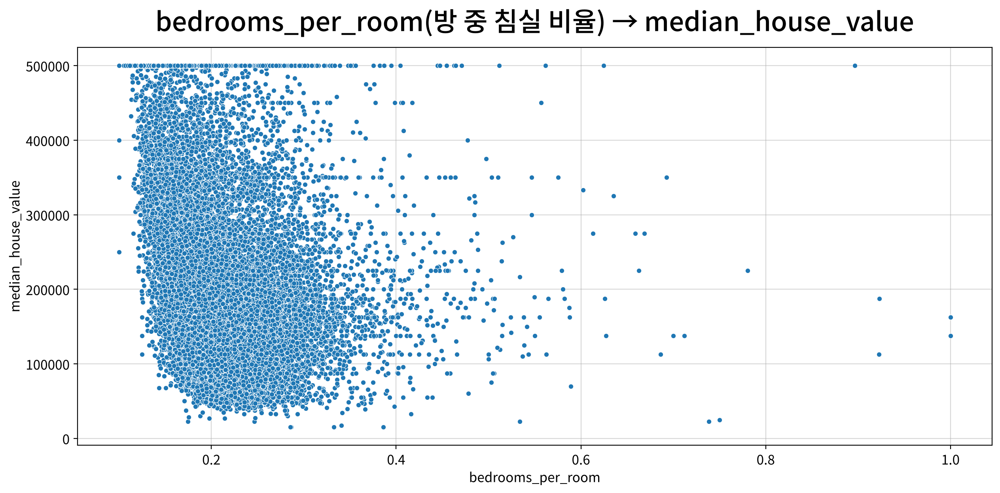

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
bedrooms_per_room,median_house_value,Spearman,-0.332,0.000,Moderate,True,False,False,False,False,True


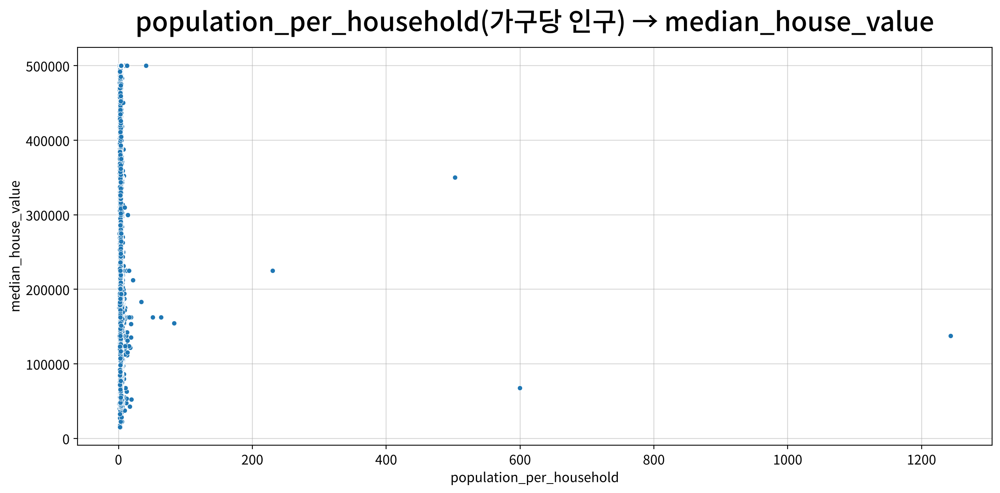

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
population_per_household,median_house_value,Spearman,-0.256,0.000,Weak,True,False,False,False,True,True


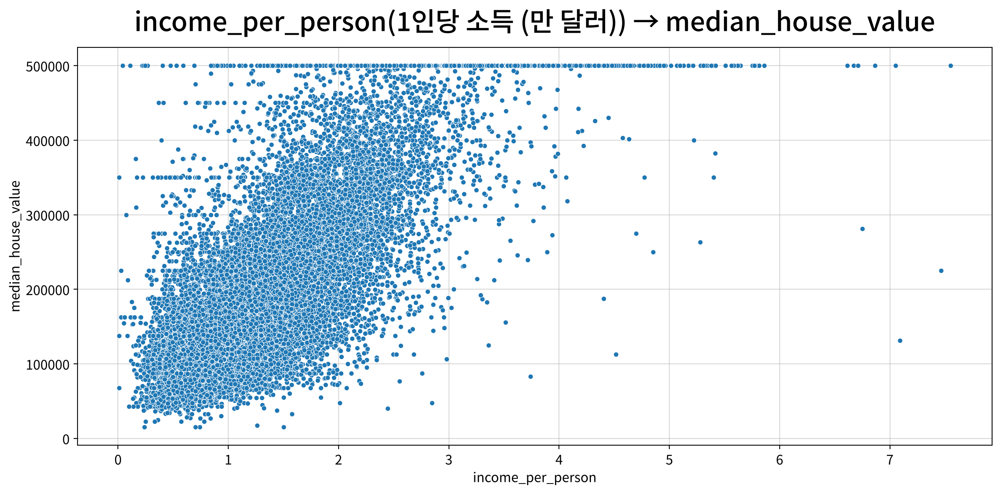

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential_outlier,high_skew
x,y,,,,,,,,,,
income_per_person,median_house_value,Spearman,0.722,0.000,Strong,True,False,False,False,False,True


In [38]:
for f in derived_continuous:
    # 시각화
    my_plot.scatterplot(data=df, x=f, y=target, outline=False,
                        linewidth=0.4, size=20,
                        title=f"{f}({column_means[f]}) → {target}")

    # my_stats는 시각화까지 일괄처리 한다.
    display(my_stats.correlation(df, x=f, y=target, plot=False))

---
##### 💡 인사이트 — 비율로 바꾸자 신호가 살아났다

- 판정 기준 : **유의(p < 0.05) + |ρ| ≥ 0.3 → ✅ 채택**, 유의하지만 0.1 ≤ |ρ| < 0.3 → 🟡 보류

| 판정 | 변수 | coef (Spearman) | 강도 | EDA의 재료 변수 coef |
|---|---|---|---|---|
| ✅ 채택 | `rooms_per_person` | +0.400 | Moderate | `total_rooms` +0.205 |
| 🟡 보류 | `rooms_per_household` | +0.263 | Weak | `total_rooms` +0.205 |
| ✅ 채택 | `bedrooms_per_room` | **−0.332** | Moderate | `total_bedrooms` +0.086 |
| 🟡 보류 | `population_per_household` | −0.256 | Weak | `population` +0.003 (비유의) |
| ✅ 채택 | `income_per_person` | **+0.722** | **Strong** | `median_income` +0.677 |

- **5종 모두 유의**하다. EDA에서 유일하게 비유의였던 `population`도, 재료로 쓴 `rooms_per_person` · `population_per_household`에서는 유의한 변수가 됐다.
- **Moderate 이상이 1개 → 3개로 늘었다.** 총량 변수에서는 '크기' 효과가 집값 신호를 덮고 있었다는 EDA의 판단이 수치로 확인됐다.
- **`income_per_person`은 데이터셋에서 유일한 Strong 변수**다. 가구 소득보다 **1인당 구매력**이 집값과 더 가깝게 움직인다.
- **음의 관계는 두 변수**다.
  - `bedrooms_per_room`(−0.332) : 방 중 침실 비율이 낮을수록(= 거실 · 기타 공간의 비중이 클수록) 비싸다.
  - `population_per_household`(−0.256) : 가구당 인구가 많을수록(= 과밀할수록) 싸다.
  - 둘 다 총량 변수로는 볼 수 없던 관계다. 재료인 `total_bedrooms` · `population`은 집값과 양(+)이거나 관계가 없었다.

---

### (2) T검정 : 2집단 명목형 파생변수 → 집값

#### ▶︎ is_age_capped(주택 연령 상한 절단 여부) → median_house_value

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: Mann-Whitney-Wilcoxon test two-sided, P_val:1.136e-75 U_stat=8.384e+06


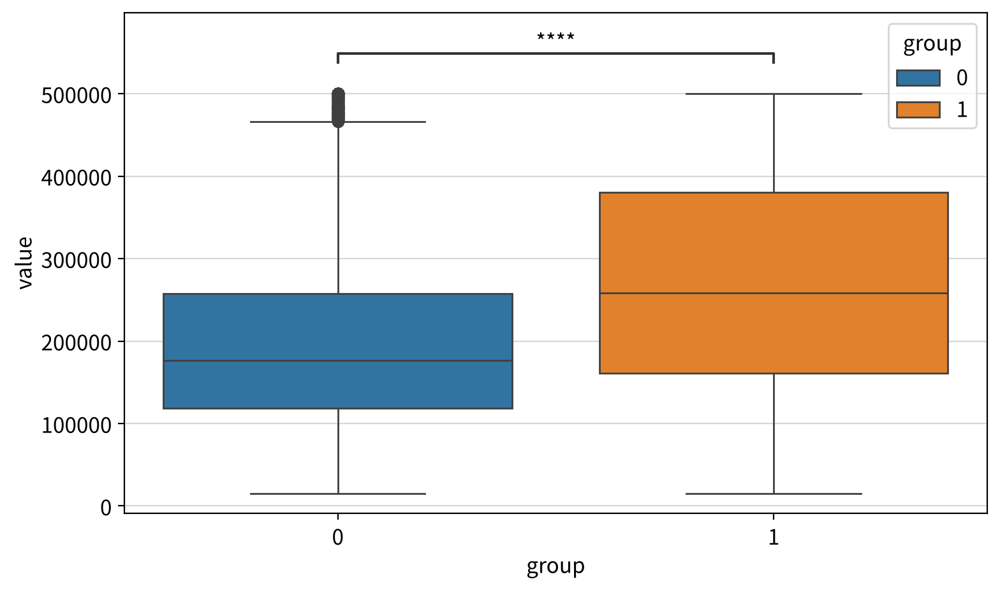

statistic  p-value  significant result
test                alternative                                           
Mann-Whitney U test two-sided   8,383,512.000    0.000         True  0 ≠ 1
                    less        8,383,512.000    0.000         True  0 < 1
                    greater     8,383,512.000    1.000        False  0 ≤ 1

#### ▶︎ is_income_capped(소득 상한 절단 여부) → median_house_value

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: Mann-Whitney-Wilcoxon test two-sided, P_val:1.829e-29 U_stat=4.007e+04


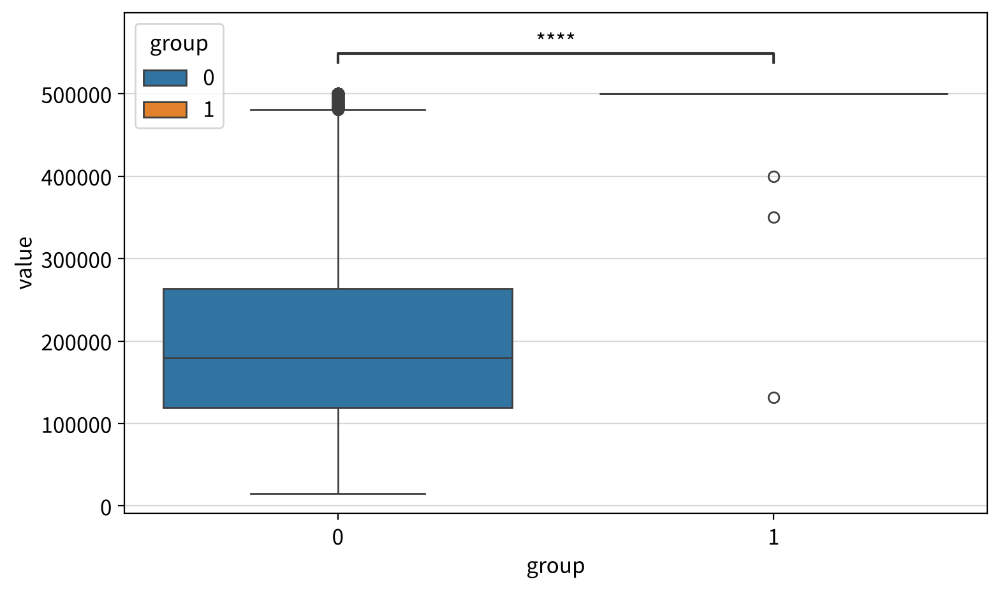

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided   40,072.000    0.000         True  0 ≠ 1
                    less        40,072.000    0.000         True  0 < 1
                    greater     40,072.000    1.000        False  0 ≤ 1

#### ▶︎ ocean_area(내륙 / 해안권 구분) → median_house_value

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

COASTAL vs. INLAND: Mann-Whitney-Wilcoxon test two-sided, P_val:0.000e+00 U_stat=7.704e+07


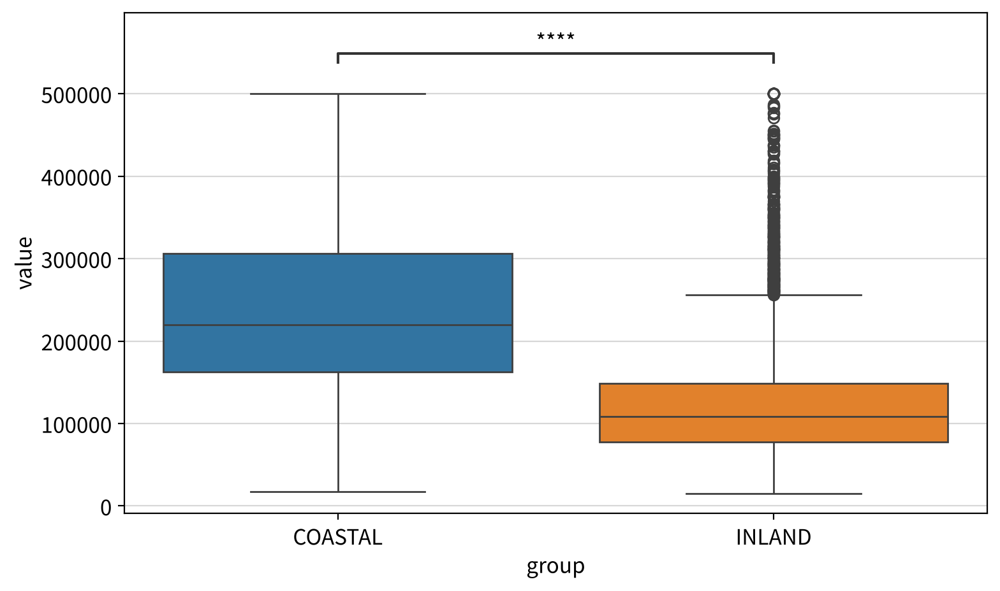

statistic  p-value  significant  \
test                alternative                                        
Mann-Whitney U test two-sided   77,038,278.500    0.000         True   
                    less        77,038,278.500    1.000        False   
                    greater     77,038,278.500    0.000         True   

                                           result  
test                alternative                    
Mann-Whitney U test two-sided    COASTAL ≠ INLAND  
                    less         COASTAL ≥ INLAND  
                    greater      COASTAL > INLAND

In [39]:
for n in derived_nominal:
    # 2개의 고유값만 존재하는 범주형 독립변수에 대해서만 검정을 수행한다.
    if len(df[n].unique()) == 2:
        # 빈 줄 출력용
        print()

        # 분석 단위 제목 출력
        display(Markdown(f"#### ▶︎ {n}({column_means[n]}) → {target}"))

        # 수집된 데이터가 long 타입이므로 검정 대상만 wide 타입으로 변환해야 한다.
        wide_df = my_prep.long2wide(df, hue=n, values=target)
        display(my_stats.test_independent(wide_df,
                    group1=wide_df.columns[0], group2=wide_df.columns[1],
                    width=800, height=480))

---
##### 💡 인사이트

| 판정 | 변수 | 검정 | 방향 | 건수 (해당) |
|---|---|---|---|---|
| ✅ 채택 | `ocean_area` | Mann-Whitney U, p < 0.001 | COASTAL > INLAND | 13,937 / 6,496 |
| 🟡 보류 | `is_age_capped` | Mann-Whitney U, p < 0.001 | 1 (52년 이상) > 0 | 1,265 |
| ⚠️ 주의 | `is_income_capped` | Mann-Whitney U, p < 0.001 | 1 (소득 상한) > 0 | **50** |

- **`ocean_area`는 5범주를 2범주로 줄여도 집값 차이가 뚜렷하다.** 해안권(COASTAL)이 내륙(INLAND)보다 유의하게 비싸, EDA에서 확인한 '내륙 vs 해안권' 구조가 그대로 유지됐다.
- **`is_age_capped`는 주택 연령 숫자로는 안 보이던 정보를 담는다.** 주택 연령과 집값의 상관은 거의 없었지만(ρ = 0.075), **가장 오래된 동네(52년 이상)** 만 떼어 보면 유의하게 비싸다. 다만 `housing_median_age`에서 만든 변수라 둘의 정보가 겹칠 수 있어 **보류**로 두고, 모델에서 확인한다.
- **`is_income_capped`는 유의하지만 주의가 필요하다.** 소득 상한 구역은 50곳(0.2%)뿐이라, 몇 곳만 바뀌어도 결과가 크게 흔들린다. EDA에서 `ISLAND`(5곳)를 해석에 쓰지 않은 것과 같은 이유다.

---

### (3) ANOVA : 3집단 이상 명목형 파생변수 → 집값 

- 일원분산분석 + 사후검정

In [40]:
for n in derived_nominal:
    # 3개 이상의 고유값이 존재하는 범주형 독립변수에 대해서만 검정을 수행한다.
    if len(df[n].unique()) >= 3:
        print() # 빈 줄 출력용

        # 분석 단위 제목 출력
        display(Markdown(f"#### ▶︎ {n}({column_means[n]}) → {target}"))

        # 분산분석
        display(my_stats.anova_oneway(df, y=target, between=n))

        # 사후검정
        display(my_stats.posthoc_oneway(df, y=target, between=n, plot=False))

#### ▶︎ spatial_cluster(위경도 기반 공간 군집) → median_house_value

,test,Source,ddof1,ddof2,F,p_unc,np2,effect_size
0,welch_anova,spatial_cluster,4,"6,534.723","1,697.721",0.000,0.158,Large


비교한 조합 쌍: 10개
유의한 쌍: 9개
평균 차이가 가장 큰 쌍: (1) vs (4)→ 차이 124113.949, 효과크기 Large, p=value 0.000
평균 차이가 가장 작은 쌍: (2) vs (4)→ 차이 4560.748, 효과크기 Negligible, p-value 0.342


,test,A,B,mean_A,mean_B,diff,se,T,df,pval,hedges,significant,effect_size
0,Games-Howell,0,1,"230,622.962","241,486.566","-10,863.603","1,968.359",-5.519,"11,694.548",0.000,-0.095,True,Negligible
1,Games-Howell,0,2,"230,622.962","121,933.365","108,689.597","2,460.882",44.167,"3,025.748",0.000,0.996,True,Large
2,Games-Howell,0,3,"230,622.962","177,071.846","53,551.117","2,389.418",22.412,"3,857.101",0.000,0.489,True,Small
3,Games-Howell,0,4,"230,622.962","117,372.617","113,250.345","1,697.879",66.701,"6,729.750",0.000,1.090,True,Large
4,Games-Howell,1,2,"241,486.566","121,933.365","119,553.201","2,651.608",45.087,"3,825.428",0.000,1.075,True,Large
5,Games-Howell,1,3,"241,486.566","177,071.846","64,414.720","2,585.422",24.915,"4,828.822",0.000,0.577,True,Medium
6,Games-Howell,1,4,"241,486.566","117,372.617","124,113.949","1,964.148",63.190,"7,306.678",0.000,1.194,True,Large
7,Games-Howell,2,3,"121,933.365","177,071.846","-55,138.481","2,977.567",-18.518,"3,912.569",0.000,-0.585,True,Medium
8,Games-Howell,2,4,"121,933.365","117,372.617","4,560.748","2,457.515",1.856,"2,833.138",0.342,0.062,False,Negligible
9,Games-Howell,3,4,"177,071.846","117,372.617","59,699.229","2,385.950",25.021,"3,520.904",0.000,0.752,True,Medium


---
##### 💡 인사이트

| 변수 | 집단 차이 | 효과크기 | 사후검정 | 판정 |
|---|---|---|---|---|
| `spatial_cluster` | 유의 (Welch F = 1,697.7, p < 0.001) | np² = **0.158 (Large)** | 10쌍 중 9쌍 유의 | ✅ 채택 |

- **좌표 두 개로 만든 변수 하나가 집값 변동의 15.8%를 설명**한다.
- 유일하게 차이가 없는 쌍은 **중부 내륙(2번)과 북부 내륙(4번)** 이다(평균 차이 약 4,600달러, p = 0.342). 두 내륙 권역은 위치는 달라도 **가격대가 같다.**
- 차이가 가장 큰 쌍은 **베이 권역(1번)과 북부 내륙(4번)** 으로, 평균 약 12.4만 달러 차이다(효과크기 Large).
- 앞의 Moran's I(0.790)가 말한 '이웃끼리 집값이 닮는 구조'가, **구체적인 시장 권역**으로 확인됐다.

---

## 4-3. 다변량 분석 

- 연속형 파생변수끼리 상관관계 분석

In [41]:
corr = my_stats.multi_correlation(df, columns=derived_continuous, plot=False)
my_stats.correlation_summary(corr)

,rooms_per_person,rooms_per_household,bedrooms_per_room,population_per_household,income_per_person
rooms_per_person,1.000,0.662,-0.542,-0.675,0.737
rooms_per_household,0.662,1.000,-0.888,0.018,0.536
bedrooms_per_room,-0.542,-0.888,1.000,-0.080,-0.599
population_per_household,-0.675,0.018,-0.080,1.000,-0.469
income_per_person,0.737,0.536,-0.599,-0.469,1.000


,max-y,max-coef,count,columns
x,,,,
bedrooms_per_room,rooms_per_household,-0.888,1,rooms_per_household
rooms_per_household,bedrooms_per_room,-0.888,1,bedrooms_per_room
income_per_person,rooms_per_person,0.737,1,rooms_per_person
rooms_per_person,income_per_person,0.737,1,income_per_person
population_per_household,rooms_per_person,-0.675,0,-


---
##### 💡 인사이트

- 연속형 파생변수 5종끼리도 **중복이 남아 있다.** 재료가 같은 원본 변수라, 분자나 분모를 공유하기 때문이다.
  - `bedrooms_per_room` ↔ `rooms_per_household` −0.888
  - `income_per_person` ↔ `rooms_per_person` 0.737
- 다만 EDA의 총량 4종(서로 0.90 이상)보다는 나아졌다. 어느 변수를 남길지는 모델링 단계의 **VIF · 변수 중요도**로 판정한다.

---

## 4-4. 종합 판단

| 판정 | 변수 | 검정 | 효과 | 비대칭 | 공선성 | 근거 |
|---|---|---|---|---|---|---|
| ✅ 채택 | `income_per_person` | Spearman | ρ = +0.722 (Strong) | 우편향 (1.46) → log | `rooms_per_person` 0.737 | 데이터셋 유일의 Strong. 원본 `median_income`(0.677)보다 강함 |
| ✅ 채택 | `ocean_area` | Mann-Whitney U | COASTAL > INLAND (p < 0.001) | — | — | 2범주로 줄여도 차이 유지 |
| ✅ 채택 | `spatial_cluster` | Welch ANOVA | np² = 0.158 (Large) | — | `ocean_area`와 일부 겹칠 수 있음 | 위치 효과를 5개 권역으로 담음 |
| ✅ 채택 | `rooms_per_person` | Spearman | ρ = +0.400 (Moderate) | 극단 우편향 → log | `income_per_person` 0.737 | 원본 `total_rooms`(0.205)의 약 2배 |
| ✅ 채택 | `bedrooms_per_room` | Spearman | ρ = −0.332 (Moderate) | 우편향 → log | `rooms_per_household` −0.888 | 총량으로는 못 보던 음의 관계 |
| 🟡 보류 | `is_age_capped` | Mann-Whitney U | 52년 이상이 더 비쌈 (p < 0.001) | — | — | 연속형 연령이 못 잡던 신호 |
| 🟡 보류 | `rooms_per_household` | Spearman | ρ = +0.263 (Weak) | 극단 우편향 → log | `bedrooms_per_room` −0.888 | 둘 중 하나만 → VIF로 판정 |
| 🟡 보류 | `population_per_household` | Spearman | ρ = −0.256 (Weak) | 가장 심함 → log | `rooms_per_person` −0.675 | 설명력이 가장 약함 |
| 🟡 보류 | `housing_median_age` | Spearman | ρ = +0.075 (Weak) | 대칭 | 없음 | 중복이 없어 원본 그대로 유지 |
| ⚠️ 주의 | `is_income_capped` | Mann-Whitney U | 소득 상한이 더 비쌈 (p < 0.001) | — | — | 50건뿐 → 추정 불안정 |

- 투입 후보는 **10종**(원본 `housing_median_age` 1 + 연속형 파생 5 + 범주형 파생 3 + 공간 파생 1)이다. 보류 · 주의 변수도 일단 넣고, 모델링에서 **VIF 제거와 변수 중요도**로 최종 판정한다.

---

# PART 5. 모델링용 데이터셋

- 검증을 거친 투입 후보 변수를 정리하고, 모델에 넣을 수 있게 **로그 변환 · 라벨링**을 적용한다.

##  5-1. 투입 후보 변수 정리

In [42]:
feature_cols = [
    # 원본 그대로 (대체할 파생변수가 없고, 다른 변수와 겹치지 않음)
    "housing_median_age",  

    # 연속형 파생 5종      
    "rooms_per_person", "rooms_per_household", "bedrooms_per_room",
    "population_per_household", "income_per_person",    

    # 범주형 파생 3종
    "is_age_capped", "is_income_capped", "ocean_area",    

    # 공간 파생 1종
    "spatial_cluster",                                          
]

df_features = df[feature_cols + [target]]
 
display(df_features.head())
print(f"투입 후보 : {len(feature_cols)} 종")
print(f"데이터 크기 : {df_features.shape}")

,housing_median_age,rooms_per_person,rooms_per_household,bedrooms_per_room,population_per_household,income_per_person,is_age_capped,is_income_capped,ocean_area,spatial_cluster,median_house_value
0,41.000,2.733,6.984,0.147,2.556,3.258,0,0,COASTAL,1,"452,600.000"
1,21.000,2.957,6.238,0.156,2.110,3.935,0,0,COASTAL,1,"358,500.000"
2,52.000,2.958,8.288,0.130,2.802,2.590,1,0,COASTAL,1,"352,100.000"
3,52.000,2.283,5.817,0.184,2.548,2.215,1,0,COASTAL,1,"341,300.000"
4,52.000,2.880,6.282,0.172,2.181,1.763,1,0,COASTAL,1,"342,200.000"


투입 후보 : 10 종
데이터 크기 : (20433, 11)


##  5-2. 로그 변환

### (1) 변환 대상 확인

- 기술통계량 표에서 로그 변환 필요성 여부만 확인한다.

In [43]:
feature_desc = my_qtcheck.numerical_summary(df_features)
feature_desc["log_need"]

housing_median_age          none
rooms_per_person             log
rooms_per_household          log
bedrooms_per_room            log
population_per_household     log
income_per_person            log
median_house_value           log
Name: log_need, dtype: str

### (2) 로그 변환 대상 추출

- 기술통계의 `log_need` 판정에 따라 변환 대상을 고른다.

In [44]:
log_cols = feature_desc[feature_desc["log_need"] == "log"].index.tolist()
log1p_cols = feature_desc[feature_desc["log_need"] == "log1p"].index.tolist()
reflect_cols = feature_desc[feature_desc["log_need"] == "reverse_log1p"].index.tolist()

print("log(x)      :", log_cols)
print("log(1+x)    :", log1p_cols)
print("반사 후 log :", reflect_cols)

log(x)      : ['rooms_per_person', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_per_person', 'median_house_value']
log(1+x)    : []
반사 후 log : []


### (3) 독립변수 및 종속변수 로그 변환

In [45]:
df_log = my_prep.log_transform(df_features, 
                               log_columns=log_cols,
                               log1p_columns=log1p_cols, 
                               reflect_columns=reflect_cols)

컬럼        꼬리방향      로그변환식            로그역변환식                          왜도
------------------------------------------------------------------------------------------
rooms_per_person우측 꼬리     log(x)                exp(y)                      17.76 -> -0.73
rooms_per_household우측 꼬리     log(x)                exp(y)                       20.68 -> 0.88
bedrooms_per_room우측 꼬리     log(x)                exp(y)                        2.25 -> 0.54
population_per_household우측 꼬리     log(x)                exp(y)                       97.15 -> 2.14
income_per_person우측 꼬리     log(x)                exp(y)                       1.46 -> -0.55
median_house_value우측 꼬리     log(x)                exp(y)                       0.98 -> -0.17


---
##### 💡 인사이트 — 로그 변환으로 왜도 완화

| 변수 | 변환 전 왜도 | 변환 후 왜도 |
|---|---|---|
| `rooms_per_person` | 17.76 | −0.73 |
| `rooms_per_household` | 20.68 | 0.88 |
| `bedrooms_per_room` | 2.25 | 0.54 |
| `population_per_household` | 97.15 | 2.14 |
| `income_per_person` | 1.46 | −0.55 |
| `median_house_value` (종속변수) | 0.98 | −0.17 |

- 6개 변수 모두 왜도가 크게 줄었다. 가장 심했던 `population_per_household`도 97 → 2로 완화됐다.

---

## 5-3. 범주형 라벨링

- 0/1 정수인 절단 플래그 2종은 대상이 아니다. 문자 · 범주형인 `ocean_area` · `spatial_cluster`만 라벨링한다.
- 라벨의 숫자는 **크기가 아니라 이름**이다(1번 권역이 0번보다 '크다'는 뜻이 아님). 모델링에서는 더미변수로 바꿔 넣는다.

In [46]:
df_label = my_prep.labeling(df_log, columns=["ocean_area", "spatial_cluster"])

print("최종 데이터셋 :", df_label.shape)
df_label.head()

ocean_area (2종): COASTAL=0, INLAND=1
spatial_cluster (5종): 0=0, 1=1, 2=2, 3=3, 4=4
최종 데이터셋 : (20433, 11)


,housing_median_age,rooms_per_person,rooms_per_household,bedrooms_per_room,population_per_household,income_per_person,is_age_capped,is_income_capped,ocean_area,spatial_cluster,median_house_value
0,41.000,1.005,1.944,-1.920,0.938,1.181,0,0,0,1,13.023
1,21.000,1.084,1.831,-1.859,0.747,1.370,0,0,0,1,12.790
2,52.000,1.084,2.115,-2.044,1.030,0.952,1,0,0,1,12.772
3,52.000,0.826,1.761,-1.690,0.935,0.795,1,0,0,1,12.741
4,52.000,1.058,1.838,-1.760,0.780,0.567,1,0,0,1,12.743


### (4) 모델링용 데이터셋 저장

- 로그 변환 · 라벨링까지 끝난 데이터를 파일로 저장해, PART 6부터 이 파일을 불러와 모델링한다.

In [47]:
df_label.to_excel("california_housing_model.xlsx", index=False)
print("저장 완료 :", df_label.shape)

저장 완료 : (20433, 11)


---
##### 💡 PART 1 ~ 5 정리 — 모델에 넣을 변수를 만들었다

- **위치와 소득이 집값의 두 축**이다. 연속형 중에서는 `median_income`(ρ = 0.677), 범주형 중에서는 `ocean_proximity`(np² = 0.238, Large)가 가장 강했다.
- 총량 변수를 비율로 바꾸자 **1인당 소득(ρ = 0.722)** 이 가장 강한 변수가 됐고, 위치의 효과는 **Moran's I = 0.790**을 근거로 **5개 권역**으로 변수화했다.
- 투입 후보 **10종**(원본 1 + 연속형 파생 5 + 범주형 파생 3 + 공간 파생 1)을 로그 변환 · 라벨링해 모델링용 데이터셋을 만들었다.

---

# PART 6. 모델링 준비

### (1) 라이브러리 추가 참조

In [48]:
from pandas import read_excel
import datetime as dt
import os
import glob as gl   # 파일 목록을 리스트로 반환하는 파이썬 내장 모듈

# 훈련 · 검증 데이터 분리 함수
from sklearn.model_selection import train_test_split

# 하이퍼파라미터 튜닝
from sklearn.model_selection import GridSearchCV

### (2) 머신러닝 모델 라이브러리 참조

In [49]:
# 선형 계열 모델
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet

# 비선형 계열 모델
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR

# 트리계열 모델
from sklearn.tree import DecisionTreeRegressor

# 앙상블 모델
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

### (3) 모델링용 데이터셋 불러오기

- PART 5에서 저장한 모델링용 데이터셋(로그 변환 · 라벨링 완료)을 불러온다.
- 엑셀에는 자료형 정보가 저장되지 않으므로, 범주형 변수를 다시 category로 지정한다.

In [50]:
origin = read_excel("california_housing_model.xlsx")
df = my_qtcheck.set_type(origin, as_category=["is_age_capped", "is_income_capped",
                                              "ocean_area", "spatial_cluster"])

<class 'pandas.DataFrame'>
RangeIndex: 20433 entries, 0 to 20432
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   housing_median_age        20433 non-null  int64   
 1   rooms_per_person          20433 non-null  float64 
 2   rooms_per_household       20433 non-null  float64 
 3   bedrooms_per_room         20433 non-null  float64 
 4   population_per_household  20433 non-null  float64 
 5   income_per_person         20433 non-null  float64 
 6   is_age_capped             20433 non-null  category
 7   is_income_capped          20433 non-null  category
 8   ocean_area                20433 non-null  category
 9   spatial_cluster           20433 non-null  category
 10  median_house_value        20433 non-null  float64 
dtypes: category(4), float64(6), int64(1)
memory usage: 1.2 MB


### (4) 독립변수 · 종속변수 분리

- 머신러닝에서는 독립변수를 **feature**, 종속변수를 **target**으로 부른다.

In [51]:
feature = df.drop(columns=["median_house_value"])
target = df["median_house_value"]
feature.shape, target.shape

((20433, 10), (20433,))

### (5) 학습 · 검증 데이터 분할

- **데이터 누수 방지**를 위해 전처리를 **학습 · 검증 데이터를 나누기 전**과 **나눈 후**로 구분한다.

| 학습 · 검증 분할 **전** (전체 데이터에 적용) | 학습 · 검증 분할 **후** (학습 데이터로만 계산) |
|---|---|
| 파생변수 생성 | 결측치 · 이상치 대체 |
| 로그 변환 | 스케일링 |
| 명목형 라벨 매핑 | 다중공선성 처리 (VIF) |

학습 80% (16,346행) / 검증 20% (4,087행), 랜덤 시드 고정해 다시 실행해도 같은 행으로 나뉜다.

In [52]:
# 훈련, 검증 데이터 분리
# 분류 문제인 경우 파라미터 추가 --> stratify=target
x_train, x_test, y_train, y_test = train_test_split(feature, target, test_size=0.2, random_state=RANDOM_STATE)

x_train.shape, x_test.shape, y_train.shape, y_test.shape

((16346, 10), (4087, 10), (16346,), (4087,))

### (6) 학습한 모델을 저장할 폴더

- 실행 시각으로 폴더 이름을 만들어, 실행할 때마다 결과가 덮어써지지 않게 한다.

In [53]:
timestemp = dt.datetime.now().strftime("%Y%m%d_%H%M%S")
workdir = f"ml_models/{timestemp}"

if not os.path.exists(workdir):
    os.makedirs(workdir)

---
# PART 7. 베이스라인 모델 11종

- 모든 모델을 **기본 설정**으로 먼저 학습해, 튜닝 전 성능의 기준(베이스라인)으로 삼는다.
- 전처리(스케일링 · 인코딩 · VIF)는 모델 계열에 따라 다르게 적용한다.

## 7-1. 선형 계열

### (1) LinearRegression

In [54]:
# 파이프라인 구축 -> 학습 -> 저장
linear = my_ml.fit_pipeline(
                model=LinearRegression(),  # <-- LinearRegressor 학습 모델
                x_train=x_train, 
                y_train=y_train, 
                vif=True, 
                scale=False, 
                drop_first=True,
                save_path=f"{workdir}/linear.pkl")

linear

대상: 16346행 x 10열 | 모델: linear
명목형: ['is_age_capped', 'is_income_capped', 'ocean_area', 'spatial_cluster']
연속형: ['housing_median_age', 'rooms_per_person', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_per_person']

전처리 단계
  연속형: 다중공선성 제거(VIF >= 10.0)
  명목형: 더미변수 인코딩(drop_first=True)



모델 학습 완료: linear
모델 저장: ml_models/20261117_165326/linear.pkl


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['housing_median_age','rooms_per_person','rooms_per_household',..., 'is_income_capped','ocean_area','spatial_cluster']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
name_,str,'linear'
pipeline_info_,dict,"{'ca...te': 'mo...nt', 'co...ls': ['ho...ge', 'ro...on', 'ro...ld', 'be...om', ...], 'dr...st': True, 'encode': True, ...}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop

### (2) Ridge

- **L2 패널티** : 계수를 0에 가깝게 줄여 다중공선성으로 인한 불안정을 완화한다.

In [55]:
# 파이프라인 구축 -> 학습 -> 저장
ridge = my_ml.fit_pipeline(
                model=Ridge(random_state=RANDOM_STATE),
                x_train=x_train, y_train=y_train,
                vif=True, 
                scale=True, 
                drop_first=True,
                save_path=f"{workdir}/ridge.pkl")

ridge

대상: 16346행 x 10열 | 모델: ridge
명목형: ['is_age_capped', 'is_income_capped', 'ocean_area', 'spatial_cluster']
연속형: ['housing_median_age', 'rooms_per_person', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_per_person']

전처리 단계
  연속형: 다중공선성 제거(VIF >= 10.0) → 정규화(standard)
  명목형: 더미변수 인코딩(drop_first=True)



모델 학습 완료: ridge
모델 저장: ml_models/20261117_165326/ridge.pkl


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['housing_median_age','rooms_per_person','rooms_per_household',..., 'is_income_capped','ocean_area','spatial_cluster']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
name_,str,'ridge'
pipeline_info_,dict,"{'ca...te': 'mo...nt', 'co...ls': ['ho...ge', 'ro...on', 'ro...ld', 'be...om', ...], 'dr...st': True, 'encode': True, ...}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'

### (3) Lasso

- **L1 패널티** : 일부 계수를 **정확히 0으로** 만들어 변수를 걸러 준다.

In [56]:
lasso = my_ml.fit_pipeline(
                model=Lasso(random_state=RANDOM_STATE),
                x_train=x_train, y_train=y_train,
                vif=False, 
                scale=True, 
                drop_first=True,
                save_path=f"{workdir}/lasso.pkl")
lasso

대상: 16346행 x 10열 | 모델: lasso
명목형: ['is_age_capped', 'is_income_capped', 'ocean_area', 'spatial_cluster']
연속형: ['housing_median_age', 'rooms_per_person', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_per_person']

전처리 단계
  연속형: 정규화(standard)
  명목형: 더미변수 인코딩(drop_first=True)

모델 학습 완료: lasso
모델 저장: ml_models/20261117_165326/lasso.pkl


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['housing_median_age','rooms_per_person','rooms_per_household',..., 'is_income_capped','ocean_area','spatial_cluster']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
name_,str,'lasso'
pipeline_info_,dict,"{'ca...te': 'mo...nt', 'co...ls': ['ho...ge', 'ro...on', 'ro...ld', 'be...om', ...], 'dr...st': True, 'encode': True, ...}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'

### (4) ElasticNet

- **L1 + L2 패널티** : 다중공선성 완화와 변수 선택을 함께 하며, 비교적 안정적이다.

In [57]:
elasticnet = my_ml.fit_pipeline(
                model=ElasticNet(random_state=RANDOM_STATE),
                x_train=x_train, y_train=y_train,
                vif=False, 
                scale=True, 
                drop_first=True,
                save_path=f"{workdir}/elasticnet.pkl")
elasticnet

대상: 16346행 x 10열 | 모델: elasticnet
명목형: ['is_age_capped', 'is_income_capped', 'ocean_area', 'spatial_cluster']
연속형: ['housing_median_age', 'rooms_per_person', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_per_person']

전처리 단계
  연속형: 정규화(standard)
  명목형: 더미변수 인코딩(drop_first=True)

모델 학습 완료: elasticnet
모델 저장: ml_models/20261117_165326/elasticnet.pkl


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['housing_median_age','rooms_per_person','rooms_per_household',..., 'is_income_capped','ocean_area','spatial_cluster']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
name_,str,'el...et'
pipeline_info_,dict,"{'ca...te': 'mo...nt', 'co...ls': ['ho...ge', 'ro...on', 'ro...ld', 'be...om', ...], 'dr...st': True, 'encode': True, ...}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'dro

## 7-2. 비선형 계열

### (5) KNN (K-최근접 이웃)

- 가장 가까운 k개 이웃의 값을 **평균**해서 예측한다(거리 기반 · 국소 모형). 거리를 재므로 **스케일링이 필수**다.

In [58]:
knn = my_ml.fit_pipeline(
                model=KNeighborsRegressor(n_jobs=-1),
                x_train=x_train, y_train=y_train,
                vif=True, 
                scale=True, 
                drop_first=True,
                save_path=f"{workdir}/knn.pkl")

knn

대상: 16346행 x 10열 | 모델: kneighbors
명목형: ['is_age_capped', 'is_income_capped', 'ocean_area', 'spatial_cluster']
연속형: ['housing_median_age', 'rooms_per_person', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_per_person']

전처리 단계
  연속형: 다중공선성 제거(VIF >= 10.0) → 정규화(standard)
  명목형: 더미변수 인코딩(drop_first=True)

모델 학습 완료: kneighbors
모델 저장: ml_models/20261117_165326/knn.pkl


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['housing_median_age','rooms_per_person','rooms_per_household',..., 'is_income_capped','ocean_area','spatial_cluster']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
name_,str,'kn...rs'
pipeline_info_,dict,"{'ca...te': 'mo...nt', 'co...ls': ['ho...ge', 'ro...on', 'ro...ld', 'be...om', ...], 'dr...st': True, 'encode': True, ...}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'dro

### (6) SVR (Support Vector Regressor)

- 허용오차(ε) 안의 오차는 무시하고, 밖의 오차만 줄인다(커널 기반 · 전역 모형). 커널이 거리 기반이라 **스케일링이 필수**다.

In [59]:
svr = my_ml.fit_pipeline(
                model=SVR(),
                x_train=x_train, y_train=y_train,
                vif=True,
                scale=True, 
                drop_first=True,
                save_path=f"{workdir}/svr.pkl")
svr

대상: 16346행 x 10열 | 모델: svr
명목형: ['is_age_capped', 'is_income_capped', 'ocean_area', 'spatial_cluster']
연속형: ['housing_median_age', 'rooms_per_person', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_per_person']

전처리 단계
  연속형: 다중공선성 제거(VIF >= 10.0) → 정규화(standard)
  명목형: 더미변수 인코딩(drop_first=True)



모델 학습 완료: svr
모델 저장: ml_models/20261117_165326/svr.pkl


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['housing_median_age','rooms_per_person','rooms_per_household',..., 'is_income_capped','ocean_area','spatial_cluster']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
name_,str,'svr'
pipeline_info_,dict,"{'ca...te': 'mo...nt', 'co...ls': ['ho...ge', 'ro...on', 'ro...ld', 'be...om', ...], 'dr...st': True, 'encode': True, ...}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``

### (7) Decision Tree

- 기준값으로 나누기만 해서 스케일링이 필요 없다.

In [60]:
dtree = my_ml.fit_pipeline(
                model=DecisionTreeRegressor(random_state=RANDOM_STATE),
                x_train=x_train, y_train=y_train,
                vif=True, 
                encode=True, 
                save_path=f"{workdir}/dtree.pkl")
dtree

대상: 16346행 x 10열 | 모델: decisiontree
명목형: ['is_age_capped', 'is_income_capped', 'ocean_area', 'spatial_cluster']
연속형: ['housing_median_age', 'rooms_per_person', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_per_person']

전처리 단계
  연속형: 다중공선성 제거(VIF >= 10.0)
  명목형: 더미변수 인코딩(drop_first=False)



모델 학습 완료: decisiontree
모델 저장: ml_models/20261117_165326/dtree.pkl


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['housing_median_age','rooms_per_person','rooms_per_household',..., 'is_income_capped','ocean_area','spatial_cluster']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
name_,str,'de...ee'
pipeline_info_,dict,"{'ca...te': 'mo...nt', 'co...ls': ['ho...ge', 'ro...on', 'ro...ld', 'be...om', ...], 'dr...st': False, 'encode': True, ...}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'dr

## 7-3. 앙상블 계열

### (8) Random Forest

- 여러 결정트리를 **독립적으로 학습한 뒤 평균**한다(Bagging).

In [61]:
rf = my_ml.fit_pipeline(
                model=RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
                x_train=x_train, y_train=y_train,
                vif=True, 
                encode=True, 
                save_path=f"{workdir}/rf.pkl")
rf

대상: 16346행 x 10열 | 모델: randomforest
명목형: ['is_age_capped', 'is_income_capped', 'ocean_area', 'spatial_cluster']
연속형: ['housing_median_age', 'rooms_per_person', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_per_person']

전처리 단계
  연속형: 다중공선성 제거(VIF >= 10.0)
  명목형: 더미변수 인코딩(drop_first=False)



모델 학습 완료: randomforest
모델 저장: ml_models/20261117_165326/rf.pkl


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['housing_median_age','rooms_per_person','rooms_per_household',..., 'is_income_capped','ocean_area','spatial_cluster']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
name_,str,'ra...st'
pipeline_info_,dict,"{'ca...te': 'mo...nt', 'co...ls': ['ho...ge', 'ro...on', 'ro...ld', 'be...om', ...], 'dr...st': False, 'encode': True, ...}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'dr

### (9) XGBoost · (10) LightGBM

In [62]:
xgb = my_ml.fit_pipeline(
            model=XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1),
            x_train=x_train, y_train=y_train,
            vif=True, 
            encode=True, 
            save_path=f"{workdir}/xgb.pkl")
xgb

대상: 16346행 x 10열 | 모델: xgb
명목형: ['is_age_capped', 'is_income_capped', 'ocean_area', 'spatial_cluster']
연속형: ['housing_median_age', 'rooms_per_person', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_per_person']

전처리 단계
  연속형: 다중공선성 제거(VIF >= 10.0)
  명목형: 더미변수 인코딩(drop_first=False)



모델 학습 완료: xgb
모델 저장: ml_models/20261117_165326/xgb.pkl


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['housing_median_age','rooms_per_person','rooms_per_household',..., 'is_income_capped','ocean_area','spatial_cluster']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
name_,str,'xgb'
pipeline_info_,dict,"{'ca...te': 'mo...nt', 'co...ls': ['ho...ge', 'ro...on', 'ro...ld', 'be...om', ...], 'dr...st': False, 'encode': True, ...}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'`

In [63]:
lgbm = my_ml.fit_pipeline(
            model=LGBMRegressor(random_state=RANDOM_STATE, n_jobs=-1, verbose=-1),
            x_train=x_train, y_train=y_train,
            vif=True, 
            encode=True, 
            save_path=f"{workdir}/lgbm.pkl")
lgbm

대상: 16346행 x 10열 | 모델: lgbm
명목형: ['is_age_capped', 'is_income_capped', 'ocean_area', 'spatial_cluster']
연속형: ['housing_median_age', 'rooms_per_person', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_per_person']

전처리 단계
  연속형: 다중공선성 제거(VIF >= 10.0)
  명목형: 더미변수 인코딩(drop_first=False)



모델 학습 완료: lgbm
모델 저장: ml_models/20261117_165326/lgbm.pkl


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['housing_median_age','rooms_per_person','rooms_per_household',..., 'is_income_capped','ocean_area','spatial_cluster']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
name_,str,'lgbm'
pipeline_info_,dict,"{'ca...te': 'mo...nt', 'co...ls': ['ho...ge', 'ro...on', 'ro...ld', 'be...om', ...], 'dr...st': False, 'encode': True, ...}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'

### (11) CatBoost

- 더미변수 변환을 자동으로 처리한다.

In [64]:
catboost = my_ml.fit_pipeline(
            model=CatBoostRegressor(random_state=RANDOM_STATE, verbose=0),
            x_train=x_train, y_train=y_train,
            vif=True, 
            encode=False,     # CatBoost는 자체적으로 범주형 처리하므로 encode=False
            save_path=f"{workdir}/catboost.pkl",
            # 이름이 `단계명__인자명` 형식인 인자는 모델의 fit 으로 그대로 전달된다
            model__cat_features=my_qtcheck.get_categorical_column_names(x_train))
catboost

대상: 16346행 x 10열 | 모델: catboost
명목형: ['is_age_capped', 'is_income_capped', 'ocean_area', 'spatial_cluster']
연속형: ['housing_median_age', 'rooms_per_person', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_per_person']

전처리 단계
  연속형: 다중공선성 제거(VIF >= 10.0)
  명목형: (변환 없음)



모델 학습 완료: catboost
모델 저장: ml_models/20261117_165326/catboost.pkl


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](0,)",[]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['housing_median_age','rooms_per_person','rooms_per_household',..., 'is_income_capped','ocean_area','spatial_cluster']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
name_,str,'ca...st'
pipeline_info_,dict,"{'ca...te': 'mo...nt', 'co...ls': ['ho...ge', 'ro...on', 'ro...ld', 'be...om', ...], 'dr...st': False, 'encode': False, ...}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"


## 7-4. 베이스라인 성능 평가

### (1) 저장된 모델 파일 목록 확인

- PART 7에서 학습한 모델 11개는 작업 폴더에 `.pkl` 파일로 저장돼 있다.

In [65]:
model_pickles = gl.glob(f"{workdir}/*.pkl")
print(model_pickles)

['ml_models/20261117_165326/linear.pkl', 'ml_models/20261117_165326/svr.pkl', 'ml_models/20261117_165326/lasso.pkl', 'ml_models/20261117_165326/dtree.pkl', 'ml_models/20261117_165326/elasticnet.pkl', 'ml_models/20261117_165326/catboost.pkl', 'ml_models/20261117_165326/rf.pkl', 'ml_models/20261117_165326/xgb.pkl', 'ml_models/20261117_165326/ridge.pkl', 'ml_models/20261117_165326/knn.pkl', 'ml_models/20261117_165326/lgbm.pkl']


### (2) 저장된 모델 다시 가져오기

- 11개 모델을 한꺼번에 비교하기 위해, 저장해 둔 모델 파일을 하나씩 읽어 와 **모델 이름별로 한곳에 딕셔너리로 모은다.**

In [66]:
models = {}                         # 모델명과 모델 객체를 저장할 딕셔너리

for p in model_pickles:
    model_name = p.split(".")[0]    # 파일 목록에서 파일명만 분리
    model = my_ml.load_model(p)     # 모델 로드
    models[model.name_] = model     # 모델명과 모델 객체를 딕셔너리에 저장

# 로드된 모델과 모델 객체의 타입 출력
for name, model in models.items():
    print(f"- {name}: {type(model)}")

- linear: <class 'sklearn.pipeline.Pipeline'>
- svr: <class 'sklearn.pipeline.Pipeline'>
- lasso: <class 'sklearn.pipeline.Pipeline'>
- decisiontree: <class 'sklearn.pipeline.Pipeline'>
- elasticnet: <class 'sklearn.pipeline.Pipeline'>
- catboost: <class 'sklearn.pipeline.Pipeline'>
- randomforest: <class 'sklearn.pipeline.Pipeline'>
- xgb: <class 'sklearn.pipeline.Pipeline'>
- ridge: <class 'sklearn.pipeline.Pipeline'>
- kneighbors: <class 'sklearn.pipeline.Pipeline'>
- lgbm: <class 'sklearn.pipeline.Pipeline'>


### (3) 모델 간 성능 비교 — 최종 선정 4단계 규칙

- 주 지표 하나만으로는 소수점 차이로 1등이 갈리므로, 다음 순서로 순위를 매긴다.
  1. **주 지표(RMSE)** 로 정렬한다.
  2. 1등과 **5% 이내**인 모델을 '근소 격차 그룹'으로 묶는다.
  3. 그룹 안에서 **보조 지표의 결정적 결함**을 센다 — MAE가 그룹 1등보다 10% 이상 나쁘거나, R²가 0.05 이상 낮으면 결함.
  4. **결함 수 → 주 지표** 순으로 그룹 안을 다시 정렬한다.

In [67]:
my_ml.reg_compare_models(models,               # 모델 객체들을 담은 딕셔너리
                         x_test,               # 검증 데이터의 독립 변수
                         y_test,               # 검증 데이터의 종속 변수
                         primary="RMSE",       # 주 지표
                         aux=["MAE", "R2"])    # 보조 지표


◆ Score Table Ranking : primary='RMSE', aux=['MAE', 'R2']

▲ step1: 주 지표(RMSE) 기준 정렬 — 낮을수록 좋음 (ASC)
    1. svr            RMSE  =            0.268
    2. catboost       RMSE  =            0.271
    3. lgbm           RMSE  =            0.273
    4. randomforest   RMSE  =            0.278
    5. xgb            RMSE  =            0.281
    6. kneighbors     RMSE  =            0.281
    7. linear         RMSE  =            0.311
    8. ridge          RMSE  =            0.311
    9. decisiontree   RMSE  =            0.382
   10. lasso          RMSE  =            0.574
   11. elasticnet     RMSE  =            0.574

▲ step2: 근소 격차 그룹 묶기 (1등의 5% 이내)
   - 1등 RMSE   : 0.268
   - 허용 범위    : RMSE ≤ 0.282
   - 근소 격차 그룹 (6) : ['svr', 'catboost', 'lgbm', 'randomforest', 'xgb', 'kneighbors']
   - 그룹 외부     (5) : ['linear', 'ridge', 'decisiontree', 'lasso', 'elasticnet']

▲ step3: 보조 지표 결정적 결함 점검 (근소 격차 그룹 내부)
   - 그룹 1등 점수 / 결함 임계치:
       · MAE    best=     0.192   결함조건: row > 0.211  (1등 × 1.10)
 

,Rank,Group,Model,R2,MAE,MSE,RMSE,RMSLE,MAPE,MPE,RMSE_Gap
name,,,,,,,,,,,
svr,1,Contender,SVR,0.781,0.192,0.072,0.268,0.021,0.016,0.000,0.000
catboost,2,Contender,CatBoostRegressor,0.777,0.197,0.073,0.271,0.021,0.016,-0.001,0.010
lgbm,3,Contender,LGBMRegressor,0.773,0.200,0.075,0.273,0.021,0.017,-0.001,0.018
randomforest,4,Contender,RandomForestRegressor,0.766,0.202,0.077,0.278,0.021,0.017,-0.000,0.035
xgb,5,Contender,XGBRegressor,0.760,0.204,0.079,0.281,0.022,0.017,-0.001,0.046
kneighbors,6,Contender,KNeighborsRegressor,0.760,0.203,0.079,0.281,0.022,0.017,-0.000,0.046
linear,7,Outside,LinearRegression,0.705,0.236,0.097,0.311,0.024,0.020,-0.001,0.161
ridge,8,Outside,Ridge,0.705,0.236,0.097,0.311,0.024,0.020,-0.001,0.161
decisiontree,9,Outside,DecisionTreeRegressor,0.555,0.276,0.146,0.382,0.029,0.023,0.000,0.426


---
##### 💡 인사이트 — 베이스라인 결과

| 순위 | 모델 | R² | MAE | RMSE | 그룹 |
|---|---|---|---|---|---|
| 1 | **SVR** | 0.781 | 0.192 | **0.268** | 근소 격차 |
| 2 | CatBoost | 0.777 | 0.197 | 0.271 | 근소 격차 |
| 3 | LightGBM | 0.773 | 0.200 | 0.273 | 근소 격차 |
| 4 | Random Forest | 0.766 | 0.202 | 0.278 | 근소 격차 |
| 5 | XGBoost | 0.760 | 0.204 | 0.281 | 근소 격차 |
| 6 | KNN | 0.760 | 0.203 | 0.281 | 근소 격차 |
| 7 | LinearRegression | 0.705 | 0.236 | 0.311 | 그룹 외 |
| 8 | Ridge | 0.705 | 0.236 | 0.311 | 그룹 외 |
| 9 | Decision Tree | 0.555 | 0.276 | 0.382 | 그룹 외 |
| 10 | Lasso | 0.000 | 0.463 | 0.574 | 그룹 외 |
| 11 | ElasticNet | 0.000 | 0.463 | 0.574 | 그룹 외 |

- **앙상블 4종과 KNN · SVR, 총 6종이 근소 격차 그룹**(1등 RMSE 0.268의 5% 이내)에 들었다. 선형 계열(RMSE 0.311)은 뚜렷하게 뒤처졌다 — 집값과 변수의 관계가 직선만으로는 설명되지 않는다는 신호다.
- **Decision Tree는 비선형 계열 중 유일하게 근소 격차 그룹 밖**이다(RMSE 0.382). 깊이를 제한하지 않아 학습 데이터를 외운(과대적합) 상태로 보인다.
- **LinearRegression과 Ridge는 점수가 같다.** Ridge는 계수에 벌점(규제)을 주는 모델인데, 기본 벌점 세기(alpha = 1.0)가 이 데이터에서는 너무 약해 일반 선형회귀와 사실상 같아진 것으로 보인다.
- **Lasso · ElasticNet은 R² ≈ 0** 이다. 반대로 기본 벌점이 너무 강해 **모든 변수의 계수가 0**이 됐다. 변수를 하나도 쓰지 못하고 **집값의 평균만 예측**하는 상태다.

---

# PART 8. 하이퍼파라미터 튜닝

- 실행 시간을 줄이기 위해 **후보를 줄인 그리드**를 사용했다. 
- **GridSearchCV** : 후보값의 모든 조합(Grid Search)을 시도하면서, 각 조합의 점수를 **5-Fold 교차검증(CV)** 으로 측정해 가장 좋은 조합을 고른다.

### (1) 튜닝 결과를 저장할 폴더

In [68]:
# 튜닝 결과가 저장될 위치
output_dir = f"{workdir}_tuned"

### (2) LinearRegression

In [69]:
%%time
# 코드 셀의 실행시간을 출력하는 Jupyter Magic 코드

# LinearRegression 은 규제 항이 없어 성능을 조절할 하이퍼파라미터가 사실상 없다.
param_grid = {
    "model__fit_intercept": [True, False],   # 절편 사용 여부
    "model__positive": [True, False]         # 계수를 양수로 제한할지 여부
}

# 베이스모델 로드
model = my_ml.load_model(f"{workdir}/linear.pkl")

# cv는 교차검증 fold 수, scoring은 성능 평가 기준
gs = GridSearchCV(estimator=model, param_grid=param_grid,
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1)

# 탐색을 실제로 수행한다. 이 호출이 있어야 best_estimator_ 가 만들어지고,
# 이후 예측·성능비교가 가능해진다.
gs.fit(x_train, y_train)

# 튜닝이 완료된 객체에게 모델이름을 부여한다.
gs.name_ = f"{model.name_}_tuned"

# 튜닝된 모델을 저장한다.
my_ml.save_model(gs, f"{output_dir}/linear.pkl")

# 성능 평가
display(my_ml.reg_score(gs, x_test, y_test))

gs

,R2,MAE,MSE,RMSE,RMSLE,MAPE,MPE
Model,,,,,,,
LinearRegression,0.705,0.236,0.097,0.311,0.024,0.020,-0.001


CPU times: user 88.4 ms, sys: 21.1 ms, total: 110 ms
Wall time: 1.21 s


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...egression())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__fit_intercept': [True, False], 'model__positive': [True, False]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0

### (3) Ridge

In [70]:
%%time
# 코드 셀의 실행시간을 출력하는 Jupyter Magic 코드

# 실행시간이 오래 걸리는 문제를 해결하기 위해 파라미터 간소화 
param_grid = {
    "model__alpha": [0.1, 1.0, 10.0, 100.0],   # 규제 강도
    "model__solver": ["auto", "lsqr"]          # 최적화 알고리즘
}

# 베이스모델 로드
model = my_ml.load_model(f"{workdir}/ridge.pkl") # 베이스모델 로드

# cv는 교차검증 fold 수, scoring은 성능 평가 기준
gs = GridSearchCV(estimator=model, param_grid=param_grid,
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1)

# 탐색을 실제로 수행한다. 이 호출이 있어야 best_estimator_ 가 만들어지고,
# 이후 예측·성능비교가 가능해진다.
gs.fit(x_train, y_train) # 파라미터 탐색 수행

# 튜닝이 완료된 객체에게 모델이름을 부여한다.
gs.name_ = f"{model.name_}_tuned" # 튜닝 완료 객체에 이름 부여

# 튜닝된 모델을 저장한다.
my_ml.save_model(gs, f"{output_dir}/ridge.pkl") # 튜닝된 모델 저장

# 성능 평가
display(my_ml.reg_score(gs, x_test, y_test)) # 성능 평가 결과 출력

display(gs) # 학습 모형 구조 출력

,R2,MAE,MSE,RMSE,RMSLE,MAPE,MPE
Model,,,,,,,
Ridge,0.705,0.236,0.097,0.311,0.024,0.020,-0.001


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...state=3217))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__alpha': [0.1, 1.0, ...], 'model__solver': ['auto', 'lsqr']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Contr

CPU times: user 218 ms, sys: 31.7 ms, total: 250 ms
Wall time: 2.27 s


### (4) Lasso

In [71]:
%%time
# 코드 셀의 실행시간을 출력하는 Jupyter Magic 코드

# 베이스모델 로드
model = my_ml.load_model(f"{workdir}/lasso.pkl")

# 실행시간이 오래 걸리는 문제를 해결하기 위해 파라미터 간소화 
param_grid = {
    "model__alpha": [0.0001, 0.001, 0.01, 0.1],   # 규제 강도 (L1)
    "model__max_iter": [1000, 5000]               # 좌표하강 반복 횟수
}

# cv는 교차검증 fold 수, scoring은 성능 평가 기준
gs = GridSearchCV(estimator=model, param_grid=param_grid,
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1)

# 탐색을 실제로 수행한다. 이 호출이 있어야 best_estimator_ 가 만들어지고,
# 이후 예측·성능비교가 가능해진다.
gs.fit(x_train, y_train) # 파라미터 탐색 수행

# 튜닝이 완료된 객체에게 모델이름을 부여한다.
gs.name_ = f"{model.name_}_tuned" # 튜닝 완료 객체에 이름 부여

# 튜닝된 모델을 저장한다.
my_ml.save_model(gs, f"{output_dir}/lasso.pkl") # 튜닝된 모델 저장

# 성능 평가
display(my_ml.reg_score(gs, x_test, y_test)) # 성능 평가 결과 출력

display(gs) # 학습 모형 구조 출력

,R2,MAE,MSE,RMSE,RMSLE,MAPE,MPE
Model,,,,,,,
Lasso,0.705,0.236,0.097,0.311,0.024,0.020,-0.001


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...state=3217))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__alpha': [0.0001, 0.001, ...], 'model__max_iter': [1000, 5000]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Co

CPU times: user 204 ms, sys: 20.4 ms, total: 224 ms
Wall time: 1.34 s


### (5) ElasticNet

In [72]:
%%time
# 코드 셀의 실행시간을 출력하는 Jupyter Magic 코드

# 실행시간이 오래 걸리는 문제를 해결하기 위해 파라미터 간소화 
param_grid = {
    "model__alpha": [0.0001, 0.001, 0.01, 0.1],   # 규제 강도
    "model__l1_ratio": [0.2, 0.8]                 # L1 규제의 비중
}

# 베이스모델 로드
model = my_ml.load_model(f"{workdir}/elasticnet.pkl")

# cv는 교차검증 fold 수, scoring은 성능 평가 기준
gs = GridSearchCV(estimator=model, param_grid=param_grid,
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1)

# 탐색을 실제로 수행한다. 이 호출이 있어야 best_estimator_ 가 만들어지고,
# 이후 예측·성능비교가 가능해진다.
gs.fit(x_train, y_train) # 파라미터 탐색 수행

# 튜닝이 완료된 객체에게 모델이름을 부여한다.
gs.name_ = f"{model.name_}_tuned" # 튜닝 완료 객체에 이름 부여

# 튜닝된 모델을 저장한다.
my_ml.save_model(gs, f"{output_dir}/elasticnet.pkl") # 튜닝된 모델 저장

# 성능 평가
display(my_ml.reg_score(gs, x_test, y_test)) # 성능 평가 결과 출력

display(gs) # 학습 모형 구조 출력

,R2,MAE,MSE,RMSE,RMSLE,MAPE,MPE
Model,,,,,,,
ElasticNet,0.705,0.236,0.097,0.311,0.024,0.020,-0.001


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...state=3217))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__alpha': [0.0001, 0.001, ...], 'model__l1_ratio': [0.2, 0.8]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Cont

CPU times: user 305 ms, sys: 7.73 ms, total: 313 ms
Wall time: 1.76 s


### (6) KNN

In [73]:
%%time
# 코드 셀의 실행시간을 출력하는 Jupyter Magic 코드

# 실행시간이 오래 걸리는 문제를 해결하기 위해 파라미터 간소화 
param_grid = {
    "model__n_neighbors": [5, 10, 20, 30],       # 참조할 이웃 수
    "model__weights": ["uniform", "distance"]    # 거리에 따른 가중 방식
}

# 베이스모델 로드
model = my_ml.load_model(f"{workdir}/knn.pkl")

# cv는 교차검증 fold 수, scoring은 성능 평가 기준
gs = GridSearchCV(estimator=model, param_grid=param_grid,
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1)

# 탐색을 실제로 수행한다. 이 호출이 있어야 best_estimator_ 가 만들어지고,
# 이후 예측·성능비교가 가능해진다.
gs.fit(x_train, y_train) # 파라미터 탐색 수행
 
# 튜닝이 완료된 객체에게 모델이름을 부여한다.
gs.name_ = f"{model.name_}_tuned" # 튜닝 완료 객체에 이름 부여

# 튜닝된 모델을 저장한다.
my_ml.save_model(gs, f"{output_dir}/knn.pkl") # 튜닝된 모델 저장

# 성능 평가
display(my_ml.reg_score(gs, x_test, y_test)) # 성능 평가 결과 출력

display(gs) # 학습 모형 구조 출력

,R2,MAE,MSE,RMSE,RMSLE,MAPE,MPE
Model,,,,,,,
KNeighborsRegressor,0.771,0.199,0.075,0.275,0.021,0.017,-0.000


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...(n_jobs=-1))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__n_neighbors': [5, 10, ...], 'model__weights': ['uniform', 'distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, def

CPU times: user 621 ms, sys: 43 ms, total: 664 ms
Wall time: 5.59 s


### (7) SVR

In [74]:
%%time
# 코드 셀의 실행시간을 출력하는 Jupyter Magic 코드

# 실행시간이 오래 걸리는 문제를 해결하기 위해 파라미터 간소화 
param_grid = {
    "model__C": [1.0],           # 오차 허용에 대한 벌점 (클수록 훈련 데이터에 밀착)
    "model__gamma": [0.01],      # RBF 커널의 영향 반경
    "model__epsilon": [0.1]      # 오차 허용 범위 (클수록 훈련 데이터에 밀착)
}

# 베이스모델 로드
model = my_ml.load_model(f"{workdir}/svr.pkl")

# cv는 교차검증 fold 수, scoring은 성능 평가 기준
gs = GridSearchCV(estimator=model, param_grid=param_grid,
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1)

# 탐색을 실제로 수행한다. 이 호출이 있어야 best_estimator_ 가 만들어지고,
# 이후 예측·성능비교가 가능해진다. 
gs.fit(x_train, y_train) # 파라미터 탐색 수행

# 튜닝이 완료된 객체에게 모델이름을 부여한다.
gs.name_ = f"{model.name_}_tuned" # 튜닝 완료 객체에 이름 부여

# 튜닝된 모델을 저장한다.
my_ml.save_model(gs, f"{output_dir}/svr.pkl") # 튜닝된 모델 저장

# 성능 평가
display(my_ml.reg_score(gs, x_test, y_test)) # 성능 평가 결과 출력

display(gs) # 학습 모형 구조 출력

,R2,MAE,MSE,RMSE,RMSLE,MAPE,MPE
Model,,,,,,,
SVR,0.749,0.211,0.083,0.287,0.022,0.018,0.000


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...del', SVR())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [1.0], 'model__epsilon': [0.1], 'model__gamma': [0.01]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Con

CPU times: user 8.01 s, sys: 46.1 ms, total: 8.06 s
Wall time: 23.4 s


### (8) Decision Tree

In [75]:
%%time
# 코드 셀의 실행시간을 출력하는 Jupyter Magic 코드

# 실행시간이 오래 걸리는 문제를 해결하기 위해 파라미터 간소화 
param_grid = {
    "model__max_depth": [6, 10, 14, None],   # 트리의 최대 깊이
    "model__min_samples_leaf": [1, 10]       # 잎 노드가 가져야 할 최소 표본 수
}

# 베이스모델 로드
model = my_ml.load_model(f"{workdir}/dtree.pkl")

gs = GridSearchCV(estimator=model, param_grid=param_grid,
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1)

# 탐색을 실제로 수행한다. 이 호출이 있어야 best_estimator_ 가 만들어지고,
# 이후 예측·성능비교가 가능해진다.
gs.fit(x_train, y_train) # 파라미터 탐색 수행

# 튜닝이 완료된 객체에게 모델이름을 부여한다.
gs.name_ = f"{model.name_}_tuned" # 튜닝 완료 객체에 이름 부여

# 튜닝된 모델을 저장한다.
my_ml.save_model(gs, f"{output_dir}/dtree.pkl") # 튜닝된 모델 저장

# 성능 평가
display(my_ml.reg_score(gs, x_test, y_test)) # 성능 평가 결과 출력

display(gs) # 학습 모형 구조 출력

,R2,MAE,MSE,RMSE,RMSLE,MAPE,MPE
Model,,,,,,,
DecisionTreeRegressor,0.734,0.215,0.088,0.296,0.023,0.018,-0.001


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...state=3217))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__max_depth': [6, 10, ...], 'model__min_samples_leaf': [1, 10]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Con

CPU times: user 288 ms, sys: 49.5 ms, total: 338 ms
Wall time: 3.67 s


### (9) Random Forest

In [76]:
%%time
# 코드 셀의 실행시간을 출력하는 Jupyter Magic 코드

# 실행시간이 오래 걸리는 문제를 해결하기 위해 파라미터 간소화 
param_grid = {
    "model__n_estimators": [100, 300],     # 숲을 이루는 트리 개수
    "model__min_samples_leaf": [1, 5]      # 잎 노드가 가져야 할 최소 표본 수
}

# 베이스모델 로드
model = my_ml.load_model(f"{workdir}/rf.pkl")

gs = GridSearchCV(estimator=model, param_grid=param_grid,
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1)

# 탐색을 실제로 수행한다. 이 호출이 있어야 best_estimator_ 가 만들어지고,
# 이후 예측·성능비교가 가능해진다.
gs.fit(x_train, y_train) # 파라미터 탐색 수행

# 튜닝이 완료된 객체에게 모델이름을 부여한다.
gs.name_ = f"{model.name_}_tuned" # 튜닝 완료 객체에 이름 부여

# 튜닝된 모델을 저장한다.
my_ml.save_model(gs, f"{output_dir}/rf.pkl") # 튜닝된 모델 저장

# 성능 평가
display(my_ml.reg_score(gs, x_test, y_test)) # 성능 평가 결과 출력

display(gs) # 학습 모형 구조 출력

,R2,MAE,MSE,RMSE,RMSLE,MAPE,MPE
Model,,,,,,,
RandomForestRegressor,0.770,0.199,0.076,0.275,0.021,0.017,-0.001


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...state=3217))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__min_samples_leaf': [1, 5], 'model__n_estimators': [100, 300]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Con

CPU times: user 18.9 s, sys: 1.61 s, total: 20.5 s
Wall time: 1min 58s


### (10) XGBoost

In [77]:
%%time
# 코드 셀의 실행시간을 출력하는 Jupyter Magic 코드

# 실행시간이 오래 걸리는 문제를 해결하기 위해 파라미터 간소화 
param_grid = {
    "model__n_estimators": [300, 600],        # 부스팅 라운드 수
    "model__max_depth": [4, 6],               # 트리 깊이
    "model__learning_rate": [0.05, 0.1]       # 각 트리의 반영 비율
}

# 베이스모델 로드
model = my_ml.load_model(f"{workdir}/xgb.pkl")

gs = GridSearchCV(estimator=model, param_grid=param_grid,
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1)

# 탐색을 실제로 수행한다. 이 호출이 있어야 best_estimator_ 가 만들어지고,
# 이후 예측·성능비교가 가능해진다.
gs.fit(x_train, y_train) # 파라미터 탐색 수행

# 튜닝이 완료된 객체에게 모델이름을 부여한다.
gs.name_ = f"{model.name_}_tuned" # 튜닝 완료 객체에 이름 부여

# 튜닝된 모델을 저장한다.
my_ml.save_model(gs, f"{output_dir}/xgb.pkl") # 튜닝된 모델 저장

# 성능 평가
display(my_ml.reg_score(gs, x_test, y_test)) # 성능 평가 결과 출력

display(gs) # 학습 모형 구조 출력

,R2,MAE,MSE,RMSE,RMSLE,MAPE,MPE
Model,,,,,,,
XGBRegressor,0.773,0.199,0.075,0.273,0.021,0.017,-0.001


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__learning_rate': [0.05, 0.1], 'model__max_depth': [4, 6], 'model__n_estimators': [300, 600]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"ve

CPU times: user 1.11 s, sys: 208 ms, total: 1.31 s
Wall time: 15 s


### (11) LightGBM

In [78]:
%%time
# 코드 셀의 실행시간을 출력하는 Jupyter Magic 코드

# 실행시간이 오래 걸리는 문제를 해결하기 위해 파라미터 간소화 한다.
param_grid = {
    "model__n_estimators": [300, 600],        # 부스팅 라운드 수
    "model__num_leaves": [31, 63],            # 트리 하나가 가질 잎 개수
    "model__learning_rate": [0.05, 0.1]       # 각 트리의 반영 비율
}

# 베이스모델 로드
model = my_ml.load_model(f"{workdir}/lgbm.pkl")

gs = GridSearchCV(estimator=model, param_grid=param_grid,
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1)

# 탐색을 실제로 수행한다. 이 호출이 있어야 best_estimator_ 가 만들어지고,
# 이후 예측·성능비교가 가능해진다.
gs.fit(x_train, y_train) # 파라미터 탐색 수행

# 튜닝이 완료된 객체에게 모델이름을 부여한다.
gs.name_ = f"{model.name_}_tuned" # 튜닝 완료 객체에 이름 부여

# 튜닝된 모델을 저장한다.
my_ml.save_model(gs, f"{output_dir}/lgbm.pkl") # 튜닝된 모델 저장

# 성능 평가
display(my_ml.reg_score(gs, x_test, y_test)) # 성능 평가 결과 출력

display(gs) # 학습 모형 구조 출력

,R2,MAE,MSE,RMSE,RMSLE,MAPE,MPE
Model,,,,,,,
LGBMRegressor,0.775,0.199,0.074,0.272,0.021,0.017,-0.001


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...verbose=-1))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__learning_rate': [0.05, 0.1], 'model__n_estimators': [300, 600], 'model__num_leaves': [31, 63]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"v

CPU times: user 2.21 s, sys: 676 ms, total: 2.89 s
Wall time: 13min 11s


### (12) CatBoost

In [79]:
%%time
# 코드 셀의 실행시간을 출력하는 Jupyter Magic 코드

# 실행시간이 오래 걸리는 문제를 해결하기 위해 파라미터 간소화 
param_grid = {
    "model__iterations": [500, 1000],
    "model__depth": [4, 6, 8],
    "model__learning_rate": [0.03, 0.05, 0.1]
}

# 베이스모델 로드
model = my_ml.load_model(f"{workdir}/catboost.pkl")

# 하이퍼파라미터 탐색을 위한 GridSearchCV 객체를 생성
gs = GridSearchCV(estimator=model, param_grid=param_grid,
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1)

# 탐색을 실제로 수행한다.
# CatBoost 는 범주형 컬럼 목록을 fit 시점에 받으므로 여기서도 함께 넘겨야 한다.
gs.fit(x_train, y_train,
       model__cat_features=my_qtcheck.get_categorical_column_names(x_train)) # 파라미터 탐색 수행

# 튜닝이 완료된 객체에게 모델이름을 부여한다.
gs.name_ = f"{model.name_}_tuned" # 튜닝 완료 객체에 이름 부여

# 튜닝이 완료된 모델을 저장한다.
my_ml.save_model(gs, f"{output_dir}/catboost.pkl") # 튜닝된 모델 저장

# 성능 평가
display(my_ml.reg_score(gs, x_test, y_test)) # 성능 평가 결과 출력

display(gs) # 학습 모형 구조 출력

,R2,MAE,MSE,RMSE,RMSLE,MAPE,MPE
Model,,,,,,,
CatBoostRegressor,0.781,0.196,0.072,0.269,0.021,0.016,-0.001


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step... verbose=0))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__depth': [4, 6, ...], 'model__iterations': [500, 1000], 'model__learning_rate': [0.03, 0.05, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True


CPU times: user 12.1 s, sys: 1.18 s, total: 13.2 s
Wall time: 3min 24s


---

##### 💡 인사이트 — 튜닝 효과

| 모델 | 튜닝 전 RMSE | 튜닝 후 RMSE | 변화 |
|---|---|---|---|
| LinearRegression | 0.311 | 0.311 | ➖ 유지 — 조절할 규제가 없음 |
| Ridge | 0.311 | 0.311 | ➖ 유지 — 규제를 바꿔도 효과가 없음 |
| Lasso | 0.574 | 0.311 | ✅ 개선 — 규제 강도(alpha)를 낮추자 회복 |
| ElasticNet | 0.574 | 0.311 | ✅ 개선 — 규제 강도(alpha)를 낮추자 회복 |
| KNN | 0.281 | 0.275 | ✅ 개선 |
| **SVR** | **0.268** | **0.287** | ❌ **악화** |
| Decision Tree | 0.382 | 0.296 | ✅ 개선 — 깊이 제한으로 과적합 완화 |
| Random Forest | 0.278 | 0.275 | ✅ 소폭 개선 |
| XGBoost | 0.281 | 0.273 | ✅ 개선 |
| LightGBM | 0.273 | 0.272 | ✅ 소폭 개선 |
| CatBoost | 0.271 | **0.269** | ✅ 소폭 개선 |

- **가장 크게 좋아진 건 '설정이 맞지 않았던' 모델**이다. Lasso · ElasticNet은 규제 강도, Decision Tree는 깊이가 문제였다.
- **SVR만 나빠졌다.** 실행 시간 때문에 탐색 조합을 1개로 줄였는데, 그 조합이 기본 설정보다 이 데이터에 덜 맞았다. 튜닝 결과는 **탐색 범위에 따라 기본값보다 나빠질 수도 있다**는 점을 보여 준다.

---

# PART 9. 최종 모델 선정

### (1) 튜닝 모델 파일 목록

In [80]:
# 작업폴더 내의 모든 pkl 파일 목록 확인
model_pickles = gl.glob(f"{output_dir}/*.pkl")
print(model_pickles)

['ml_models/20261117_165326_tuned/linear.pkl', 'ml_models/20261117_165326_tuned/svr.pkl', 'ml_models/20261117_165326_tuned/lasso.pkl', 'ml_models/20261117_165326_tuned/dtree.pkl', 'ml_models/20261117_165326_tuned/elasticnet.pkl', 'ml_models/20261117_165326_tuned/catboost.pkl', 'ml_models/20261117_165326_tuned/rf.pkl', 'ml_models/20261117_165326_tuned/xgb.pkl', 'ml_models/20261117_165326_tuned/ridge.pkl', 'ml_models/20261117_165326_tuned/knn.pkl', 'ml_models/20261117_165326_tuned/lgbm.pkl']


### (2) 튜닝 모델 불러오기

In [81]:
models = {}

for p in model_pickles:
    # 파일 목록에서 파일명만 분리
    model_name = p.split(".")[0]

    # 모델 로드
    model = my_ml.load_model(p)

    # 모델명과 모델 객체를 딕셔너리에 저장
    models[model.name_] = model

for name, model in models.items():
    print(f"- {name}: {type(model)}")

- linear_tuned: <class 'sklearn.model_selection._search.GridSearchCV'>
- svr_tuned: <class 'sklearn.model_selection._search.GridSearchCV'>
- lasso_tuned: <class 'sklearn.model_selection._search.GridSearchCV'>
- decisiontree_tuned: <class 'sklearn.model_selection._search.GridSearchCV'>
- elasticnet_tuned: <class 'sklearn.model_selection._search.GridSearchCV'>
- catboost_tuned: <class 'sklearn.model_selection._search.GridSearchCV'>
- randomforest_tuned: <class 'sklearn.model_selection._search.GridSearchCV'>
- xgb_tuned: <class 'sklearn.model_selection._search.GridSearchCV'>
- ridge_tuned: <class 'sklearn.model_selection._search.GridSearchCV'>
- kneighbors_tuned: <class 'sklearn.model_selection._search.GridSearchCV'>
- lgbm_tuned: <class 'sklearn.model_selection._search.GridSearchCV'>


### (3) 튜닝 모델 간 성능 비교

In [82]:
my_ml.reg_compare_models(models,               # 모델 객체들을 담은 딕셔너리
                         x_test,               # 검증 데이터의 독립 변수
                         y_test,               # 검증 데이터의 종속 변수
                         primary="RMSE",       # 주 지표
                         aux=["MAE", "R2"])    # 보조 지표


◆ Score Table Ranking : primary='RMSE', aux=['MAE', 'R2']

▲ step1: 주 지표(RMSE) 기준 정렬 — 낮을수록 좋음 (ASC)
    1. catboost_tuned RMSE  =            0.269
    2. lgbm_tuned     RMSE  =            0.272
    3. xgb_tuned      RMSE  =            0.273
    4. kneighbors_tuned RMSE  =            0.275
    5. randomforest_tuned RMSE  =            0.275
    6. svr_tuned      RMSE  =            0.287
    7. decisiontree_tuned RMSE  =            0.296
    8. linear_tuned   RMSE  =            0.311
    9. elasticnet_tuned RMSE  =            0.311
   10. ridge_tuned    RMSE  =            0.311
   11. lasso_tuned    RMSE  =            0.311

▲ step2: 근소 격차 그룹 묶기 (1등의 5% 이내)
   - 1등 RMSE   : 0.269
   - 허용 범위    : RMSE ≤ 0.282
   - 근소 격차 그룹 (5) : ['catboost_tuned', 'lgbm_tuned', 'xgb_tuned', 'kneighbors_tuned', 'randomforest_tuned']
   - 그룹 외부     (6) : ['svr_tuned', 'decisiontree_tuned', 'linear_tuned', 'elasticnet_tuned', 'ridge_tuned', 'lasso_tuned']

▲ step3: 보조 지표 결정적 결함 점검 (근소 격차 그룹 내부)
   - 그룹 1등 점

,Rank,Group,Model,R2,MAE,MSE,RMSE,RMSLE,MAPE,MPE,RMSE_Gap
name,,,,,,,,,,,
catboost_tuned,1,Contender,CatBoostRegressor,0.781,0.196,0.072,0.269,0.021,0.016,-0.001,0.000
lgbm_tuned,2,Contender,LGBMRegressor,0.775,0.199,0.074,0.272,0.021,0.017,-0.001,0.013
xgb_tuned,3,Contender,XGBRegressor,0.773,0.199,0.075,0.273,0.021,0.017,-0.001,0.018
kneighbors_tuned,4,Contender,KNeighborsRegressor,0.771,0.199,0.075,0.275,0.021,0.017,-0.000,0.023
randomforest_tuned,5,Contender,RandomForestRegressor,0.770,0.199,0.076,0.275,0.021,0.017,-0.001,0.025
svr_tuned,6,Outside,SVR,0.749,0.211,0.083,0.287,0.022,0.018,0.000,0.070
decisiontree_tuned,7,Outside,DecisionTreeRegressor,0.734,0.215,0.088,0.296,0.023,0.018,-0.001,0.102
linear_tuned,8,Outside,LinearRegression,0.705,0.236,0.097,0.311,0.024,0.020,-0.001,0.159
elasticnet_tuned,9,Outside,ElasticNet,0.705,0.236,0.097,0.311,0.024,0.020,-0.001,0.159


---
##### 💡 인사이트 — 최종 모델은 튜닝한 CatBoost

| 순위 | 모델 | R² | MAE | RMSE | 그룹 |
|---|---|---|---|---|---|
| **1** | **CatBoost** | **0.781** | **0.196** | **0.269** | 근소 격차 |
| 2 | LightGBM | 0.775 | 0.199 | 0.272 | 근소 격차 |
| 3 | XGBoost | 0.773 | 0.199 | 0.273 | 근소 격차 |
| 4 | KNN | 0.771 | 0.199 | 0.275 | 근소 격차 |
| 5 | Random Forest | 0.770 | 0.199 | 0.275 | 근소 격차 |
| 6 | SVR | 0.749 | 0.211 | 0.287 | 그룹 외 |

- **선정 근거** : 근소 격차 그룹 5종 중 1위, 보조 지표 결함 0건, 주 지표(RMSE)가 튜닝 전 0.271 → 튜닝 후 0.269로 개선.
- 상위 5종이 모두 근소 격차 그룹이라, 차순위 **LightGBM · XGBoost도 대안으로 유효**하다.
- 종속변수가 로그 값이라 RMSE · MAE도 로그 단위다. 

---

# PART 10. 과적합 판정

- **판정 기준**

| 순서 | 판정 | 조건 | 의미 |
|---|---|---|---|
| 1 | 과소적합 | 학습 R² < 0.3 | 학습 데이터조차 설명하지 못함 → 모델이 너무 단순 |
| 2 | 과대적합 | Gap% ≥ 15% 그리고 학습 R² ≥ 0.3 | 학습 성능이 교차검증보다 의미 있게 좋음 |
| 3 | 일반화 | Gap% < 15% 그리고 학습 R² ≥ 0.3 | 학습과 검증 성능이 비슷함 |

- RMSE 기준 **Gap 15%**는 주택가격처럼 노이즈가 큰 도메인에서 쓰는 **경험적 기준**이다.

### (1) 튜닝 모델이 저장된 폴더

In [83]:
workdir = output_dir
workdir

'ml_models/20261117_165326_tuned'

In [84]:
# 새로운 학습 결과를 저장할 폴더 위치
savedir = workdir.replace("tuned", "importance")
savedir

'ml_models/20261117_165326_importance'

### (2) 최종 후보(CatBoost 튜닝 모델)의 과적합 판정

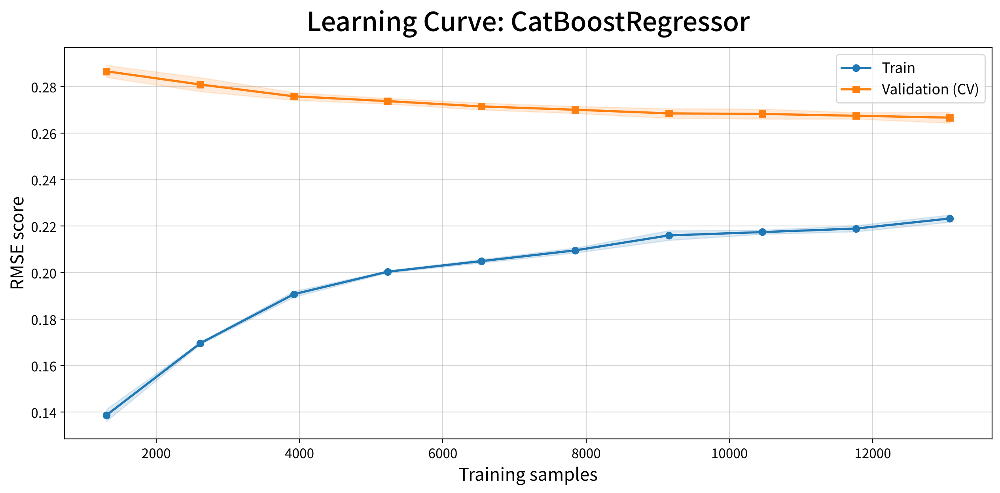


◆ Fit Diagnosis: CatBoostRegressor  (threshold=15%, 기준=Train↔CV 5-Fold)
   ▷ 탐색 객체의 best_params: {'model__depth': 8, 'model__iterations': 1000, 'model__learning_rate': 0.03}
   ※ threshold 는 학술 표준이 아닌 경험칙입니다. 임계값보다 학습곡선 추세를 함께 보세요.
   - RMSE    Train=     0.2280  CV=     0.2666 (±0.0019)  Test=     0.2686  Gap%=   14.49%  [일반화]

   ▶ 진단: ✔ 일반화 (Good fit) — 격차가 작고 훈련 성능도 양호
     · train R2=0.8390 (과소적합 기준 < 0.3) · CV R2=0.7797

CPU times: user 765 ms, sys: 153 ms, total: 918 ms
Wall time: 2min 55s


,Train,CV,CV_Std,Test,Gap,Gap%,Overfit
Metric,,,,,,,
RMSE,0.228,0.267,0.002,0.269,0.039,14.490,일반화


In [85]:
%%time 

model = my_ml.load_model(f"{workdir}/catboost.pkl")
my_ml.reg_overfit(model, x_train, y_train, x_test, y_test, 
                  metrics='RMSE', 
                  fit_params={'model__cat_features': my_qtcheck.get_categorical_column_names(x_train)})

---
##### 💡 인사이트 — 일반화 판정, 교차검증 성능이 처음 보는 데이터에서도 재현된다

| 지표 | Train | CV (5-Fold) | Test | Gap% | 판정 |
|---|---|---|---|---|---|
| RMSE | 0.2280 | 0.2666 (±0.0019) | 0.2686 | **14.49%** | **일반화** (기준 15% 미만) |
| R² | 0.839 | 0.780 | — | — | 과소적합 아님 (≥ 0.3) |

- 학습 성능이 교차검증보다 좋긴 하지만, 격차(14.49%)가 기준(15%) 안이라 **일반화로 판정**된다. 다만 기준에 가까워 여유가 크지는 않다.
- **CV(0.2666)와 Test(0.2686)의 차이가 0.002**로 작다. 교차검증으로 추정한 성능이 처음 보는 데이터에서도 거의 그대로 재현되므로, **이 모델의 일반화 성능 추정은 신뢰할 수 있다.**
- 교차검증 점수의 흔들림(±0.0019)도 작아, 어떤 데이터로 검증해도 성능이 안정적이다.

---

# PART 11. Feature Importance · 변수 축소 재학습

- 누적 중요도 **95%** 까지의 변수만 채택하고, 나머지로 모델을 다시 학습 · 튜닝해 **성능이 유지되는지** 확인한다.

### (1) 최종 모델의 변수 중요도

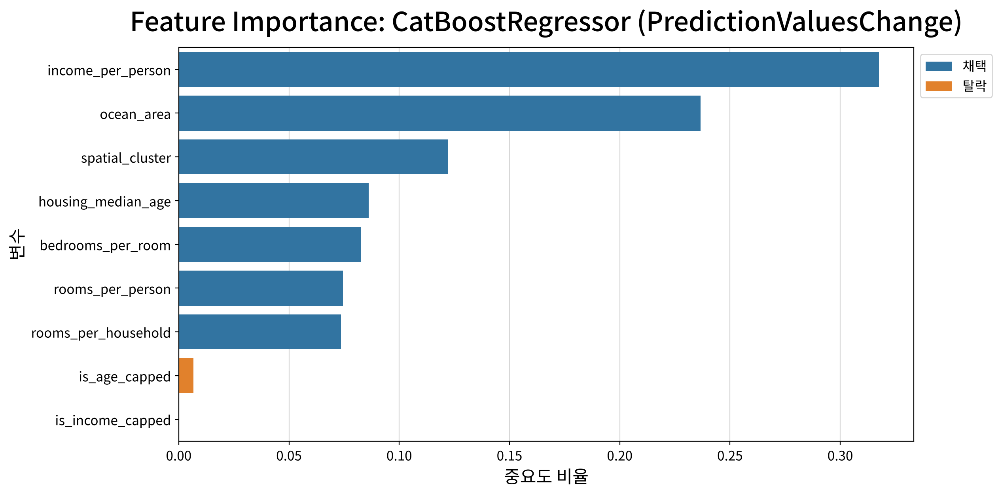


◆ Feature Importance: CatBoostRegressor  (중요도 기준=PredictionValuesChange, 채택 기준=cum_ratio=95%)
   ▷ 탐색 객체의 best_params: {'model__depth': 8, 'model__iterations': 1000, 'model__learning_rate': 0.03}
   전체 변수 9개 중 7개 채택 (누적 중요도 99.32% 설명)
   ▶ 채택된 변수: ['income_per_person', 'ocean_area', 'spatial_cluster', 'housing_median_age', 'bedrooms_per_room', 'rooms_per_person', 'rooms_per_household']



,Importance,Ratio,CumRatio,채택여부
Feature,,,,
income_per_person,31.748,0.317,0.317,채택
ocean_area,23.660,0.237,0.554,채택
spatial_cluster,12.220,0.122,0.676,채택
housing_median_age,8.613,0.086,0.762,채택
bedrooms_per_room,8.281,0.083,0.845,채택
rooms_per_person,7.440,0.074,0.920,채택
rooms_per_household,7.358,0.074,0.993,채택
is_age_capped,0.669,0.007,1.000,탈락
is_income_capped,0.012,0.000,1.000,탈락


In [86]:
model = my_ml.load_model(f"{workdir}/catboost.pkl")
fi = my_ml.feature_importance(model, cum_ratio=0.95)
fi

---
##### 💡 인사이트 — 세 축이 중요도의 68%

- 최종 투입 변수는 **10개 중 7개**

| 순위 | 변수 | 중요도 | 비율 | 누적 | 판정 |
|---|---|---|---|---|---|
| 1 | `income_per_person` | 31.75 | 31.7% | 31.7% | 채택 |
| 2 | `ocean_area` | 23.66 | 23.7% | 55.4% | 채택 |
| 3 | `spatial_cluster` | 12.22 | 12.2% | 67.6% | 채택 |
| 4 | `housing_median_age` | 8.61 | 8.6% | 76.2% | 채택 |
| 5 | `bedrooms_per_room` | 8.28 | 8.3% | 84.5% | 채택 |
| 6 | `rooms_per_person` | 7.44 | 7.4% | 92.0% | 채택 |
| 7 | `rooms_per_household` | 7.36 | 7.4% | 99.3% | 채택 |
| 8 | `is_age_capped` | 0.67 | 0.7% | 100% | 탈락 |
| 9 | `is_income_capped` | 0.01 | 0.0% | 100% | 탈락 |

- **소득 · 해안 입지 · 공간 권역 세 변수가 중요도의 67.6%** 를 차지한다. 주거 구조 변수 4개는 합쳐도 소득 하나에 미치지 못한다.
- **상위 3개가 모두 직접 만든 파생변수**다(`income_per_person` · `ocean_area` · `spatial_cluster`). 특히 1위 · 3위는 원본에 없던 정보(1인당 구매력, 권역)를 새로 만든 변수라, 피처 엔지니어링이 실제 성능에 기여했다는 근거다.
- **상한 절단 플래그 2종은 중요도가 거의 0**이다. 잘린 값의 실제 정보가 사라진 표시라 모델이 쓸 정보가 적었다.
- `population_per_household`는 목록에 없다. 모델 안의 **VIF 단계(≥ 10)에서 이미 제거**돼, 중요도 계산 대상이 9개였다. 

---

### (2) 채택된 변수 추출

In [87]:
# 채택된 변수 목록 (재학습에 사용)
selected = fi.attrs['selected_features']
dropped = [c for c in x_train.columns if c not in selected]

print(f"채택 {len(selected)}개: {selected}")
print(f"탈락 {len(dropped)}개: {dropped}")

채택 7개: ['income_per_person', 'ocean_area', 'spatial_cluster', 'housing_median_age', 'bedrooms_per_room', 'rooms_per_person', 'rooms_per_household']
탈락 3개: ['population_per_household', 'is_age_capped', 'is_income_capped']


### (3) 채택된 변수만 남긴 학습 · 검증 데이터

In [88]:
# 훈련 데이터에서 채택된 변수만 추출
x_tr = x_train[selected]
display(x_tr.columns)

# 검증 데이터에서 채택된 변수만 추출
x_te = x_test[selected]
display(x_te.columns)

Index(['income_per_person', 'ocean_area', 'spatial_cluster',
       'housing_median_age', 'bedrooms_per_room', 'rooms_per_person',
       'rooms_per_household'],
      dtype='str')

Index(['income_per_person', 'ocean_area', 'spatial_cluster',
       'housing_median_age', 'bedrooms_per_room', 'rooms_per_person',
       'rooms_per_household'],
      dtype='str')

### (4) 7개 변수로 베이스 모델 재학습

In [89]:
catboost = my_ml.fit_pipeline(
                model=CatBoostRegressor(random_state=RANDOM_STATE, verbose=0),
                x_train=x_tr, y_train=y_train,
                vif=True, 
                encode=False,   # CatBoost는 자체적으로 범주형 처리하므로 encode=False
                # 이름이 `단계명__인자명` 형식인 인자는 모델의 fit 으로 그대로 전달된다
                model__cat_features=my_qtcheck.get_categorical_column_names(x_tr))

display(my_ml.reg_score(catboost, x_te, y_test))

catboost

대상: 16346행 x 7열 | 모델: catboost
명목형: ['ocean_area', 'spatial_cluster']
연속형: ['income_per_person', 'housing_median_age', 'bedrooms_per_room', 'rooms_per_person', 'rooms_per_household']

전처리 단계
  연속형: 다중공선성 제거(VIF >= 10.0)
  명목형: (변환 없음)



모델 학습 완료: catboost


,R2,MAE,MSE,RMSE,RMSLE,MAPE,MPE
Model,,,,,,,
CatBoostRegressor,0.777,0.197,0.073,0.271,0.021,0.016,-0.000


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](0,)",[]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['income_per_person','ocean_area','spatial_cluster',..., 'bedrooms_per_room','rooms_per_person','rooms_per_household']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
name_,str,'ca...st'
pipeline_info_,dict,"{'ca...te': 'mo...nt', 'co...ls': ['in...on', 'ho...ge', 'be...om', 'ro...on', ...], 'dr...st': False, 'encode': False, ...}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"


### (5) 7개 변수 모델 하이퍼파라미터 튜닝

In [90]:
# 수업용 탐색 조합
param_grid = {
    "model__iterations": [500, 1000],
    "model__depth": [4, 6, 8],
    "model__learning_rate": [0.03, 0.05, 0.1]
}

# 하이퍼파라미터 튜닝 수행
gs = GridSearchCV(estimator=catboost, param_grid=param_grid,
    cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1)

gs.fit(x_tr, y_train,
       model__cat_features=my_qtcheck.get_categorical_column_names(x_tr))

gs.name_ = f"{catboost.name_}_tuned"   # 튜닝이 완료된 객체에게 모델이름을 부여한다.
my_ml.save_model(gs, f"{savedir}/catboost.pkl") # 튜닝이 완료된 모델을 저장한다.
display(my_ml.reg_score(gs, x_te, y_test))      # 성능 평가

,R2,MAE,MSE,RMSE,RMSLE,MAPE,MPE
Model,,,,,,,
CatBoostRegressor,0.781,0.196,0.072,0.268,0.021,0.016,-0.001


### (6) 7개 변수 모델의 과적합 재판정

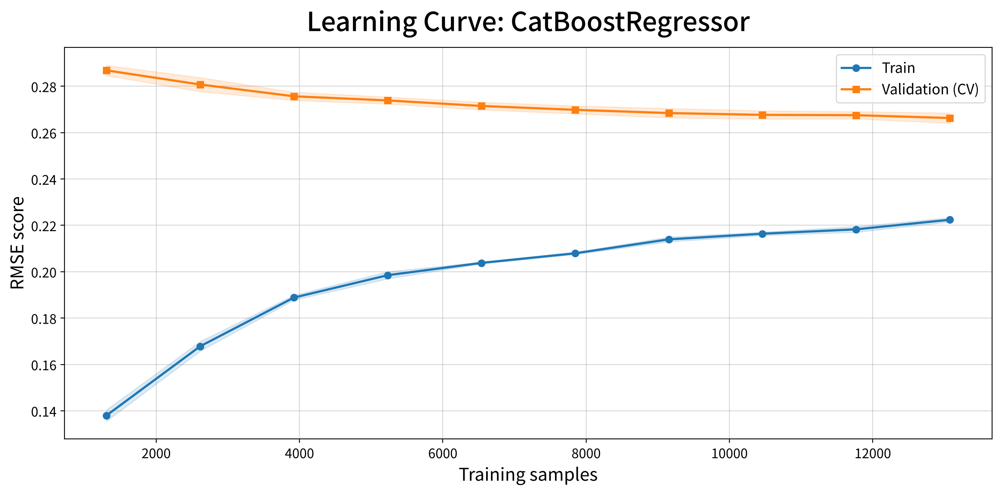


◆ Fit Diagnosis: CatBoostRegressor  (threshold=15%, 기준=Train↔CV 5-Fold)
   ▷ 탐색 객체의 best_params: {'model__depth': 8, 'model__iterations': 1000, 'model__learning_rate': 0.03}
   ※ threshold 는 학술 표준이 아닌 경험칙입니다. 임계값보다 학습곡선 추세를 함께 보세요.
   - RMSE    Train=     0.2273  CV=     0.2662 (±0.0018)  Test=     0.2684  Gap%=   14.60%  [일반화]

   ▶ 진단: ✔ 일반화 (Good fit) — 격차가 작고 훈련 성능도 양호
     · train R2=0.8399 (과소적합 기준 < 0.3) · CV R2=0.7804

CPU times: user 669 ms, sys: 116 ms, total: 785 ms
Wall time: 2min 51s


,Train,CV,CV_Std,Test,Gap,Gap%,Overfit
Metric,,,,,,,
RMSE,0.227,0.266,0.002,0.268,0.039,14.600,일반화


In [91]:
%%time
my_ml.reg_overfit(gs, x_tr, y_train, x_te, y_test, 
                  metrics="RMSE", 
                  fit_params={'model__cat_features': my_qtcheck.get_categorical_column_names(x_tr)})

---
##### 💡 인사이트 — 변수를 줄여도 성능은 그대로, 7개 변수 모델을 최종 채택

| 점검 항목 | 축소 전 (10개) | 축소 후 (7개) | 판정 |
|---|---|---|---|
| 베이스 모델 RMSE | 0.271 | 0.271 | 변화 없음 |
| 튜닝 모델 RMSE (Test) | 0.2686 | 0.2684 | 악화 없음 |
| 튜닝 모델 R² | 0.781 | 0.781 | 유지 |
| 일반화 격차 (Gap%) | 14.49% | 14.60% | +0.11%p — 여전히 일반화 |

- 변수를 3개 줄였는데도 **예측 성능은 그대로**이고, 일반화 판정도 유지됐다.
- 같은 성능이라면 **변수가 적은 모델이 해석하기 쉽고, 운영할 때 수집 · 관리할 변수도 줄어든다.** → **7개 변수 CatBoost를 최종 모델로 채택**한다.
- 남은 약 15%의 격차는 변수를 줄여도, 튜닝을 해도 거의 변하지 않았다. **데이터의 노이즈나 모델 용량의 한계**로 보는 것이 타당하다.
- 최종 사양 : CatBoost · 투입 변수 7개 · depth = 8 · iterations = 1000 · learning_rate = 0.03

---

# PART 12. SHAP 해석

- **분석 흐름** : ① 설명 필요성 → ② Local / Global → ③ Explainer 선택(트리 모델 → `TreeExplainer`) → ④ 표본 · 상관(계산 시간을 위해 200행 표본)

### (1) 전역 영향력 — Bar Plot · Beeswarm

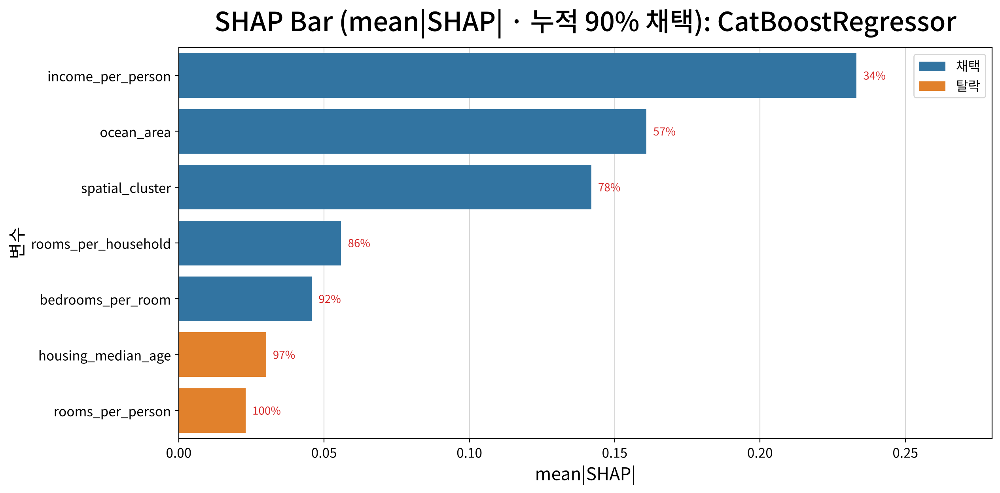

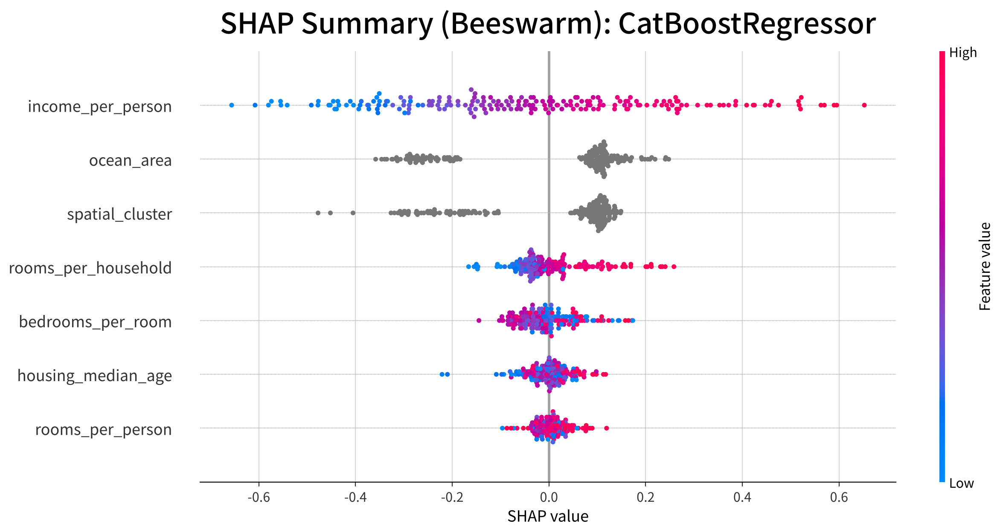


◆ SHAP Analysis: CatBoostRegressor  (TreeExplainer, regression)
   ▷ 탐색 객체의 best_params: {'model__depth': 8, 'model__iterations': 1000, 'model__learning_rate': 0.03}
   설명 표본 200행 × 변수 7개 · base value=12.0859 · SHAP 단위=예측값(y 단위)
   income_per_person      mean|SHAP|=0.2332  방향=감소  비선형/불안정
   ocean_area             mean|SHAP|=0.1609  방향=증가  비선형/불안정
   spatial_cluster        mean|SHAP|=0.1420  방향=감소  비선형/불안정
   rooms_per_household    mean|SHAP|=0.0559  방향=증가  비선형/불안정
   bedrooms_per_room      mean|SHAP|=0.0458  방향=감소  비선형/불안정



In [92]:
# 앞에서 학습 완료한 최종 모델과 데이터 사용
shap = my_ml.shap_analysis(gs, x_tr)

---

##### 💡 인사이트 — Bar Plot · Beeswarm (전역 영향력과 방향)

**① Bar Plot — 전역 영향력 순위**

- **상위 3개가 영향력의 78%** : `income_per_person`(34%) → `ocean_area`(57%) → `spatial_cluster`(78%). 사실상 "소득 · 해안 입지 · 공간 권역" 세 축으로 가격이 결정된다.
- **누적 90% 기준 채택 5개 / 탈락 2개** : `rooms_per_household`(86%) · `bedrooms_per_room`(92%)까지 채택되고, `housing_median_age` · `rooms_per_person`은 탈락했다.
- **Feature Importance와 상위 3개 순서가 같다**(소득 → 해안 입지 → 공간 권역). 서로 다른 두 지표가 같은 결론을 내므로 변수 선택이 견고하다.
- **효과 크기 감각** : 종속변수가 로그 값이므로 `income_per_person`의 mean|SHAP| 0.233은 평균적으로 e^0.233 ≈ **약 ±26%의 가격 차이**를 만든다는 뜻이다.

**② Beeswarm — 방향과 분포**

- **`income_per_person`은 명확한 증가 관계** : 빨강(고소득)이 오른쪽(+0.65까지), 파랑(저소득)이 왼쪽(−0.65까지)에 있다. 좌우로 가장 넓게 퍼져 개별 예측의 차이를 가장 크게 만드는 변수다.
- **`ocean_area` · `spatial_cluster`가 회색인 이유는 범주형이기 때문**이다. 두 변수 모두 SHAP 값이 **음의 덩어리와 양의 덩어리로 분리**되는 전형적인 범주 효과를 보인다.
- **입지 변수는 효과가 비대칭이다** : `ocean_area` · `spatial_cluster` 모두 가격을 내리는 쪽이 올리는 쪽보다 크다.
  - `ocean_area` : 내륙은 −0.18 ~ −0.36으로 끌어내리고, 해안권은 +0.06 ~ +0.25로 올린다.
  - `spatial_cluster` : 내리는 권역은 −0.1 ~ −0.48, 올리는 권역(LA · 베이)은 +0.05 ~ +0.15다.
  - → **좋은 입지의 프리미엄보다 불리한 입지의 페널티가 더 크다.**
- **하위 4개(`rooms_per_household` · `bedrooms_per_room` · `housing_median_age` · `rooms_per_person`)는 대부분 0 근처(±0.1 안쪽)에 몰려 있다.** 상위 3개에 비해 예측에 주는 영향이 작다.
  - 다만 `rooms_per_household`는 **큰 값(빨강) 일부가 +0.25까지** 길게 뻗는다. 방이 아주 많은 일부 구역에서만 가격을 크게 올린다.
  - `bedrooms_per_room`은 양쪽 끝에 **큰 값과 작은 값이 섞여** 있어, 한 방향의 관계가 아니다 → Dependence Plot에서 모양을 확인한다.

**종합**

- 모델은 **소득 + 입지(해안 · 권역)** 로 가격의 8할을 설명하고, 주거 구조 변수는 미세 조정 역할에 그친다.

---

### (2) Dependence Plot — 변수 값에 따른 기여도의 모양

- 점 하나가 구역 하나다. **가로축**은 변수 값, **세로축**은 그 값이 집값 예측을 얼마나 올리고 내렸는지(SHAP), **색**은 다른 변수 하나의 값이다.
- 색을 보는 법
  - 왼쪽에서 오른쪽으로 갈수록 **색이 바뀌면** → 두 변수가 함께 움직일 뿐이다(상관).
  - **같은 가로 위치에서 색이 위아래로 갈리면** → 색으로 표시한 변수가 효과의 크기를 바꾼다(상호작용).

◆ SHAP Dependence — 변수쌍(주변수 × 상호작용변수) · 선정기준=cum_ratio=90%
   income_per_person  ×  rooms_per_household
   ocean_area  ×  spatial_cluster
   spatial_cluster  ×  income_per_person
   rooms_per_household  ×  bedrooms_per_room
   bedrooms_per_room  ×  rooms_per_household


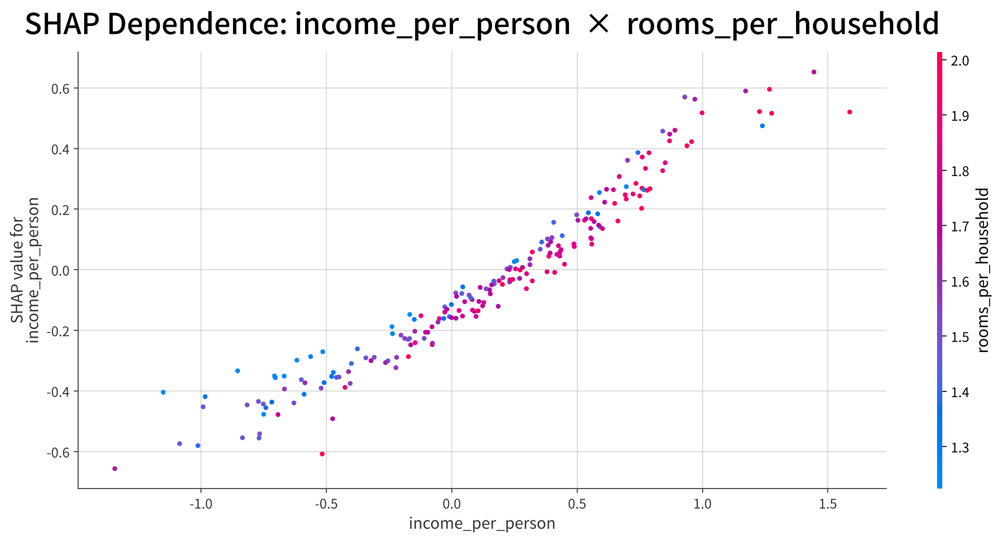

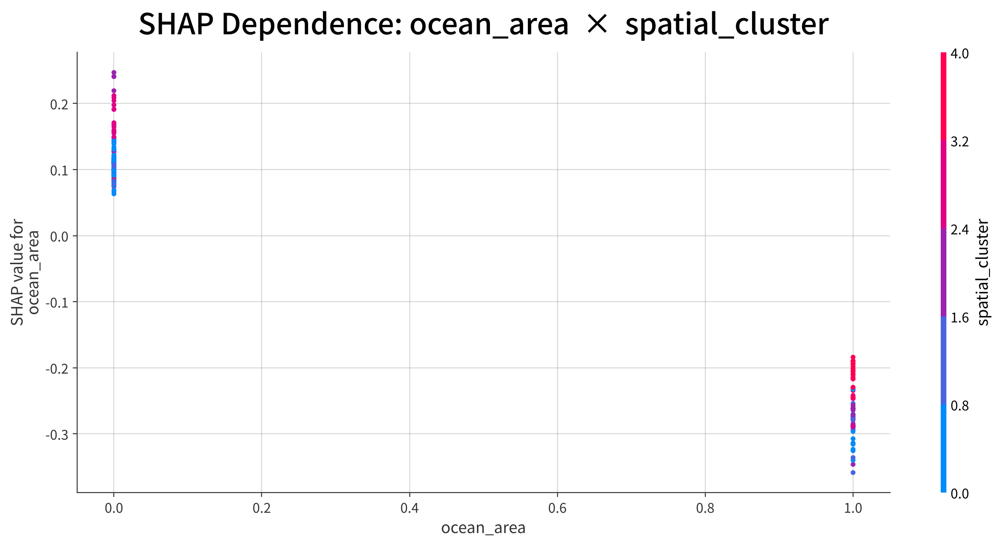

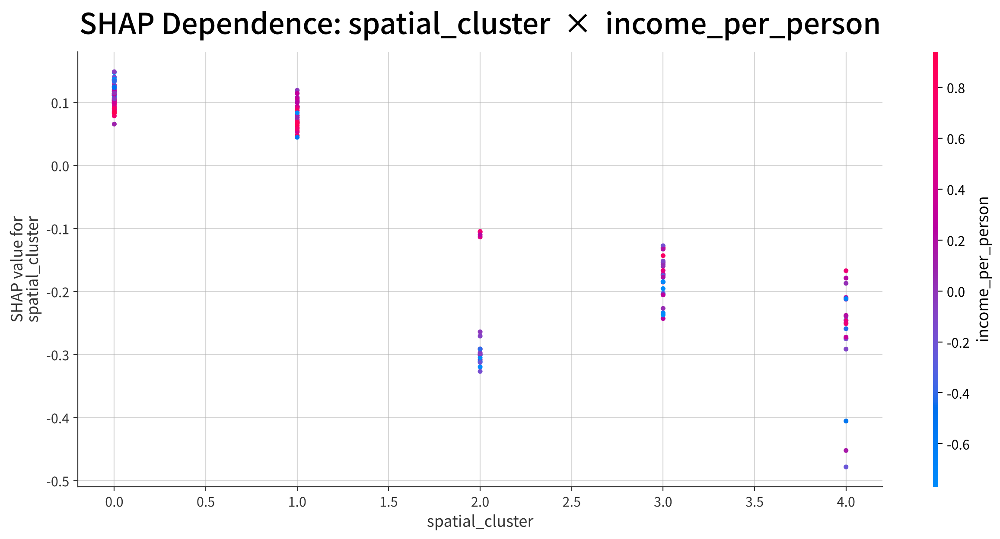

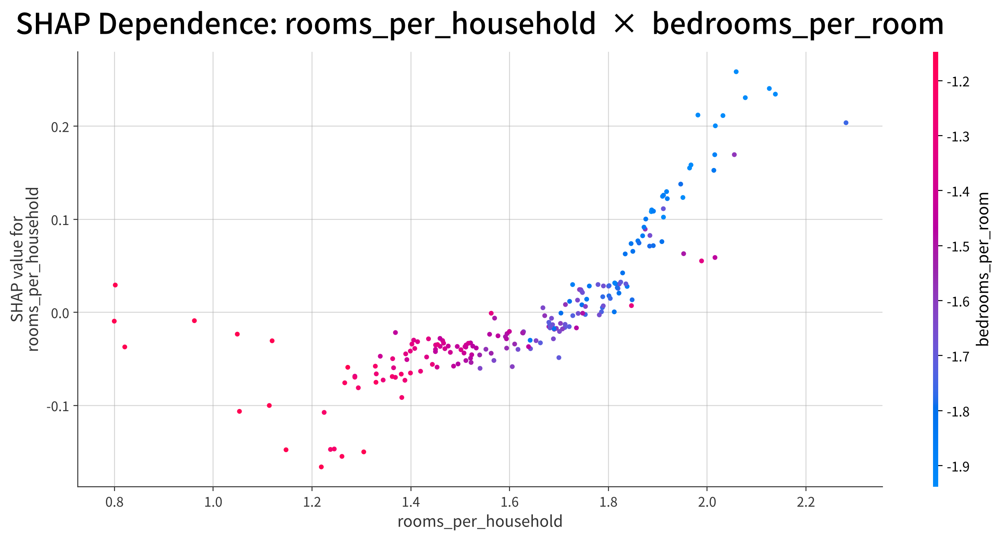

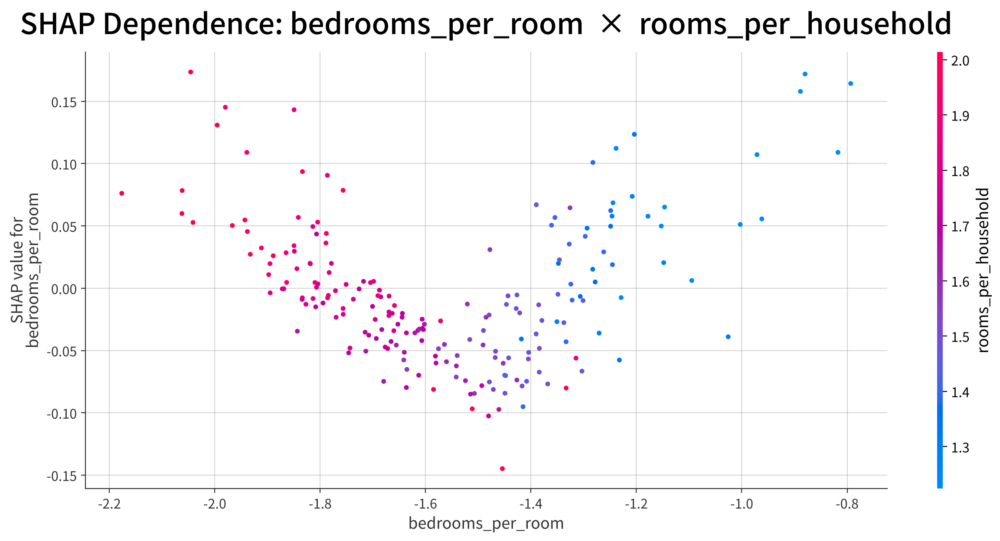

[{'feature': 'income_per_person',
  'interaction_feature': 'rooms_per_household'},
 {'feature': 'ocean_area', 'interaction_feature': 'spatial_cluster'},
 {'feature': 'spatial_cluster', 'interaction_feature': 'income_per_person'},
 {'feature': 'rooms_per_household',
  'interaction_feature': 'bedrooms_per_room'},
 {'feature': 'bedrooms_per_room',
  'interaction_feature': 'rooms_per_household'}]

In [93]:
# 데이터는 shap.attrs 에서 읽으므로 훈련데이터를 넘기지 않는다.
# features 를 비워야 cum_ratio/top_k 자동선정이 동작한다.
my_ml.shap_dependence_plot(shap)

---
##### 💡 인사이트 — Dependence Plot

**① `income_per_person` × `rooms_per_household` — 거의 직선인 증가**
- 소득이 높을수록 SHAP이 −0.65에서 +0.65까지 꾸준히 올라간다. 점들이 **좁은 띠 하나**로 모여 있다.
- 색은 왼쪽에서 오른쪽으로 갈수록 바뀐다(소득이 높은 구역일수록 방이 많은 편) → 두 변수가 함께 움직일 뿐, **상호작용은 보이지 않는다.**

**② `ocean_area` × `spatial_cluster` — 내륙의 벌점이 해안의 가점보다 크다**
- 해안권(0)은 +0.06 ~ +0.25, 내륙(1)은 −0.18 ~ −0.36으로 **두 그룹이 겹치지 않는다.**
- 내륙의 중심(약 −0.27)은 약 **−24%**, 해안권의 중심(약 +0.11)은 약 **+12%** 에 해당한다(로그 환산). 불리한 입지의 벌점이 좋은 입지의 가점보다 약 2배 크다.
- 내륙 안에서도 빨강 점(권역 번호가 큰 쪽)은 −0.2 안팎, 파랑 점(번호가 작은 쪽)은 −0.3 안팎으로 **위아래로 갈린다** → 권역에 따라 벌점 크기가 달라지는 **약한 상호작용**이다.

**③ `spatial_cluster` × `income_per_person` — 권역이 둘로 나뉜다**
- **0번(LA) · 1번(베이) 권역은 가격을 올리고**(+0.05 ~ +0.15), **2번(센트럴밸리) · 3번(샌디에이고) · 4번(북부 내륙)은 내린다**(−0.1 ~ −0.48). 
- 2번 권역은 대부분 −0.30 부근인데, **소득이 높은 구역(빨강)은 −0.1 부근**으로 위에 따로 있다 → 같은 권역이라도 소득이 높으면 벌점이 작아지는 **상호작용**이다.
- 4번 권역은 −0.17 ~ −0.48로 **퍼진 폭이 가장 크다.** 다만 2번 · 4번은 찍힌 점이 적어 수치를 단정하기 어렵다.

**④ `rooms_per_household` × `bedrooms_per_room` — 일정 수준을 넘어야 오른다**
- 1.3 ~ 1.7 구간은 −0.03 ~ −0.07에서 거의 평평하다가, **약 1.8을 넘으면 가파르게 올라** +0.25까지 간다.
- 색은 왼쪽에서 오른쪽으로 갈수록 바뀐다(방이 많을수록 침실 비율이 낮은 편) → 주로 두 변수가 함께 움직이는 **상관**이다.
- 왼쪽 끝(1.2 미만)은 점이 적어 추세를 해석하지 않는다.

**⑤ `bedrooms_per_room` × `rooms_per_household` — 뚜렷한 U자**
- 중앙(−1.5 부근)에서 −0.05 ~ −0.10으로 가장 낮고, **양 끝으로 갈수록 올라가** +0.1 이상이 된다. 침실 비율이 '중간'인 구역이 오히려 가격에 마이너스다.
- 색은 왼쪽(침실 비율이 낮은 쪽)이 빨강(방이 많음), 오른쪽(침실 비율이 높은 쪽)이 파랑(방이 적음)이다 → U자의 양 끝은 **방 구성이 서로 다른 구역**이다.

**종합**
- ①은 다른 변수와 상관없이 소득만으로 정해지는 효과, ②③은 **입지 변수 안의 약한 상호작용**(같은 내륙 · 같은 권역이라도 벌점 크기가 다름)이다.
- **비선형 패턴 2건** : ④의 '일정 수준을 넘어야 오르는' 모양과 ⑤의 U자. 직선을 가정하는 선형회귀로는 잡을 수 없는 모양이다.

---

# 📌 결론

### 1. 연구 질문별 답변

| 질문 | 근거 | 답 |
|---|---|---|
| **① 이 모형의 예측을 실무에 쓸 수 있는가?** | 평가 R² 0.781 · CV RMSE 0.2662 ↔ Test RMSE 0.2684 · CV 편차 ±0.0018 · 일반화 판정(Gap 14.60%) | **쓸 수 있다.** 교차검증과 처음 보는 데이터의 성능이 거의 일치해 새 데이터에서도 비슷한 성능이 재현될 것으로 본다. 다만 평균 ±22% 수준의 오차를 전제로 한 용도에 한한다 |
| **② 주택가격을 좌우하는 요인은 무엇인가?** | 중요도 상위 3개 누적 67.6% · SHAP 상위 3개 누적 78% · 두 지표의 상위 3개 순서 일치 | **`income_per_person` · `ocean_area` · `spatial_cluster` 세 축**이 지배한다. 주거 구조 변수는 합쳐도 미세 조정 역할에 그친다 |
| **③ 그 요인은 어느 방향, 어떤 모양으로 작동하는가?** | Beeswarm의 방향 분포 · Dependence Plot 5종 | **소득은 단조 증가**, **입지는 불연속적 이분**(내륙 약 −24% vs 해안 약 +12%), **주거 구조는 비선형**(방 수의 임계효과, 침실 비율의 U자) |

### 2. 핵심 인사이트

- **입지 효과의 비대칭** : 해안권이라서 오르는 폭(약 +12%)보다 **내륙이라서 내려가는 폭(약 −24%)이 약 2배 크다.** 권역으로 봐도 LA · 베이 권역만 집값을 올리고, 나머지 세 권역은 모두 내린다.
- **파생변수의 기여** : 영향력 상위 3개가 **모두 직접 만든 파생변수**다(`income_per_person` · `ocean_area` · `spatial_cluster`). 특히 1위 · 3위는 원본에 없던 정보(1인당 구매력, 권역)를 새로 만든 변수다.
- **비선형 구조** : 가구당 방 수는 **일정 수준(로그 값 약 1.8)을 넘어야** 가격을 올리고, 침실 비율은 **중간일 때 가장 불리한 U자**다 — 선형 모델로는 잡을 수 없는 패턴이다.
- **방법론** : RMSE 순위만 보지 않고 **근소 격차 그룹 · 보조 지표 결함 · 일반화(과적합 판정)** 까지 확인해 최종 모형을 골랐다. 변수를 30% 줄여도 성능이 유지되자 해석이 쉬운 7개 변수 모델을 택했다.

### 3. 활용 방안 — 개별 가격 확정이 아니라, 가격대를 좁히고 근거를 제시하는 도구

| 단계 | 활용 | 내용 |
|---|---|---|
| STEP 1 | **1차 스크리닝** | 새 지역의 소득 · 입지 · 주거 구조(7개 변수)만 넣어 **예상 가격대**를 빠르게 계산하고, 정밀 조사할 지역을 추린다 |
| STEP 2 | **이상치 탐지** | 모델의 예상 가격과 **실제 가격이 크게 다른 지역**을 찾아 먼저 확인한다 | 
| STEP 3 | **설명 자료 생성** | 지역별 예측 가격을 **SHAP 기여도로 나눠** "왜 이 가격인지" 보여 준다 | 

- 투입 변수가 7개라 **수집 · 관리 부담이 낮고**, 영향력의 78%가 3개 변수에 몰려 있어 **최소한의 정보로 1차 가격대 추정**이 가능하다.

### ⚠️ 한계

**모형의 한계**
- **학습 ↔ 교차검증 격차 약 15%가 남아 있다.** 일반화 기준 안이지만 여유가 크지 않고, 변수 축소 · 튜닝으로도 거의 줄지 않아 데이터 노이즈나 모델 용량의 한계로 본다.
- **평균 ±22% 수준의 오차**가 남는다(MAE 0.196을 원래 단위로 환산). R² 0.781은 집값 변동의 약 22%를 설명하지 못한다는 뜻이다. 그래서 개별 물건의 가격 확정 용도로는 부적합하다.
- **최종 모델을 평가 데이터 점수로 골랐다.** 같은 데이터로 성능을 보고했기 때문에 성능이 약간 낙관적일 수 있다. 다만 교차검증 RMSE(0.266)와 평가 RMSE(0.268)가 거의 같아 그 차이는 작을 것으로 보인다.
- **SHAP은 설명이지 인과가 아니다.** "해안이라서 집값이 오른다"가 아니라 **"모델이 해안 정보를 크게 활용했다"** 가 정확한 표현이다.

**데이터의 한계**
- **일부 구간은 표본이 부족하다.** SHAP 표본 200행 중 2번(센트럴밸리) · 4번(북부 내륙) 권역은 점이 적고, `rooms_per_household`가 로그 값 1.2 미만(가구당 방 약 3개 미만)인 구간은 10개 남짓이라 해석을 유보했다.
- **상한 절단 플래그 2종의 중요도가 0에 가깝다.** 상한에서 잘린 값은 실제 값 정보가 사라져, 모델이 쓸 정보가 적었던 것으로 보인다.
- **종속변수가 로그 변환**되어 있어 RMSE · MAE를 달러 단위로 직접 읽을 수 없다.
- **1990년 인구조사 데이터**라 현재 주택시장과는 가격 수준과 구조가 다를 수 있다.

### ⏭️ 후속 과제

| 한계 | 과제 |
|---|---|
| 일부 권역의 표본 부족 | 2번(센트럴밸리) · 4번(북부 내륙) 권역의 원 데이터 규모로 SHAP을 다시 계산하고, 부족하면 해당 구간의 해석을 보고서에서 제외한다 |
| 격차가 줄지 않는 구간 | 관측치를 늘리기보다 **새로운 변수**(접근성 · 공간 특성 등)를 우선 발굴한다 |
| 비선형 발견 2건의 재현성 | 방 수의 임계효과(로그 값 약 1.8)와 침실 비율의 U자 패턴이 **다른 표본에서도 재현되는지** 검증한다 |
| 인과 해석 불가 | 인과 해석이 필요하면 SHAP이 아니라 **별도의 인과 추론 설계**를 적용한다 |

### ✅ 최종 모델
| 항목 | 값 |
|---|---|
| 모델 | CatBoost 회귀 (depth = 8 · iterations = 1000 · learning_rate = 0.03) |
| 투입 변수 (7개) | `income_per_person` · `ocean_area` · `spatial_cluster` · `housing_median_age` · `bedrooms_per_room` · `rooms_per_person` · `rooms_per_household` |
| 성능 (평가 데이터) | RMSE 0.268 · MAE 0.196 · R² 0.781 (로그 단위 · 평균 약 ±22% 가격 오차) |
| 일반화 | CV RMSE 0.266 ↔ Test RMSE 0.268 · Gap% 14.60% (일반화) |
| 가장 큰 영향 | `income_per_person` (mean\|SHAP\| 0.233, 영향력의 34%) |